In [3]:
%load_ext autoreload
%autoreload 1

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
import os
import pandas as pd
import numpy as np
import scipy
from scipy.stats import spearmanr

import matplotlib as mpl
from matplotlib import pyplot as plt
from matplotlib import rc
import seaborn as sns
import Bio.PDB
from scipy import stats
from Bio.PDB import SASA # SASA module won't load from newest version of Biopython for some reason
# import Geometry # Biopython Geometry module still not on main branch

import time
import sys
import glob
sys.path.append('/data/mhoffert/fiererlab/adenylate_kinase_ogt/protein_utils/')
from collections import Counter

# import Geometry

from IPython.display import display, clear_output

In [5]:
from __future__ import print_function
import warnings
warnings.filterwarnings('ignore') # make the notebook nicer


# import os
# os.environ['QT_QPA_PLATFORM']='offscreen'

import nglview as nv
import pytraj as pt

print("nglview version = {}".format(nv.__version__))
print("pytraj version = {}".format(pt.__version__))

from Bio.PDB import PDBParser, Select, PDBIO, Polypeptide
from Bio.SeqUtils import seq1
from Bio import SeqIO

nglview version = 3.1.1
pytraj version = 2.0.6


In [6]:
import IPython

In [7]:
%%javascript
IPython.OutputArea.prototype._should_scroll = function(lines) {
    return false;
}

<IPython.core.display.Javascript object>

In [8]:
# from utils import read_pfam_table_pandas

In [9]:
sys.path.append('/data/mhoffert/fiererlab/adenylate_kinase_ogt/')
from src.protein_utils.adk_drawer import get_guiding_structures, ss_to_domains, draw_adk, compute_domains, nw

ss_cmap = {'H':'red', 'E':'blue', 'L':'gray'}
domain_cmap = {'core':'red', 'lid':'blue', 'nmp':'green', 'none':'gray', 'ploop':'yellow'}
nglview_list = lambda cmap, residue_ss: [[cmap[r], str(i)] for i, r in enumerate(residue_ss)]

# Loading structural metrics

In [11]:
metrics_df = pd.read_csv('/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/metric_tables/20260513_full_metrics.tsv.gz', 
                         compression='gzip', sep='\t', index_col=0)
# fix bug in metrics df
metrics_df['lidded'] = ~metrics_df['lidded']
# filtered = pd.read_csv('/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/metric_tables/20240327_metrics_df_filtered.tsv.gz', sep='\t', index_col=0)

# Plotting correlations with OGT

## Plot of lid types versus temperature

In [12]:
def classify_lid_type(row):
    if row['lidded']:
        if row['zinc']:
            return 'zinc'
        elif row['hbond']:
            return 'hbond'
        else:
            return 'other'
    else:
        return 'lidless'


In [13]:
plotdf = metrics_df[['temp', 'zinc', 'lidded', 'hbond']].copy(deep=True)
# plotdf['lidded'] = ~plotdf['lidded']

In [14]:
plotdf['lid_type'] = plotdf.apply(lambda row: classify_lid_type(row), axis=1)

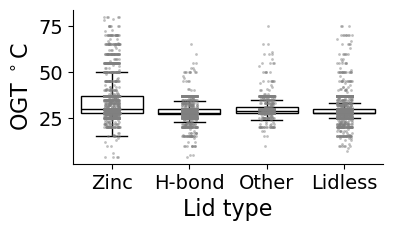

In [90]:
fig, ax = plt.subplots(figsize=(4,2))
sns.boxplot(data=plotdf,
           x='lid_type', y='temp', 
           color='white', linecolor='k', showfliers=False,
           order=['zinc', 'hbond', 'other', 'lidless']
           )

sns.stripplot(data=plotdf,
           x='lid_type', y='temp', 
           color='gray', alpha=0.5, s=2,
           order=['zinc', 'hbond', 'other', 'lidless']
           )

sns.despine()

ax.set_ylabel(r'OGT $^\circ$C', fontsize=16)

ax.set_xlabel("Lid type", fontsize=16)
ax.set_xticks(['zinc', 'hbond', 'other', 'lidless'])
ax.set_xticklabels(['Zinc', 'H-bond', 'Other', 'Lidless'])
plt.tick_params(labelsize=14, axis='both')
plt.savefig('./../data/figures/temp_vs_lid_type.svg', bbox_inches='tight')
# plt.savefig('./../data/figures/')

#### Notes
Is this different significant?

In [27]:
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multicomp import MultiComparison
import statsmodels.api as sm
import statsmodels.stats.weightstats as ws

In [28]:
# levene's test for normality


# Group the variable by your category column
groups = [group["temp"].values for name, group in plotdf.groupby("lid_type")]

# Run Levene's Test
stat, p_val = stats.levene(*groups)
print(f"Levene's Test p-value: {p_val}")

# welch
# 'use_var="unequal"' forces the Welch correction for heteroscedasticity
welch_result = anova_oneway(data=plotdf['temp'], 
                            groups=plotdf['lid_type'], 
                            use_var='unequal')

print(welch_result)

Levene's Test p-value: 2.4639090949127218e-57
statistic = 129.72208661026718
pvalue = 8.374771498634492e-80
df = (3.0, 3608.7480274285253)
df_num = 3.0
df_denom = 3608.7480274285253
nobs_t = 8532.0
n_groups = 4
means = [28.92487194 29.93569636 30.63438735 33.43495146]
nobs = [1757. 3188. 1012. 2575.]
vars_ = [27.39184687 36.55406895 30.94631387 98.72915865]
use_var = unequal
welch_correction = True
tuple = (129.72208661026718, 8.374771498634492e-80)


In [29]:
# Set up the comparison
mc = MultiComparison(plotdf['temp'], plotdf['lid_type'])

# Define a custom wrapper function for Welch's t-test
def welch_ttest(x1, x2):
    # usevar='unequal' forces the Welch correction
    return ws.ttest_ind(x1, x2, usevar='unequal')

# Pass the custom function into allpairtest
posthoc = mc.allpairtest(welch_ttest, method='holm')

print(posthoc[0])

Test Multiple Comparison welch_ttest 
FWER=0.05 method=holm
alphacSidak=0.01, alphacBonf=0.008
 group1  group2   stat    pval  pval_corr reject
------------------------------------------------
  hbond lidless  -6.1453    0.0       0.0   True
  hbond   other   -7.956    0.0       0.0   True
  hbond    zinc -19.4206    0.0       0.0   True
lidless   other  -3.4074 0.0007    0.0007   True
lidless    zinc -15.6793    0.0       0.0   True
  other    zinc -10.6677    0.0       0.0   True
------------------------------------------------


#### Notes:
apparently, but I'm a little suspicious

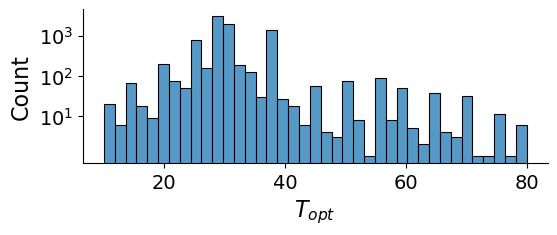

In [30]:
fig, ax = plt.subplots(figsize=(6,2))
sns.histplot(metrics_df['temp'], bins=np.linspace(10,80,40))
ax.set_ylabel('Count', fontsize=16)
ax.set_xlabel('$T_{opt}$', fontsize=16)
ax.set_yscale('log')
ax.set_yticks([10, 100, 1000])
plt.tick_params(labelsize=14)

sns.despine()

plt.savefig('./../data/figures/Topt_dist.png', dpi=400, bbox_inches='tight')

In [46]:
# plot_filenames = {col_name: col_name.replace(' ','_').strip('Å²()_').replace('Δ','d').replace('%','percent_') for col_name in metrics_df.columns}
# metrics_to_plot = [metric for metric in metrics_df.columns if 'Å' in metric or 'SASA' in metric]
# metrics_to_plot = metrics_to_plot + [metric for metric in metrics_df.columns if '%' in metric or 'internal_hbonds' in metric or 'sasa' in metric]
# metrics_to_plot = metrics_to_plot + ['cav_vol', 'packstat',  'avg_deg_4_5', 'avg_deg_8', 'avg_sc_nbrs_res_summary', 'avg_cc_contacts_per_res']
# print(metrics_to_plot)
metrics_to_plot = list(metrics_df.columns)
metrics_to_plot.remove('aligned_structure_len')
include_legend = False

In [47]:
# additional_metrics =  ['dslf_fa13',
#  'fa_atr',
#  'fa_dun',
#  'fa_elec',
#  'fa_intra_rep',
#  'fa_intra_sol_xover4',
#  'fa_rep',
#  'fa_sol',
#  'hbond_bb_sc',
#  # 'hbond_lr_bb',
#  'hbond_sc',
#  'hbond_sr_bb',
#  'lk_ball_wtd',
#  'omega',
#  'p_aa_pp',
#  'pro_close',
#  'rama_prepro',
#  'ref',
#  'total_cc_contacts',
#  'yhh_planarity',]

In [48]:
len(metrics_to_plot)

40

In [49]:
metrics_to_plot

['mean_total_sasa_fs',
 'mean_polar_sasa_fs',
 'mean_apolar_sasa_fs',
 'mean_delta_sasa',
 'mean_norm_delta_sasa',
 'mean_contacts_at_4.5',
 'total_total_sasa_fs',
 'total_polar_sasa_fs',
 'total_apolar_sasa_fs',
 'total_delta_sasa',
 'total_norm_delta_sasa',
 'total_contacts_at_4.5',
 'MM',
 'MS',
 'SM',
 'SS',
 'total',
 'bb-sc',
 'lidded',
 'zinc',
 'hbond',
 'total_score',
 'avg_deg_4_5',
 'avg_deg_8',
 'avg_sc_nbrs_res_summary',
 'bb_internal_hbonds',
 'bbsc_internal_hbonds',
 'calc_bsa_apolar',
 'calc_bsa_total',
 'cav_vol',
 'internal_hbonds',
 'nonpolar_sasa',
 'packstat',
 'polar_sasa',
 'sasa',
 'sc_internal_hbonds',
 'total_cc_contacts',
 'length',
 'avg_cc_contacts_per_res',
 'temp']

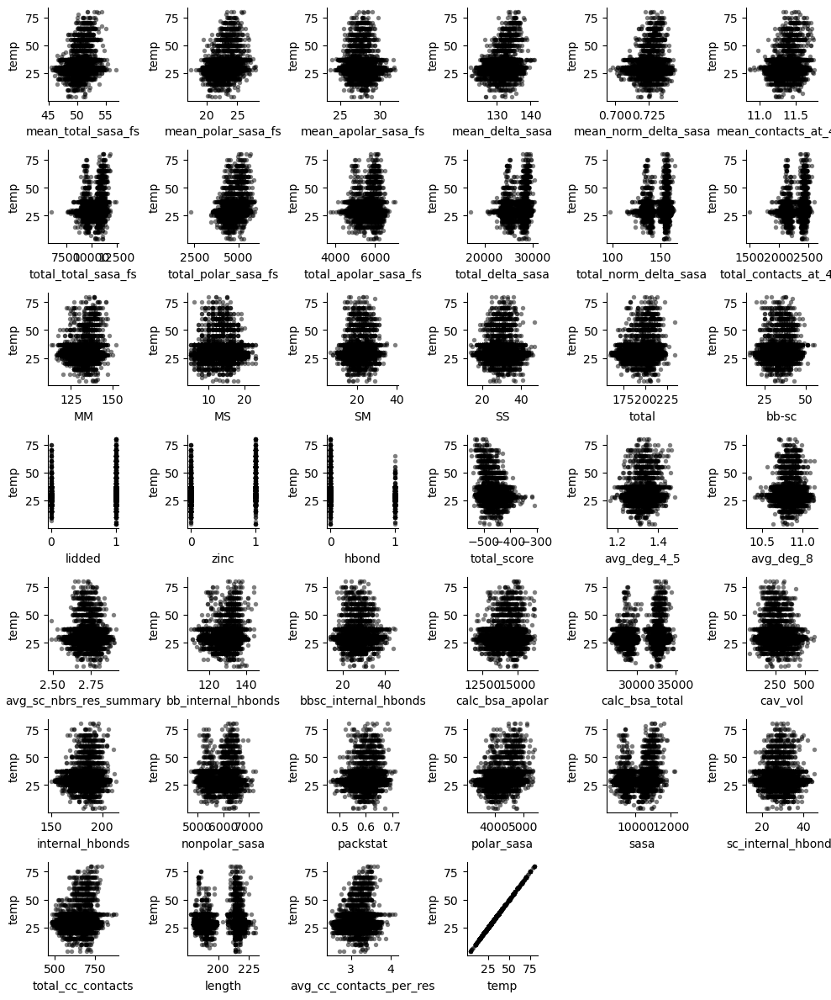

In [50]:
# first, plotting after filtering
fig = plt.figure(figsize=(10, 12))
for i, metric in enumerate(metrics_to_plot):
    ax = fig.add_subplot(7,6,i+1)
    sns.scatterplot(data=metrics_df, x=metric, y='temp', edgecolor=None, color='black', s=15,
                    linewidth=0, alpha=0.5, 
                    # hue=metrics_df.uid.isin(filtered.uid), 
                    # palette=['red', 'k']
                   )
    # ax.get_legend().remove()
    # lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), title='filtered')

    sns.despine(fig)
    plt.tight_layout()


# plt.savefig('./../data/figures/correlations_filtering.png', dpi=400, bbox_inches='tight')

#### Notes
some need to be normalized by length, but does length normalization make them equal to the averages?

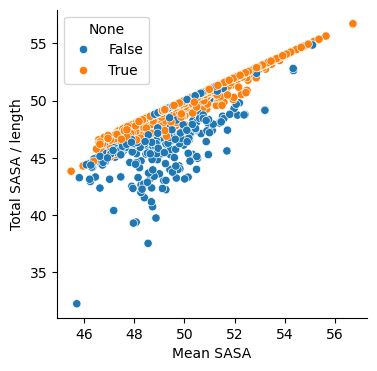

In [53]:
# two questions: are the length-normalized values the same as the mean values?
fig, ax = plt.subplots(figsize=(4,4))
sns.scatterplot(x=metrics_df['mean_total_sasa_fs'],
                y=metrics_df['total_total_sasa_fs'] / metrics_df['length'],
               hue=metrics_df['aligned_structure_len'] / metrics_df['length'] > 0.95)
ax.set_xlabel('Mean SASA')
ax.set_ylabel('Total SASA / length')
sns.despine()

## More specific plots

### SASAs

In [58]:
for j, metric in enumerate(metrics_to_plot):
    if 'sasa' in metric:
        print(metric)

mean_total_sasa_fs
mean_polar_sasa_fs
mean_apolar_sasa_fs
mean_delta_sasa
mean_norm_delta_sasa
total_total_sasa_fs
total_polar_sasa_fs
total_apolar_sasa_fs
total_delta_sasa
total_norm_delta_sasa
nonpolar_sasa
polar_sasa
sasa


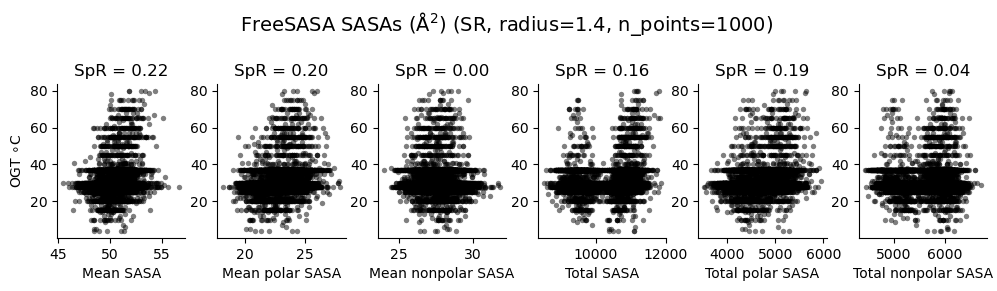

In [179]:
# first, plotting after filtering
fig = plt.figure(figsize=(12, 2))
i =  1

fs_metrics = ['mean_total_sasa_fs',
              'mean_polar_sasa_fs',
              'mean_apolar_sasa_fs',
              'total_total_sasa_fs',
              'total_polar_sasa_fs',
              'total_apolar_sasa_fs']

unit = r'($\mathrm{\AA}^{2}$)'

labels = ['Mean SASA',
         'Mean polar SASA',
         'Mean nonpolar SASA',
         'Total SASA',
         'Total polar SASA',
         'Total nonpolar SASA']


for i, (metric, label) in enumerate(zip(fs_metrics, labels)):
    ax = fig.add_subplot(1,6,i+1)
    sns.scatterplot(data=metrics_df[metrics_df['aligned_structure_len'] / metrics_df['length'] > 0.95], 
                    x=metric, 
                    y='temp', edgecolor=None, color='black', s=15,
                    # hue=,
                    linewidth=0, alpha=0.5, 
                    # hue=metrics_df.uid.isin(filtered.uid), 
                    # palette=['red', 'k']
                   )
    # ax.get_legend().remove()
    # lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), title='filtered')
    
    if i == 0:
        ax.set_ylabel('OGT $\circ$C')
    else:
        ax.set_ylabel('')
    spr= spearmanr(metrics_df[metric], 
                   metrics_df['temp'])[0]
    ax.set_title(f'SpR = {spr:.2f}')
    ax.set_xlabel(label)
    sns.despine()
    # plt.tight_layout()
fig.subplots_adjust(wspace=0.25)
title = fig.suptitle(f'FreeSASA SASAs {unit} (SR, radius=1.4, n_points=1000)', y=1.25, fontsize=14)
plt.savefig('./../data/figures/freesasa_sasas.svg', bbox_inches='tight')

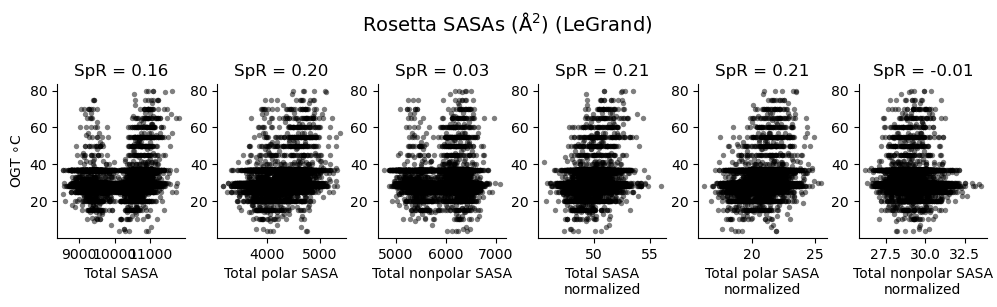

In [152]:
# rosetta
# first, plotting after filtering
fig = plt.figure(figsize=(12, 2))
i =  1

rosetta_metrics = ['sasa',
            'polar_sasa',
            'nonpolar_sasa',
            'sasa',
            'polar_sasa',
            'nonpolar_sasa']

unit = r'($\mathrm{\AA}^{2}$)'

labels = ['Total SASA',
         'Total polar SASA',
         'Total nonpolar SASA',
         'Total SASA\nnormalized',
         'Total polar SASA\nnormalized',
         'Total nonpolar SASA\nnormalized']


for i, (metric, label) in enumerate(zip(rosetta_metrics, labels)):
    ax = fig.add_subplot(1,6,i+1)
    if i < 3:
        _x = metrics_df[metric]
    else:
        _x = metrics_df[metric] / metrics_df['length']
    sns.scatterplot(data=metrics_df[metrics_df['aligned_structure_len'] / metrics_df['length'] > 0.95], 
                    x=_x, 
                    y='temp', edgecolor=None, color='black', s=15,
                    # hue=,
                    linewidth=0, alpha=0.5, 
                    # hue=metrics_df.uid.isin(filtered.uid), 
                    # palette=['red', 'k']
                   )
    # ax.get_legend().remove()
    # lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), title='filtered')
    if i == 0:
        ax.set_ylabel('OGT $\circ$C')
    else:
        ax.set_ylabel('')
    spr= spearmanr(_x, metrics_df['temp'])[0]
    ax.set_title(f'SpR = {spr:.2f}')
    ax.set_xlabel(label)
    sns.despine()
    # plt.tight_layout()
fig.subplots_adjust(wspace=0.25)
title = fig.suptitle(f'Rosetta SASAs {unit} (LeGrand)', y=1.25, fontsize=14)
plt.savefig('./../data/figures/rosetta_sasas.svg', bbox_inches='tight')

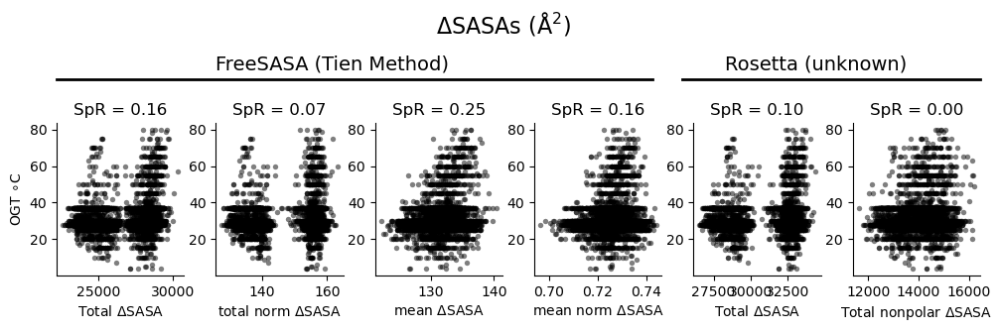

In [153]:
# buried SASAs, rosetta and freesasa
# first, plotting after filtering
fig = plt.figure(figsize=(12, 2))


dsasa_metrics = ['total_delta_sasa', 
              'total_norm_delta_sasa',
             'mean_delta_sasa', 
              'mean_norm_delta_sasa',
             'calc_bsa_total',
             'calc_bsa_apolar']

unit = r'($\mathrm{\AA}^{2}$)'
delta = r'$\Delta$'
labels = [f'Total {delta}SASA',
          f'total norm {delta}SASA',
          f'mean {delta}SASA',
          f'mean norm {delta}SASA',
         f'Total {delta}SASA',
         f'Total nonpolar {delta}SASA']


for i, (metric, label) in enumerate(zip(dsasa_metrics, labels)):
    ax = fig.add_subplot(1,6,i+1)
    # if i < 4:
    #     _x = metrics_df[metric]
    # else:
    #     _x = metrics_df[metric] / metrics_df['length']
    _x = metrics_df[metric]
    sns.scatterplot(data=metrics_df[metrics_df['aligned_structure_len'] / metrics_df['length'] > 0.95], 
                    x=_x, 
                    y='temp', edgecolor=None, color='black', s=15,
                    # hue=,
                    linewidth=0, alpha=0.5, 
                    # hue=metrics_df.uid.isin(filtered.uid), 
                    # palette=['red', 'k']
                   )
    # ax.get_legend().remove()
    # lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), title='filtered')
    if i == 0:
        ax.set_ylabel('OGT $\circ$C')
    else:
        ax.set_ylabel('')
    spr= spearmanr(_x, metrics_df['temp'])[0]
    ax.set_title(f'SpR = {spr:.2f}')
    ax.set_xlabel(label)
    sns.despine()
    # plt.tight_layout()
fig.subplots_adjust(wspace=0.25)
ax.annotate('FreeSASA (Tien Method)', (-5, 1.35), xycoords='axes fraction', annotation_clip=False, fontsize=14)
line1 = mpl.lines.Line2D([0.125, 0.625], [1.1, 1.1], color='k', linewidth=2)
fig.add_artist(line1)
ax.annotate('Rosetta (unknown)', (-1, 1.35), xycoords='axes fraction', annotation_clip=False, fontsize=14)
line2 = mpl.lines.Line2D([0.65, 0.9], [1.1, 1.1], color='k', linewidth=2)
fig.add_artist(line2)
title1 = fig.suptitle(f'{delta}SASAs {unit}', y=1.45, fontsize=16)
# title2 = fig.suptitle(f'Rosetta SASAs {unit} (unclear)', x=1, y=1.25, fontsize=14)
plt.savefig('./../data/figures/delta_sasas.svg', bbox_inches='tight')


In [154]:
metrics_df.columns

Index(['mean_total_sasa_fs', 'mean_polar_sasa_fs', 'mean_apolar_sasa_fs',
       'mean_delta_sasa', 'mean_norm_delta_sasa', 'mean_contacts_at_4.5',
       'total_total_sasa_fs', 'total_polar_sasa_fs', 'total_apolar_sasa_fs',
       'total_delta_sasa', 'total_norm_delta_sasa', 'total_contacts_at_4.5',
       'MM', 'MS', 'SM', 'SS', 'total', 'bb-sc', 'lidded', 'zinc', 'hbond',
       'total_score', 'avg_deg_4_5', 'avg_deg_8', 'avg_sc_nbrs_res_summary',
       'bb_internal_hbonds', 'bbsc_internal_hbonds', 'calc_bsa_apolar',
       'calc_bsa_total', 'cav_vol', 'internal_hbonds', 'nonpolar_sasa',
       'packstat', 'polar_sasa', 'sasa', 'sc_internal_hbonds',
       'total_cc_contacts', 'length', 'avg_cc_contacts_per_res', 'temp',
       'aligned_structure_len'],
      dtype='object')

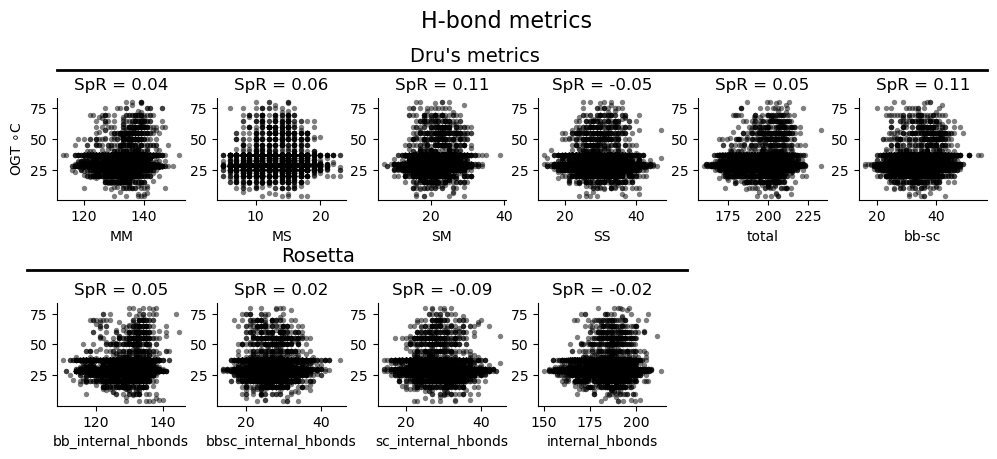

In [157]:
# h bond metrics
# first, plotting after filtering
fig = plt.figure(figsize=(12, 4))


hbond_metrics = ['MM', 'MS', 'SM', 'SS', 'total', 'bb-sc',
             'bb_internal_hbonds', 'bbsc_internal_hbonds', 'sc_internal_hbonds', 'internal_hbonds']

unit = r'($\mathrm{\AA}^{2}$)'
delta = r'$\Delta$'
labels = hbond_metrics.copy()

for i, (metric, label) in enumerate(zip(hbond_metrics, labels)):
    ax = fig.add_subplot(2,6,i+1)
    # if i < 4:
    _x = metrics_df[metric]
    # else:
    #     _x = metrics_df[metric] / metrics_df['length']
    sns.scatterplot(data=metrics_df[metrics_df['aligned_structure_len'] / metrics_df['length'] > 0.95], 
                    x=_x, 
                    y='temp', edgecolor=None, color='black', s=15,
                    # hue=,
                    linewidth=0, alpha=0.5, 
                    # hue=metrics_df.uid.isin(filtered.uid), 
                    # palette=['red', 'k']
                   )
    # ax.get_legend().remove()
    # lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), title='filtered')
    if i == 0:
        ax.set_ylabel('OGT $\circ$C')
    else:
        ax.set_ylabel('')
    spr= spearmanr(_x, metrics_df['temp'])[0]
    ax.set_title(f'SpR = {spr:.2f}')
    ax.set_xlabel(label)
    sns.despine()
    # plt.tight_layout()
    if i == 3:
        ax.annotate("Dru's metrics", (-1, 1.35), xycoords='axes fraction', annotation_clip=False, fontsize=14)
    
fig.subplots_adjust(wspace=0.25, hspace=1)

line1 = mpl.lines.Line2D([0.125, 0.9], [0.95, 0.95], color='k', linewidth=2)
fig.add_artist(line1)
ax.annotate('Rosetta', (-2, 1.4), xycoords='axes fraction', annotation_clip=False, fontsize=14)
line2 = mpl.lines.Line2D([0.1, 0.65], [0.45, 0.45], color='k', linewidth=2)
fig.add_artist(line2)
title1 = fig.suptitle(f'H-bond metrics', y=1.1, fontsize=16)
# title2 = fig.suptitle(f'Rosetta SASAs {unit} (unclear)', x=1, y=1.25, fontsize=14)
plt.savefig('./../data/figures/hbond_metrics.svg', bbox_inches='tight')


In [151]:
metrics_df.columns

Index(['mean_total_sasa_fs', 'mean_polar_sasa_fs', 'mean_apolar_sasa_fs',
       'mean_delta_sasa', 'mean_norm_delta_sasa', 'mean_contacts_at_4.5',
       'total_total_sasa_fs', 'total_polar_sasa_fs', 'total_apolar_sasa_fs',
       'total_delta_sasa', 'total_norm_delta_sasa', 'total_contacts_at_4.5',
       'MM', 'MS', 'SM', 'SS', 'total', 'bb-sc', 'lidded', 'zinc', 'hbond',
       'total_score', 'avg_deg_4_5', 'avg_deg_8', 'avg_sc_nbrs_res_summary',
       'bb_internal_hbonds', 'bbsc_internal_hbonds', 'calc_bsa_apolar',
       'calc_bsa_total', 'cav_vol', 'internal_hbonds', 'nonpolar_sasa',
       'packstat', 'polar_sasa', 'sasa', 'sc_internal_hbonds',
       'total_cc_contacts', 'length', 'avg_cc_contacts_per_res', 'temp',
       'aligned_structure_len'],
      dtype='object')

<Axes: xlabel='mean_total_sasa_fs', ylabel='mean_delta_sasa'>

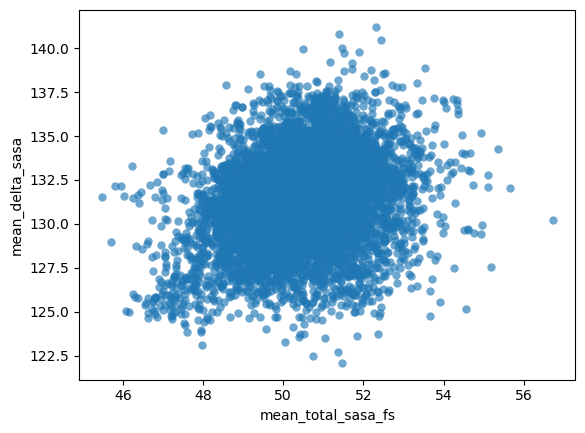

In [775]:
sns.scatterplot(x=metrics_df['mean_total_sasa_fs'],
               y=metrics_df['mean_delta_sasa'],
               linewidth=0, alpha=0.65)

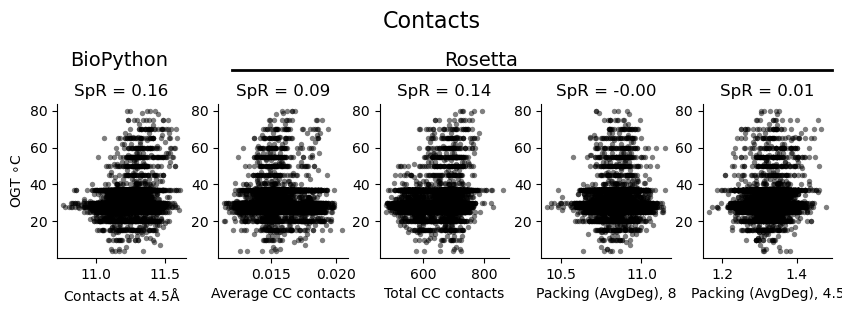

In [170]:
# contacts

# first, plotting after filtering
fig = plt.figure(figsize=(10, 2))


hbond_metrics = ['total_contacts_at_4.5',
    'avg_cc_contacts_per_res',
                'total_cc_contacts',
                 'avg_deg_8',
                 'avg_deg_4_5',
                ]

unit = r'($\mathrm{\AA}^{2}$)'
delta = r'$\Delta$'
labels = ['Contacts at 4.5$\mathrm{\AA}$',
          'Average CC contacts',
          'Total CC contacts',
          'Packing (AvgDeg), 8',
          'Packing (AvgDeg), 4.5']

for i, (metric, label) in enumerate(zip(hbond_metrics, labels)):
    ax = fig.add_subplot(1,5,i+1)
    if i > 1:
        _x = metrics_df[metric]
    else:
        _x = metrics_df[metric] / metrics_df['length']
    # _x = metrics_df[metric]
    sns.scatterplot(data=metrics_df[metrics_df['aligned_structure_len'] / metrics_df['length'] > 0.95], 
                    x=_x, 
                    y='temp', edgecolor=None, color='black', s=15,
                    # hue=,
                    linewidth=0, alpha=0.5, 
                    # hue=metrics_df.uid.isin(filtered.uid), 
                    # palette=['red', 'k']
                   )
    # ax.get_legend().remove()
    # lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), title='filtered')
    if i == 0:
        ax.set_ylabel('OGT $\circ$C')
    else:
        ax.set_ylabel('')
    spr= spearmanr(_x, metrics_df['temp'])[0]
    ax.set_title(f'SpR = {spr:.2f}')
    ax.set_xlabel(label)
    sns.despine()
    # plt.tight_layout()
    if i == 0:
        ax.annotate("BioPython", (0.1, 1.25), xycoords='axes fraction', annotation_clip=False, fontsize=14)
    
fig.subplots_adjust(wspace=0.25, hspace=1)

# line1 = mpl.lines.Line2D([0.125, 0.9], [0.95, 0.95], color='k', linewidth=2)
# fig.add_artist(line1)
ax.annotate('Rosetta', (-2, 1.25), xycoords='axes fraction', annotation_clip=False, fontsize=14)
line2 = mpl.lines.Line2D([0.3, 0.9], [1.05, 1.05], color='k', linewidth=2)
fig.add_artist(line2)
title1 = fig.suptitle(f'Contacts', y=1.35, fontsize=16)
# title2 = fig.suptitle(f'Rosetta SASAs {unit} (unclear)', x=1, y=1.25, fontsize=14)
plt.savefig('./../data/figures/contact_metrics.svg', bbox_inches='tight')


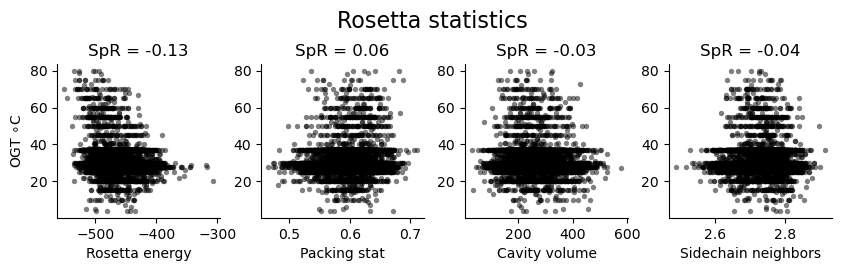

In [186]:
# Finally, extra metrics
fig = plt.figure(figsize=(10, 2))

other_stats = ['total_score', 'packstat', 'cav_vol', 'avg_sc_nbrs_res_summary']

labels = ['Rosetta energy',
           'Packing stat',
          'Cavity volume',
          'Sidechain neighbors']

for i, (metric, label) in enumerate(zip(other_stats, labels)):
    ax = fig.add_subplot(1,4,i+1)
    # if i > 1:
    #     _x = metrics_df[metric]
    # else:
    #     _x = metrics_df[metric] / metrics_df['length']
        
    _x = metrics_df[metric]
    
    sns.scatterplot(data=metrics_df[metrics_df['aligned_structure_len'] / metrics_df['length'] > 0.95], 
                    x=_x, 
                    y='temp', edgecolor=None, color='black', s=15,
                    linewidth=0, alpha=0.5, 
                   )

    if i == 0:
        ax.set_ylabel('OGT $\circ$C')
    else:
        ax.set_ylabel('')
    spr= spearmanr(_x, metrics_df['temp'])[0]
    ax.set_title(f'SpR = {spr:.2f}')
    ax.set_xlabel(label)
    sns.despine()

    
fig.subplots_adjust(wspace=0.25)

# line1 = mpl.lines.Line2D([0.125, 0.9], [0.95, 0.95], color='k', linewidth=2)
# fig.add_artist(line1)
title1 = fig.suptitle(f'Rosetta statistics', y=1.15, fontsize=16, ha='center')
# title2 = fig.suptitle(f'Rosetta SASAs {unit} (unclear)', x=1, y=1.25, fontsize=14)
plt.savefig('./../data/figures/other_stats.svg', bbox_inches='tight')


<Axes: xlabel='total_score', ylabel='Count'>

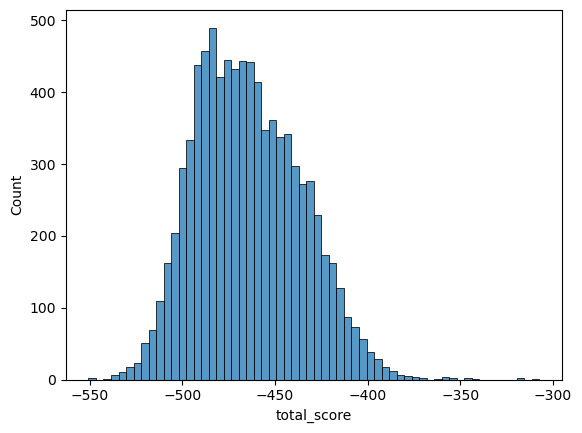

In [172]:
sns.histplot(metrics_df['total_score'])

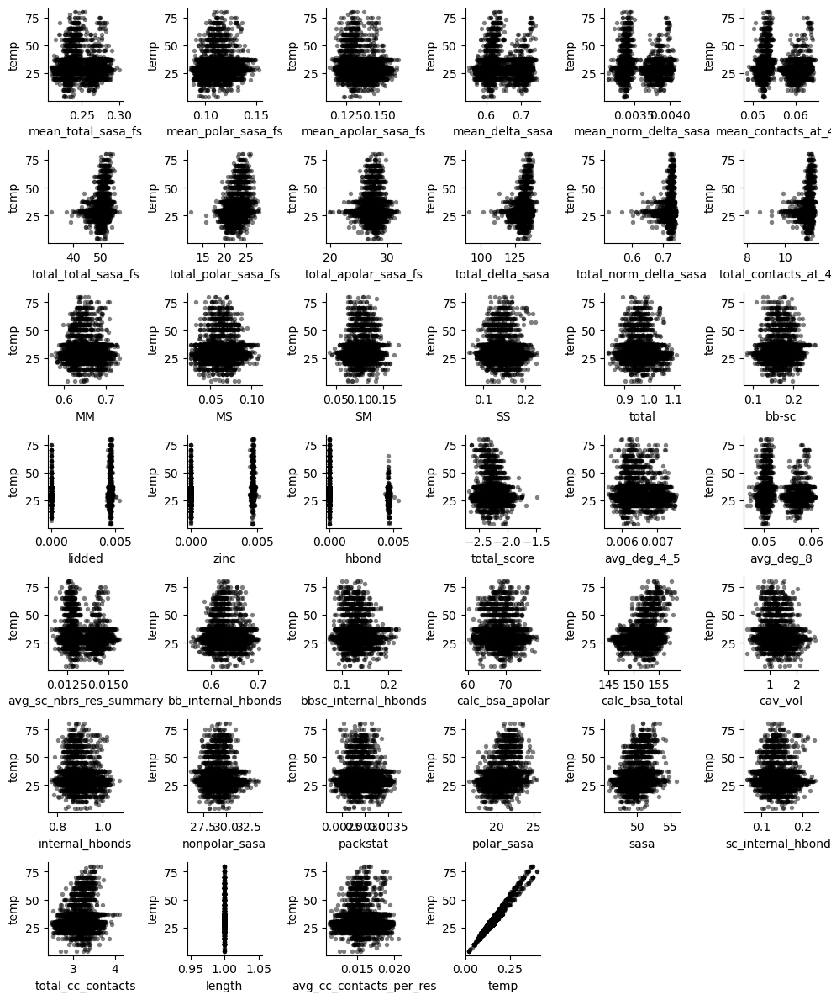

In [190]:
# first, plotting after filtering
fig = plt.figure(figsize=(10, 12))
for i, metric in enumerate(metrics_to_plot):
    ax = fig.add_subplot(7,6,i+1)
    sns.scatterplot(data=metrics_df, 
                    x=(metrics_df[metric] / metrics_df['length']).rename(metric), 
                    y='temp', edgecolor=None, color='black', s=15,
                    linewidth=0, alpha=0.5, 
                    # hue=metrics_df.uid.isin(filtered.uid), 
                    # palette=['red', 'k']
                   )
    # ax.get_legend().remove()
    # lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), title='filtered')

    sns.despine(fig)
    plt.tight_layout()


# plt.savefig('./../data/figures/correlations_filtering.png', dpi=400, bbox_inches='tight')

In [112]:
metrics_df['lid_type'] = metrics_df.apply(lambda row: classify_lid_type(row), axis=1)

<Axes: xlabel='mean_delta_sasa', ylabel='temp'>

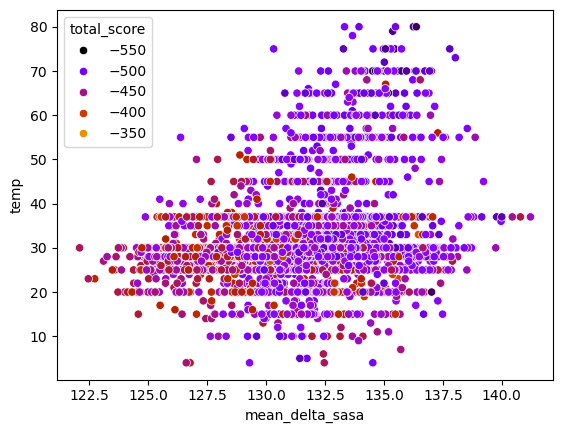

In [204]:
sns.scatterplot(y=metrics_df['temp'],
                x=metrics_df['mean_delta_sasa'],
               hue=metrics_df['total_score'], palette='gnuplot')

In [113]:
metrics_df['lid_type'].value_counts()

lid_type
lidless    3188
zinc       2575
hbond      1757
other      1012
Name: count, dtype: int64

In [321]:
from sklearn.preprocessing import StandardScaler, FunctionTransformer

In [404]:
metric = 'polar_sasa'

In [410]:
model_data = metrics_df.copy(deep=True)
model_data['length_power'] = model_data['length'] #  ** 2/3

In [411]:
scaler = StandardScaler()
scaled = scaler.fit_transform(model_data[['temp', metric, 'length_power']])
model_data = pd.concat([pd.DataFrame(scaled, 
                                     index=metrics_df.index, 
                                     columns=['temp', metric,'length_power']), 
                        metrics_df[['lid_type']]], axis=1)
# model_

In [412]:
model_data.head()

,temp,polar_sasa,length_power,lid_type
GB_GCA_000016765.1,-0.115955,-0.256884,0.716442,zinc
GB_GCA_000242235.1,0.820784,-0.195499,0.640617,zinc
GB_GCA_000283575.1,-0.115955,0.107598,0.337319,zinc
GB_GCA_000376885.1,0.820784,-0.358255,-1.406650,lidless
GB_GCA_000411155.1,0.820784,-0.133095,-0.875877,lidless


In [417]:
# Setting 'Lidless' as the reference baseline category
formula1 = f"temp ~ length_power * {metric} * C(lid_type, Treatment('lidless'))"
# formula2 = f"temp ~ length * C(lid_type, Treatment('lidless')) + {metric} * C(lid_type, Treatment('lidless')) + I(length2)"
# polynomial 
formula2 = f"""
temp ~ length_power + I(length_power**2) + {metric} + 
       length_power:C(lid_type, Treatment('lidless')) + 
       I(length_power**2):C(lid_type, Treatment('lidless')) +
       {metric}:C(lid_type, Treatment('lidless'))
"""

formula3 = """
temp ~ np.power(length, 0.67) + calc_bsa_total + 
       np.power(length, 0.67):C(lid_type, Treatment('lidless')) + 
       calc_bsa_total:C(lid_type, Treatment('lidless'))
"""
clean_formula3 = f"""temp ~ length_power:C(lid_type, Treatment('lidless')) + 
       {metric}:C(lid_type, Treatment('lidless'))
       + {metric}:length_power
"""
formula4 = """
               np.log(temp) ~ np.log(length) + np.log(calc_bsa_total) + 
               np.log(length):C(lid_type, Treatment('lidless')) + 
               np.log(calc_bsa_total):C(lid_type, Treatment('lidless'))
"""

model = smf.ols(clean_formula3, data=model_data).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   temp   R-squared:                       0.116
Model:                            OLS   Adj. R-squared:                  0.115
Method:                 Least Squares   F-statistic:                     123.9
Date:                Fri, 15 May 2026   Prob (F-statistic):          6.08e-220
Time:                        23:54:06   Log-Likelihood:                -11582.
No. Observations:                8532   AIC:                         2.318e+04
Df Residuals:                    8522   BIC:                         2.325e+04
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                                                              coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------

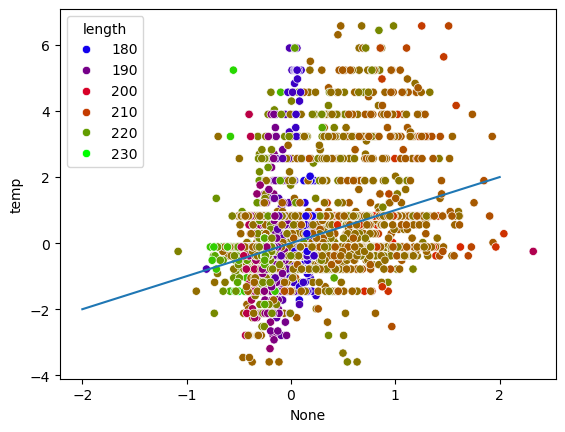

In [414]:
sns.scatterplot(x=model.predict(model_data),
                y=model_data.iloc[:, 0],
               hue=metrics_df['length'], palette='brg')
plt.plot((-2,2), (-2,2))

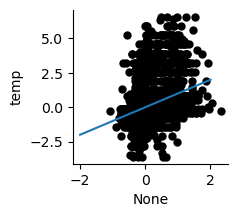

In [415]:
fig, ax = plt.subplots(figsize=(2,2))
sns.scatterplot(x=model.predict(model_data),
                y=model_data.iloc[:, 0],
               # hue=metrics_df['length'], 
                color='k',
               linewidth=0)
plt.plot((-2,2), (-2,2))
sns.despine()

<Axes: xlabel='length', ylabel='sasa'>

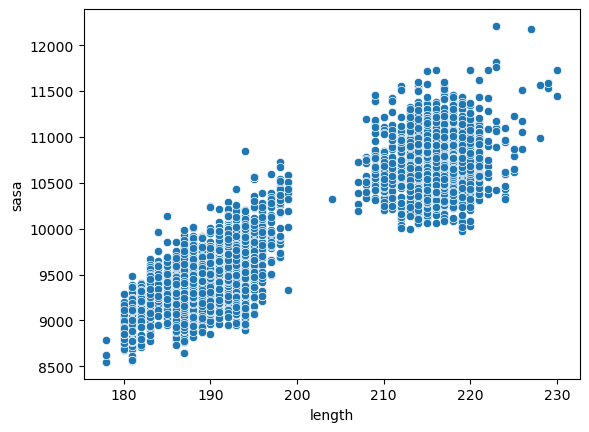

In [303]:
sns.scatterplot(x=metrics_df['length'],
                y=metrics_df['sasa'])

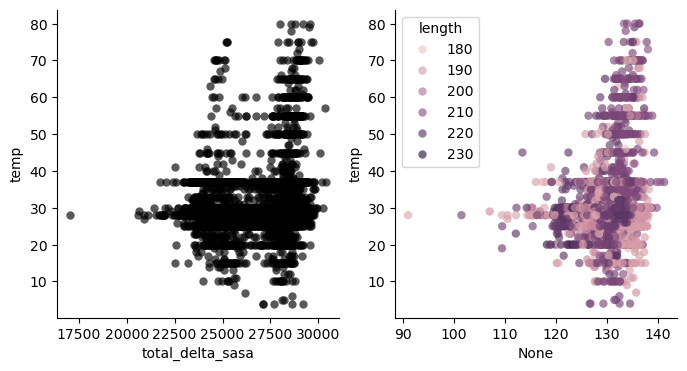

In [187]:
fig = plt.figure(figsize=(8, 4))
metric = 'total_delta_sasa'
ax = fig.add_subplot(1,2,1)
# Plotting SASA vs OGT
sns.scatterplot(
    data=metrics_df,
    x=metrics_df[metric] ,
    y='temp', color='k', 
    linewidth=0, alpha=0.65

)
sns.despine()

# regression
formula = f"temp ~ length"

model = smf.ols(formula, data=metrics_df).fit()


ax = fig.add_subplot(1,2,2)
# Plotting SASA vs OGT
sns.scatterplot(
    data=metrics_df,
    x=metrics_df[metric] / metrics_df['length'],
    y='temp', color='k', 
    hue='length', 
    linewidth=0, alpha=0.65

)
# ax.set_xlim(2000, 7500)
sns.despine()



In [183]:
(model.params.loc['length'] * metrics_df['length'])

GB_GCA_000016765.1   -71.284365
GB_GCA_000242235.1   -70.952810
GB_GCA_000283575.1   -69.626589
GB_GCA_000376885.1   -62.000820
GB_GCA_000411155.1   -64.321706
                        ...    
RS_GCF_905397275.1   -73.273696
RS_GCF_905397435.1   -73.273696
RS_GCF_907163105.1   -63.990151
RS_GCF_907163265.1   -71.947475
RS_GCF_910593845.1   -71.284365
Name: length, Length: 8532, dtype: float64

In [185]:
model.params

Intercept                  253.717204
total_delta_sasa            -0.006073
length                      -1.455839
total_delta_sasa:length      0.000043
dtype: float64

<Figure size 1000x600 with 0 Axes>

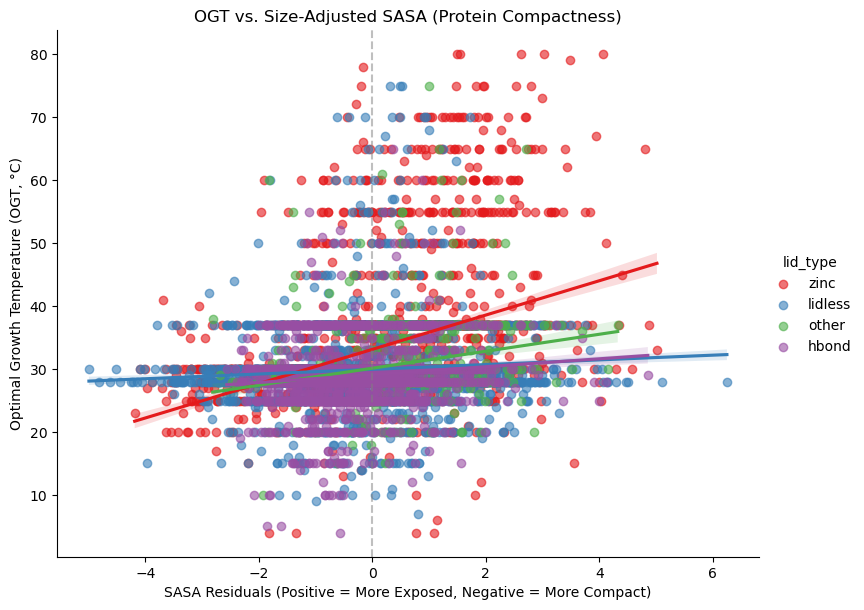

In [127]:
plotdf = metrics_df.copy(deep=True)
# 1. Predict SASA based strictly on Residue Count to get the "size-expected" SASA
size_model = smf.ols("mean_total_sasa_fs ~ length", data=plotdf).fit()

# 2. Extract the residuals (Actual SASA minus Expected SASA)
plotdf['SASA_Adjusted_for_Size'] = size_model.resid

# 3. Plot Size-Adjusted SASA vs OGT, split by Lid Type
plt.figure(figsize=(10, 6))
sns.lmplot(
    data=plotdf,
    x='SASA_Adjusted_for_Size',
    y='temp',
    hue='lid_type',
    palette='Set1',
    height=6,
    aspect=1.3,
    scatter_kws={'alpha': 0.6}
)

plt.title('OGT vs. Size-Adjusted SASA (Protein Compactness)')
plt.xlabel('SASA Residuals (Positive = More Exposed, Negative = More Compact)')
plt.ylabel('Optimal Growth Temperature (OGT, °C)')
plt.axvline(0, color='gray', linestyle='--', alpha=0.5) # The "average compactness" line
plt.show()

In [70]:
metrics_df.shape

(8532, 40)

<Axes: xlabel='mean_temp', ylabel='SASA'>

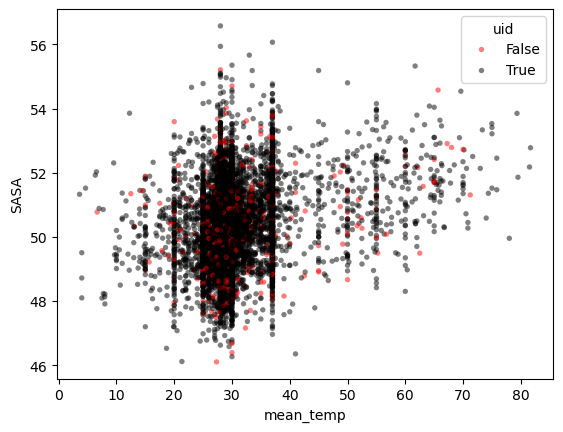

In [13]:
sns.scatterplot(data=filtered, y=filtered['SASA'], x= filtered['mean_temp'], edgecolor=None, color='black', s=15,
                    linewidth=0, alpha=0.5, hue=metrics_df.uid.isin(filtered.uid), palette=['red', 'k']
                   )

<Axes: xlabel='SASA', ylabel='Count'>

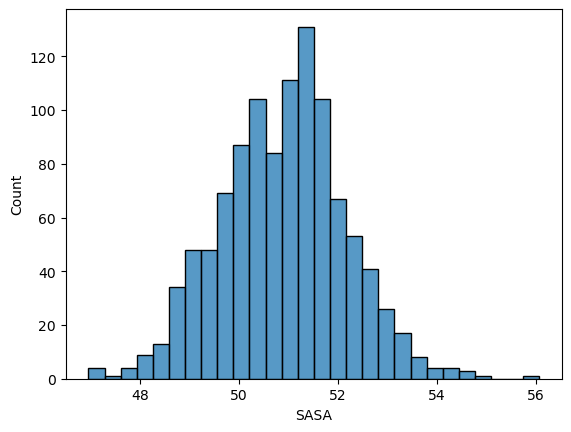

In [14]:
sns.histplot(filtered[filtered['mean_temp'].eq(37)]['SASA'])

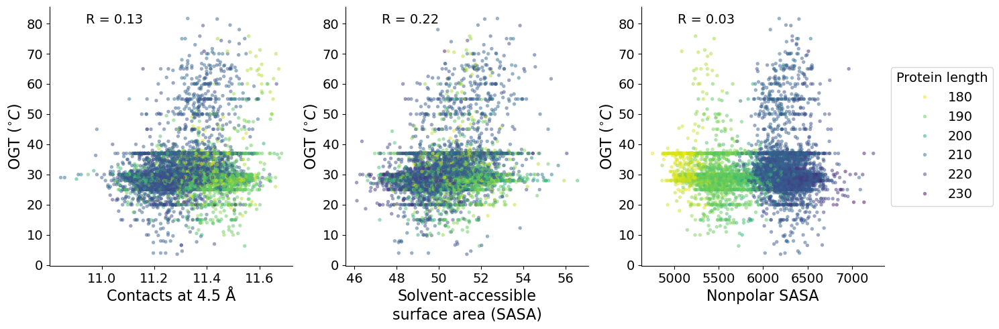

In [15]:
# poster-friendly version
fig = plt.figure(figsize=(15, 5))
labels = ['Contacts at 4.5 Å', 'Solvent-accessible\nsurface area (SASA)', 'Nonpolar SASA'] #, 'Packing statistic']
for i, (label, metric) in enumerate(zip(labels, ['Contacts at 4.5 Å', 'SASA', 'nonpolar_sasa'])):
    ax = fig.add_subplot(1, 3,i+1)
    # ax.set_aspect('equal')
    sns.scatterplot(data=filtered, 
                    x=metric, y='mean_temp', edgecolor=None, color='gray', s=15,
                    linewidth=0, alpha=0.5,
                    hue='seq_length', palette='viridis_r'
                   )
    
    spr = spearmanr(filtered['mean_temp'], filtered[metric])[0]
    ax.annotate(f'R = {spr:.2f}', 
                (ax.get_xlim()[0] + (ax.get_xlim()[1] - ax.get_xlim()[0]) * .15, 80), 
                fontsize=14)
    
    if i < 2:
        ax.get_legend().remove()
    else:
        lgd = ax.legend(loc='center left', 
                        bbox_to_anchor=(1, 0.5), 
                        title='Protein length',
                        fontsize=14, title_fontsize=14)
        
    plt.tick_params(labelsize=14)
    ax.set_xlabel(label, fontsize=16)
    ax.set_ylabel("OGT ($^{\circ}C$)", fontsize=16)
    sns.despine(fig)
    plt.tight_layout()
    
plt.savefig('./../data/figures/structural_features.png', dpi=400, bbox_inches='tight', bbox_extra_artists=(lgd,))

In [16]:
filtered

,Unnamed: 0,Position,Contacts at 4.5 Å,SASA,uid,total_score,avg_deg_4_5,avg_deg_8,avg_sc_nbrs_res_summary,bb_internal_hbonds,...,temp,mean_temp,seq_length,bitscore,C,L,N,P,max_structure_length,lid_bitscore
0,0,94.0,11.358289,52.616491,GB_GCA_000376885.1,-454.076,1.278,10.765,2.648,124.0,...,37.0,37.00,187,178.2,90.0,48.0,42.0,6.0,24,0.0
1,1,108.0,11.125581,49.464040,GB_GCA_000016765.1,-450.126,1.316,10.730,2.697,132.0,...,30.0,30.00,215,175.3,116.0,49.0,43.0,6.0,23,52.3
2,2,119.5,11.289720,49.538232,GB_GCA_000242235.1,-419.604,1.327,10.981,2.842,128.0,...,37.0,37.00,214,192.2,117.0,48.0,42.0,6.0,24,59.2
3,3,105.5,11.276190,50.018080,GB_GCA_000283575.1,-452.738,1.390,10.905,2.771,129.0,...,30.0,30.00,210,168.7,112.0,48.0,43.0,6.0,24,58.3
4,4,91.0,11.359116,51.483049,GB_GCA_001054945.1,-431.800,1.243,10.768,2.669,117.0,...,37.0,37.00,181,192.9,88.0,44.0,42.0,6.0,21,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8527,9336,111.0,11.257919,49.134618,RS_GCF_905397275.1,-492.694,1.353,10.846,2.780,130.0,...,30.0,28.75,221,195.8,123.0,48.0,43.0,6.0,28,61.7
8528,9337,99.0,11.502591,51.214600,RS_GCF_907163105.1,-494.248,1.290,11.031,2.738,128.0,...,30.0,33.50,193,165.6,122.0,22.0,42.0,6.0,24,0.0
8529,9338,111.0,11.366516,49.484025,RS_GCF_905397435.1,-469.955,1.362,10.810,2.811,133.0,...,27.0,26.40,221,194.9,123.0,48.0,43.0,6.0,28,61.6
8530,9339,108.0,11.479070,49.243296,RS_GCF_910593845.1,-487.960,1.288,10.833,2.731,133.0,...,30.0,29.50,215,190.8,118.0,48.0,42.0,6.0,24,66.3


## Additional plots using OGT Finder data

In [17]:
comparison_data = pd.read_csv('./../data/metric_tables/20250327_ogtfinder_merged_data.tsv', sep='\t', index_col=0)

In [18]:
ogtfinder_temps = comparison_data.set_index('accession')['Temp_optimum'].dropna()

In [19]:
metrics_df

,Unnamed: 0,Position,Contacts at 4.5 Å,SASA,uid,total_score,avg_deg_4_5,avg_deg_8,avg_sc_nbrs_res_summary,bb_internal_hbonds,...,temp,mean_temp,seq_length,bitscore,C,L,N,P,max_structure_length,lid_bitscore
0,0,94.0,11.358289,52.616491,GB_GCA_000376885.1,-454.076,1.278,10.765,2.648,124.0,...,37.0,37.00,187,178.2,90.0,48.0,42.0,6.0,24,0.0
1,1,108.0,11.125581,49.464040,GB_GCA_000016765.1,-450.126,1.316,10.730,2.697,132.0,...,30.0,30.00,215,175.3,116.0,49.0,43.0,6.0,23,52.3
2,2,119.5,11.289720,49.538232,GB_GCA_000242235.1,-419.604,1.327,10.981,2.842,128.0,...,37.0,37.00,214,192.2,117.0,48.0,42.0,6.0,24,59.2
3,3,105.5,11.276190,50.018080,GB_GCA_000283575.1,-452.738,1.390,10.905,2.771,129.0,...,30.0,30.00,210,168.7,112.0,48.0,43.0,6.0,24,58.3
4,4,91.0,11.359116,51.483049,GB_GCA_001054945.1,-431.800,1.243,10.768,2.669,117.0,...,37.0,37.00,181,192.9,88.0,44.0,42.0,6.0,21,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9336,9336,111.0,11.257919,49.134618,RS_GCF_905397275.1,-492.694,1.353,10.846,2.780,130.0,...,30.0,28.75,221,195.8,123.0,48.0,43.0,6.0,28,61.7
9337,9337,99.0,11.502591,51.214600,RS_GCF_907163105.1,-494.248,1.290,11.031,2.738,128.0,...,30.0,33.50,193,165.6,122.0,22.0,42.0,6.0,24,0.0
9338,9338,111.0,11.366516,49.484025,RS_GCF_905397435.1,-469.955,1.362,10.810,2.811,133.0,...,27.0,26.40,221,194.9,123.0,48.0,43.0,6.0,28,61.6
9339,9339,108.0,11.479070,49.243296,RS_GCF_910593845.1,-487.960,1.288,10.833,2.731,133.0,...,30.0,29.50,215,190.8,118.0,48.0,42.0,6.0,24,66.3


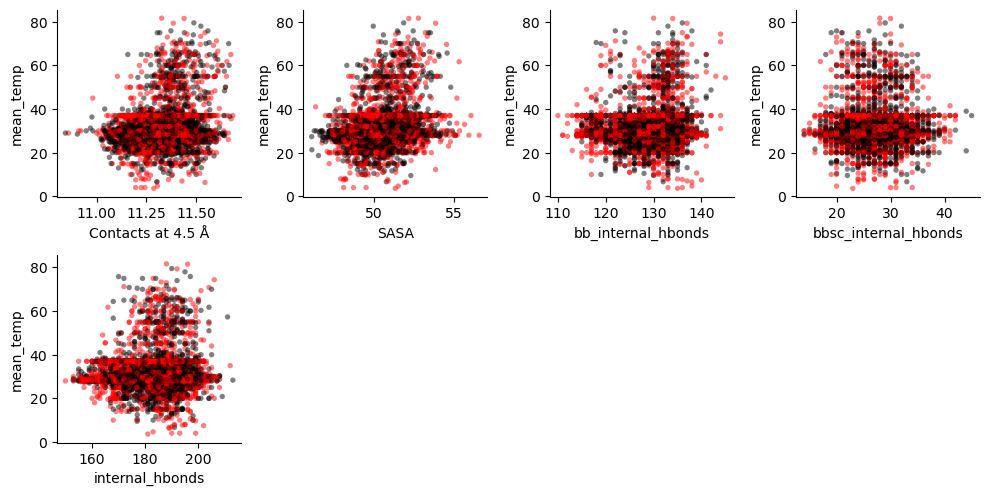

In [20]:
# first, plotting after filtering
fig = plt.figure(figsize=(10, 12))
for i, metric in enumerate(metrics_to_plot[:5]):
    ax = fig.add_subplot(5,4,i+1)
    sns.scatterplot(data=filtered, x=metric, y='mean_temp', edgecolor=None, color='black', s=15,
                    linewidth=0, alpha=0.5, hue=filtered.uid.isin(ogtfinder_temps.index), palette=['red', 'k']
                   )
    
    ax.get_legend().remove()
    # lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), title='filtered')

    sns.despine(fig)
    plt.tight_layout()


# plt.savefig('./../data/figures/correlations_filtering.png', dpi=400, bbox_inches='tight')

In [21]:
filtered['uid'].map(ogtfinder_temps).dropna()

4       37.0
6       37.5
8       30.0
9       30.0
15      25.0
        ... 
8527    27.5
8528    37.0
8529    30.0
8530    29.0
8531    27.5
Name: uid, Length: 3196, dtype: float64

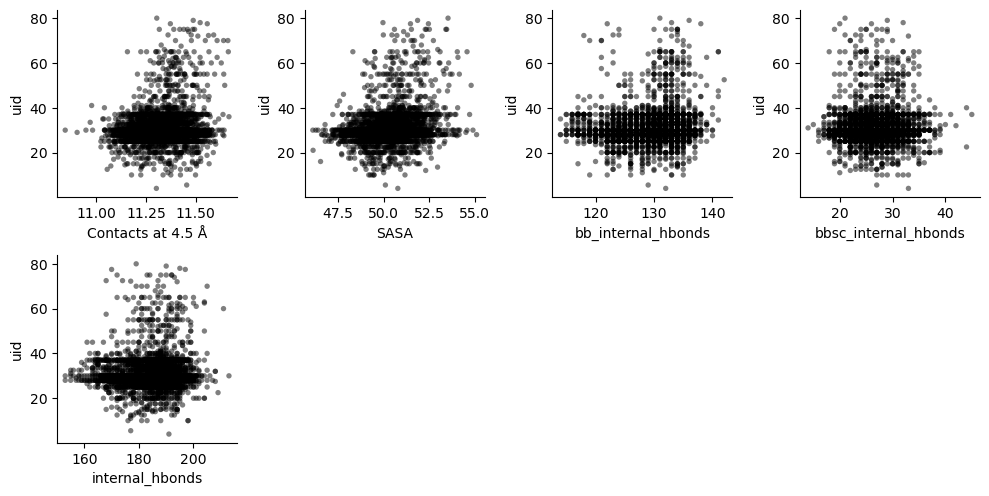

In [22]:
# first, plotting afogtfinder_tempsltering
fig = plt.figure(figsize=(10, 12))
for i, metric in enumerate(metrics_to_plot[:5]):
    ax = fig.add_subplot(5,4,i+1)
    sns.scatterplot(data=filtered, x=filtered[metric], y=filtered['uid'].map(ogtfinder_temps).dropna(), edgecolor=None, color='black', s=15,
                    linewidth=0, alpha=0.5, hue=filtered.uid.isin(ogtfinder_temps.index), palette=['red', 'k']
                   )
    
    ax.get_legend().remove()
    # lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), title='filtered')

    sns.despine(fig)
    plt.tight_layout()


# plt.savefig('./../data/figures/correlations_filtering.png', dpi=400, bbox_inches='tight')

## First plots

In [21]:
corkrey_matches = pd.read_csv('/data/mhoffert/fiererlab/ogt/results/db/corkey_gtdb_matching.tsv', sep='\t', index_col=0)
corkrey_data = pd.read_csv('/data/mhoffert/fiererlab/ogt/source_data/Corkey_temperatures.csv')
corkrey_full = pd.merge(corkrey_data.groupby('binomial.name').agg({'T.C':'mean'}), corkrey_matches, left_index=True, right_on='original_id')

corkrey_full = corkrey_full.groupby('match_accession').agg({'T.C':'mean'})

# corkey = pd.read_csv('/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/metric_tables/20240410_corkey_save.tsv', sep='\t')
# corkey

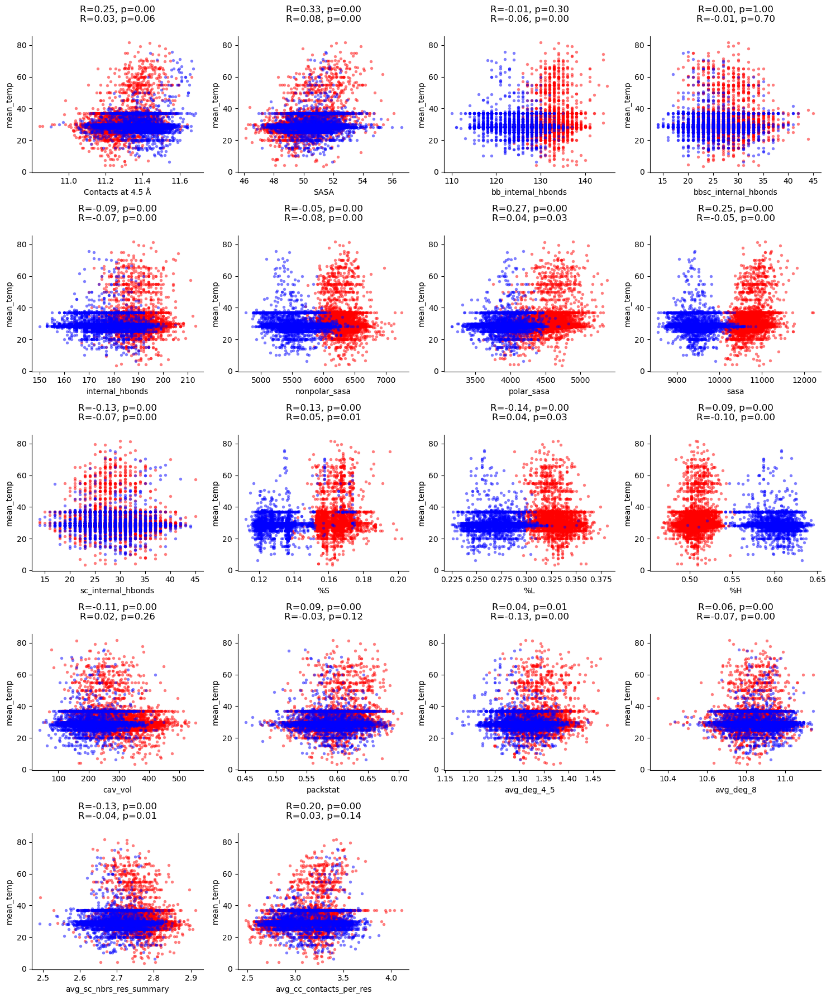

In [22]:
# first, plotting after filtering
spearman_results = pd.DataFrame(columns=['short_full', 'long_full'])
fig = plt.figure(figsize=(15, 18))
for i, metric in enumerate(metrics_to_plot):
    ax = fig.add_subplot(5,4,i+1)
    title = ''
    for qstr, color, iso in zip(['seq_length > 200', 'seq_length < 200'], ['r', 'b'], ['long', 'short']):
        sns.scatterplot(data=filtered.query(qstr), x=metric, y='mean_temp', edgecolor=None, color=color, s=15,
                        linewidth=0, alpha=0.5
                       )
        spR_result = spearmanr(filtered.query(qstr)[metric], filtered.query(qstr)['temp'])
        title += f'R={spR_result[0]:.02f}, p={spR_result[1]:.02f}\n'
        
        subset = filtered.query(qstr).set_index('uid').reindex(corkrey_full.index).dropna()
        spR_sub = spearmanr(subset[metric], corkrey_full.reindex(subset.index)['T.C'])
        spearman_results.loc[metric, f'{iso}_full'] = spR_result[0]
        # spearman_results.loc[metric, f'{iso}_sub'] = spR_sub[0]
    ax.set_title(title)
    # ax.get_legend().remove()
    # lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), title='filtered')

    
    

    # fileout = plot_filenames[metric] + '.svg'
    # plt.savefig(os.path.join(output_dir, figure_dir, fileout))

sns.despine(fig)
plt.tight_layout()
# plt.savefig('./../data/figures/correlations_post_filtering.png', dpi=400, bbox_inches='tight')

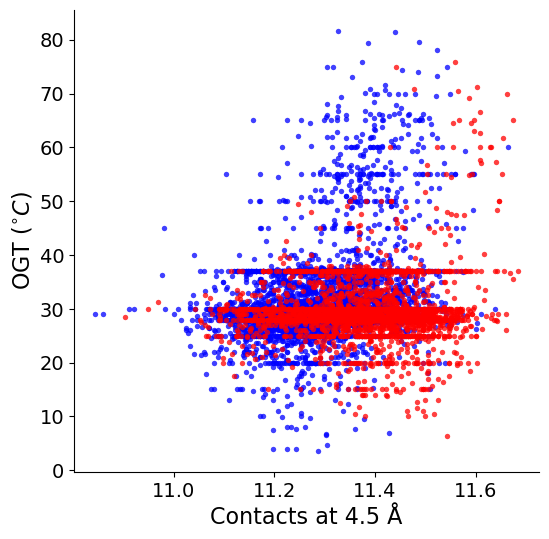

In [23]:
# individual plot
fig, ax = plt.subplots(figsize=(6,6))
metric = 'Contacts at 4.5 Å'
sns.scatterplot(data=filtered.query('seq_length > 200'), x=metric, y='mean_temp', 
                color='b', label='long',
                edgecolor=None, s=15, linewidth=0, alpha=0.75
               )
sns.scatterplot(data=filtered.query('seq_length <= 200'), x=metric, y='mean_temp', 
                color='r',  label='short',
                edgecolor=None, s=15, linewidth=0, alpha=0.75
               )
ax.get_legend().remove()
plt.tick_params(labelsize=14)
ax.set_xlabel(metric, fontsize=16)
ax.set_ylabel('OGT ($^{\circ}C$)', fontsize=16)
sns.despine()
# plt.savefig('/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/figures/long_vs_short_contacts.png',
#            dpi=400, bbox_inches='tight')

In [24]:
metric = '%H'

In [25]:
meantest = filtered.query('seq_length > 200').copy(deep=True)

meantest['group'] = pd.cut(meantest['temp'], np.linspace(meantest['mean_temp'].min(), meantest['mean_temp'].max(), 20))

mean_data = meantest.groupby('group')[metric].agg(mean=lambda x: x.mean(),
                                                  Q25=lambda x: x.quantile(0.25),
                                                  Q75=lambda x: x.quantile(0.75),
                                                  count=lambda x: len(x)
                                                 ).reset_index()
mean_data.head()

mean_data['mid_temp'] = mean_data['group'].apply(lambda x: x.mid)
mean_data['mid_temp'] = mean_data['mid_temp'].astype(float)
mean_data = mean_data.sort_values('mid_temp', ascending=False)

mean_data.head()



,group,mean,Q25,Q75,count,mid_temp
18,"(77.559, 81.667]",0.506362,0.502381,0.509346,7,79.6130
17,"(73.451, 77.559]",0.509584,0.504097,0.512956,8,75.5050
16,"(69.344, 73.451]",0.509936,0.502347,0.516432,25,71.3975
15,"(65.236, 69.344]",0.509908,0.497674,0.519048,5,67.2900
14,"(61.128, 65.236]",0.512058,0.504673,0.518519,39,63.1820


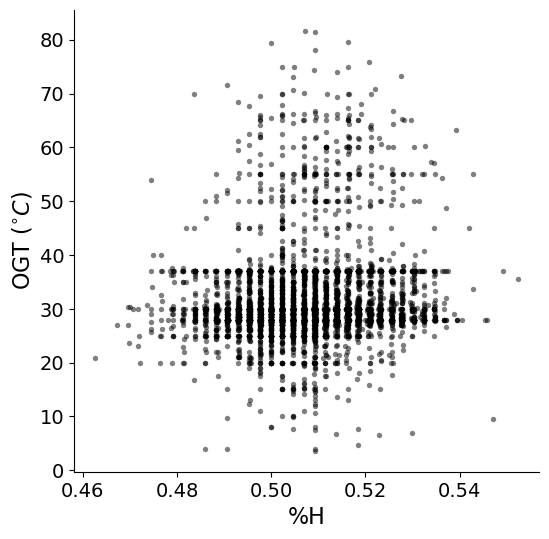

In [26]:
# individual plot
fig, ax = plt.subplots(figsize=(6,6))
sns.scatterplot(data=filtered.query('seq_length > 200'), x=metric, y='mean_temp', 
                color='k',
                edgecolor=None, s=15, linewidth=0, alpha=0.5
               )

# ax.get_legend().remove()
plt.tick_params(labelsize=14)
ax.set_xlabel(metric, fontsize=16)
ax.set_ylabel('OGT ($^{\circ}C$)', fontsize=16)
sns.despine()
# plt.savefig('/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/figures/long_SASA.png',
#            dpi=400, bbox_inches='tight')

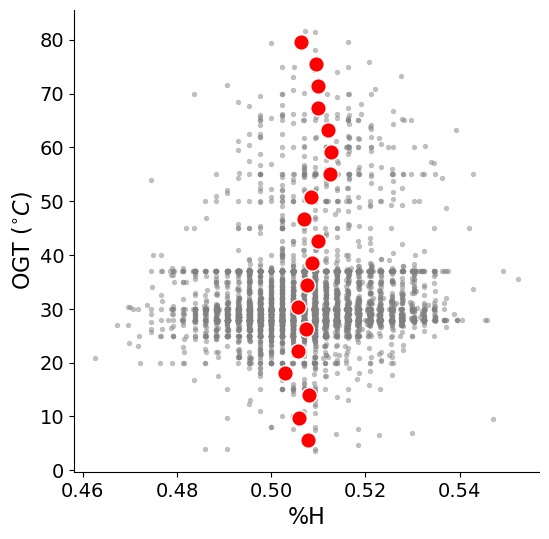

In [27]:
# individual plot
fig, ax = plt.subplots(figsize=(6,6))
sns.scatterplot(data=filtered.query('seq_length > 200'), x=metric, y='mean_temp', 
                color='gray',
                edgecolor=None, s=15, linewidth=0, alpha=0.5
               )

sns.scatterplot(data=mean_data, x='mean', y='mid_temp', 
                color='r', linewidth=1, s=125)

# ax.get_legend().remove()
plt.tick_params(labelsize=14)
ax.set_xlabel(metric, fontsize=16)
ax.set_ylabel('OGT ($^{\circ}C$)', fontsize=16)
sns.despine()
# plt.savefig('/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/figures/long_SASA_means.png',
#            dpi=400, bbox_inches='tight')

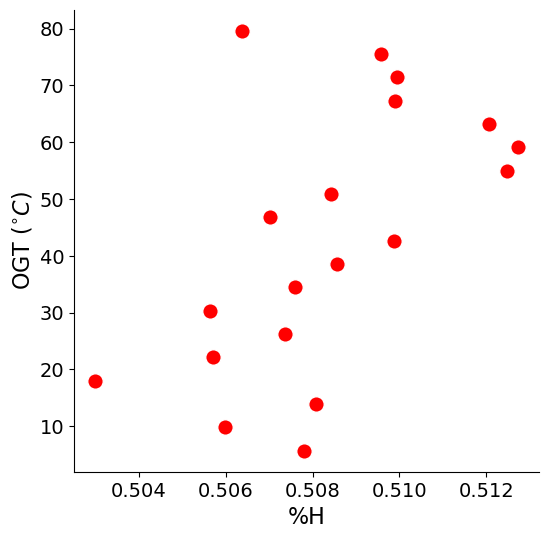

In [28]:
# individual plot
fig, ax = plt.subplots(figsize=(6,6))
# sns.scatterplot(data=filtered.query('seq_length > 200'), x=metric, y='mean_temp', 
#                 color='gray',
#                 edgecolor=None, s=15, linewidth=0, alpha=0.5
#                )

sns.scatterplot(data=mean_data, x='mean', y='mid_temp', 
                color='r', linewidth=1, s=125)

# ax.get_legend().remove()
plt.tick_params(labelsize=14)
ax.set_xlabel(metric, fontsize=16)
ax.set_ylabel('OGT ($^{\circ}C$)', fontsize=16)
sns.despine()
# plt.savefig('/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/figures/long_SASA_meansonly.png',
#            dpi=400, bbox_inches='tight')

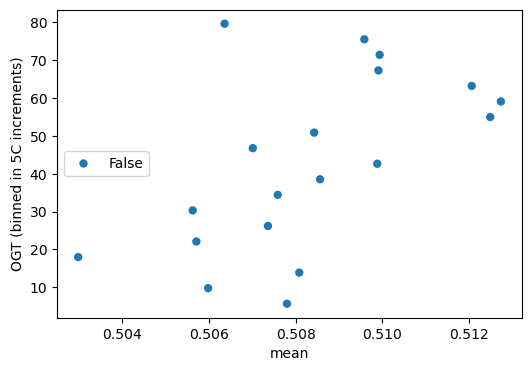

In [29]:
fig, ax = plt.subplots(figsize=(6,4))
sns.scatterplot(data=mean_data, y='mid_temp', x='mean', 
                linewidth=0, alpha=1, hue=mean_data['count'] < 5)

# for index, row in mean_data.iterrows():
    
#     plt.plot((row['Q25'], row['Q75']), 
#              (row['mid_temp'], row['mid_temp']),
#             zorder=0,
#             color='gray', alpha=0.65)
ax.set_ylabel('OGT (binned in 5C increments)')
ax.set_ylabel('OGT (binned in 5C increments)')
lgd = ax.legend(loc='center left')

<Axes: xlabel='SASA', ylabel='Count'>

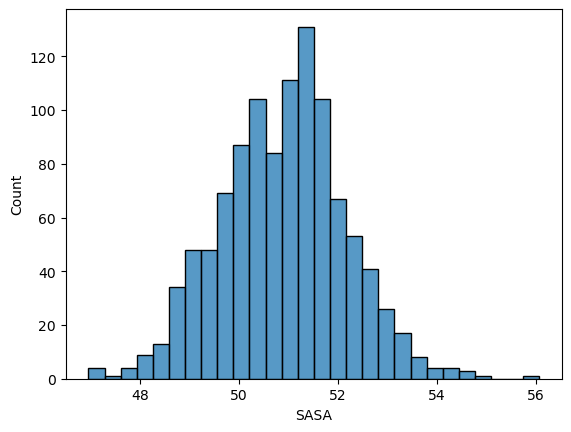

In [30]:
sns.histplot(filtered[filtered['mean_temp'].eq(37)]['SASA'])

## Additional plots

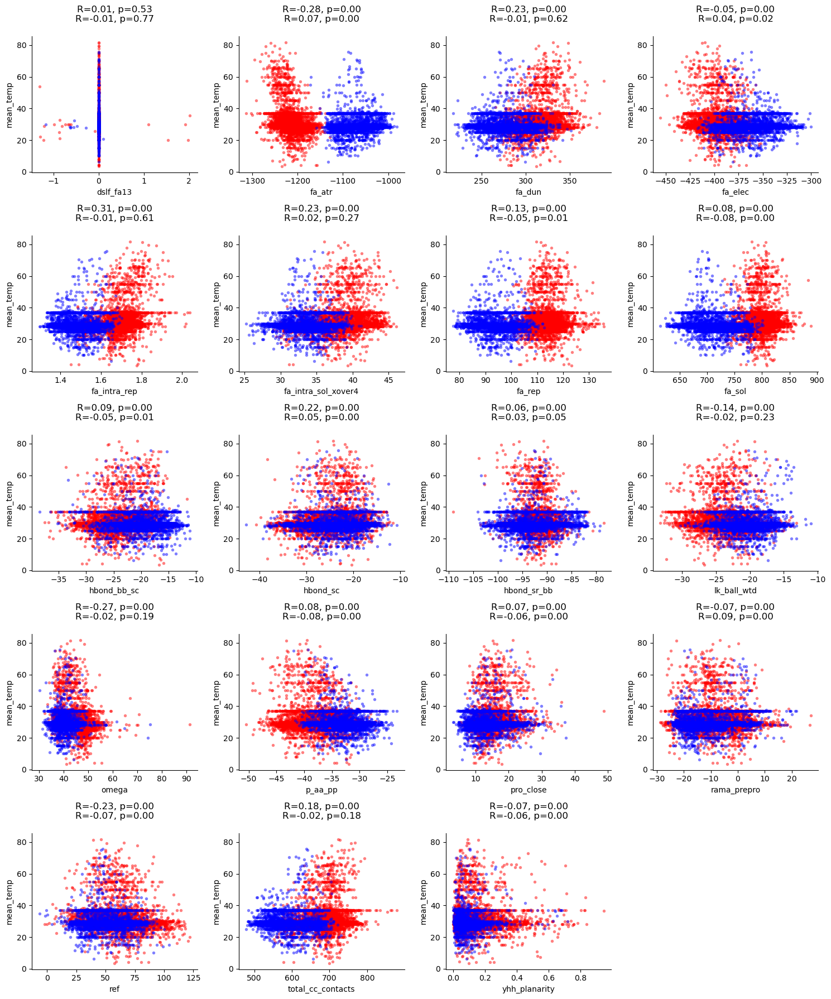

In [31]:
# first, plotting after filtering
# spearman_results = pd.DataFrame(columns=['short_R', 'long_R'])
fig = plt.figure(figsize=(15, 18))
for i, metric in enumerate(additional_metrics):
    ax = fig.add_subplot(5,4,i+1)
    title = ''
    for qstr, color, iso in zip(['seq_length > 200', 'seq_length < 200'], ['r', 'b'], ['long', 'short']):
        sns.scatterplot(data=filtered.query(qstr), x=metric, y='mean_temp', edgecolor=None, color=color, s=15,
                        linewidth=0, alpha=0.5
                       )
        spR_result = spearmanr(filtered.query(qstr)[metric], filtered.query(qstr)['temp'])
        title += f'R={spR_result[0]:.02f}, p={spR_result[1]:.02f}\n'

        subset = filtered.query(qstr).set_index('uid').reindex(corkrey_full.index).dropna()
        spR_sub = spearmanr(subset[metric], corkrey_full.reindex(subset.index)['T.C'])
        spearman_results.loc[metric, f'{iso}_full'] = spR_result[0]
        # spearman_results.loc[metric, f'{iso}_sub'] = spR_sub[0]
    ax.set_title(title)
    # ax.get_legend().remove()
    # lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), title='filtered')

    
    

    # fileout = plot_filenames[metric] + '.svg'
    # plt.savefig(os.path.join(output_dir, figure_dir, fileout))

sns.despine(fig)
plt.tight_layout()
# plt.savefig('./../data/figures/correlations_post_filtering.png', dpi=400, bbox_inches='tight')

In [32]:
spearman_results.head()

,short_full,long_full
Contacts at 4.5 Å,0.032793,0.248879
SASA,0.079872,0.331031
bb_internal_hbonds,-0.056406,-0.014309
bbsc_internal_hbonds,-0.006811,0.000026
internal_hbonds,-0.073086,-0.09341


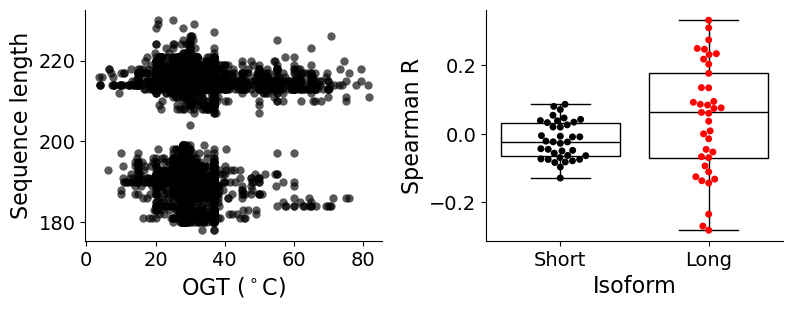

In [33]:
fig = plt.figure(figsize=(9,3))
ax = fig.add_subplot(1, 2, 1)
sns.scatterplot(data=filtered, x='mean_temp', y='seq_length',
               linewidth=0, alpha=0.65, color='k')

plt.tick_params(labelsize=14)
ax.set_xlabel('OGT ($^\circ$C)', fontsize=16)
ax.set_ylabel('Sequence length', fontsize=16)
sns.despine()

ax = fig.add_subplot(1, 2, 2)
sns.swarmplot(data=spearman_results.stack().reset_index(),
           x='level_1', y=0, palette=['k', 'r', 'k', 'r'])

sns.boxplot(data=spearman_results.stack().reset_index(),
           x='level_1', y=0, color='white', linecolor='k')

plt.tick_params(labelsize=14)
ax.set_ylabel('Spearman R', fontsize=16)
ax.set_xlabel('Isoform', fontsize=16)
ax.set_xticklabels(['Short', 'Long', 'Short', 'Long'])
sns.despine()

fig.subplots_adjust(wspace=0.35)

In [34]:
best_metrics = ['SASA', 'Contacts at 4.5 Å', 'fa_atr', 'cav_vol']

In [35]:
mpl.rcParams['axes.linewidth'] = 1

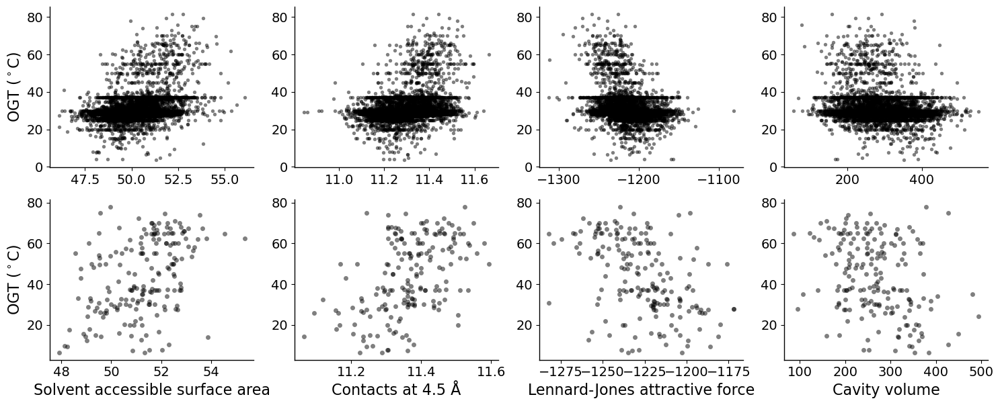

In [36]:
fig = plt.figure(figsize=(18, 18))

qstr = 'seq_length > 200'

for label, (i, metric),  in zip(['Solvent accessible surface area',
                                'Contacts at 4.5 Å',
                                'Lennard-Jones attractive force',
                                'Cavity volume'],
                                enumerate(best_metrics)):
    ax = fig.add_subplot(5, 4, i+1)
    
    sns.scatterplot(data=filtered.query(qstr), x=metric, y='mean_temp', 
                    zorder=i,
                    edgecolor='k', color='k', s=15,
                    linewidth=0, alpha=0.5
                   )
    plt.tick_params(labelsize=14)
    
    if i %  4 == 0:
        ax.set_ylabel('OGT ($^\circ$C)', fontsize=16)
    else:
        ax.set_ylabel('')
    ax.set_xlabel('')
        
    ax = fig.add_subplot(5, 4, i+5)

    sns.scatterplot(x=filtered.query(qstr).set_index('uid')[metric], 
                y=corkrey_full['T.C'],
                zorder=i,
                edgecolor='k', color='k', s=25,
                linewidth=0, alpha=0.5
               )

    if i %  4 == 0:
        ax.set_ylabel('OGT ($^\circ$C)', fontsize=16)
    else:
        ax.set_ylabel('')

    plt.tick_params(labelsize=14)
    ax.set_xlabel(f'{label}', fontsize=16)


sns.despine(fig)

In [37]:
spearman_results.head() 

,short_full,long_full
Contacts at 4.5 Å,0.032793,0.248879
SASA,0.079872,0.331031
bb_internal_hbonds,-0.056406,-0.014309
bbsc_internal_hbonds,-0.006811,0.000026
internal_hbonds,-0.073086,-0.09341


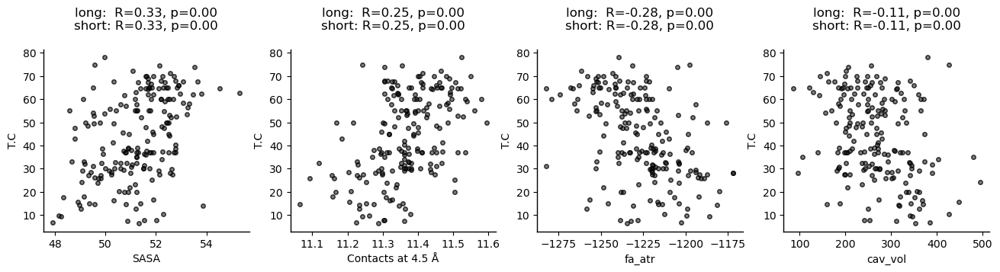

In [38]:
fig = plt.figure(figsize=(16, 18))
for i, metric in enumerate(best_metrics):
    ax = fig.add_subplot(5, 4, i+1)
    title = ''
    for qstr, color, iso, z in zip(['seq_length > 200', 'seq_length > 200'], ['k', 'w'], ['long: ', 'short:'], [1, 0]):
        sns.scatterplot(x=filtered.query(qstr).set_index('uid')[metric], 
                        y=corkrey_full['T.C'],
                        zorder=z,
                        edgecolor='k', color=color, s=15,
                        linewidth=1, alpha=0.5
                       )
        spR_result = spearmanr(filtered.query(qstr)[metric], filtered.query(qstr)['temp'])
        title += f'{iso} R={spR_result[0]:.02f}, p={spR_result[1]:.02f}\n'

        # spearman_results.loc[metric, iso] = spR_result[0]
    ax.set_title(title)
    # ax.get_legend().remove()
    # lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), title='filtered')

    
    

    # fileout = plot_filenames[metric] + '.svg'
    # plt.savefig(os.path.join(output_dir, figure_dir, fileout))

sns.despine(fig)

In [39]:
correlations = pd.DataFrame(index=metrics_to_plot + additional_metrics, columns=['short', 'long'])
for index, row in correlations.iterrows():
    for qstr, label in zip(['seq_length > 200', 'seq_length < 200'], ['long', 'short']):
        r = spearmanr(filtered.query(qstr)[index], filtered.query(qstr)['temp'])[0]
        correlations.loc[index, label] = r

In [40]:
corkrey_full

,T.C
match_accession,
GB_GCA_000010565.1,55.049954
GB_GCA_001048675.1,30.085010
GB_GCA_001584565.1,47.806192
GB_GCA_001610955.1,57.948399
GB_GCA_001644045.1,18.800483
...,...
RS_GCF_900215245.1,20.176672
RS_GCF_900215515.1,62.960696
RS_GCF_900215655.1,62.172489


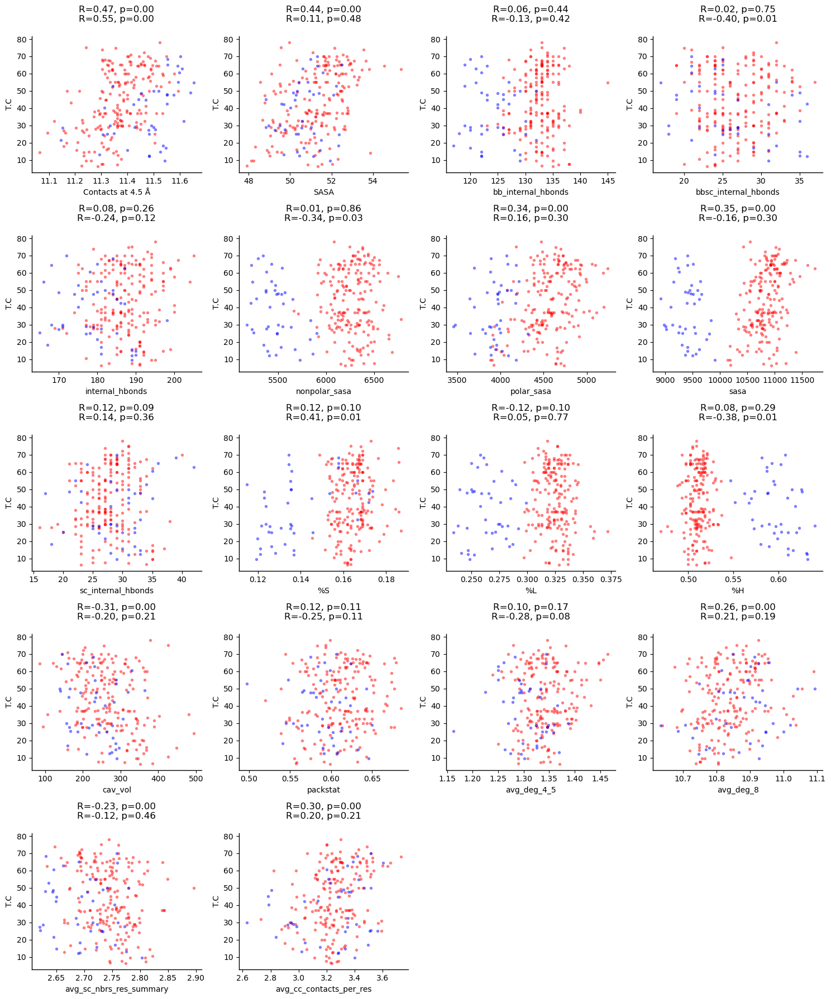

In [41]:
# first, plotting after filtering
fig = plt.figure(figsize=(15, 18))
for i, metric in enumerate(metrics_to_plot):
    ax = fig.add_subplot(5,4,i+1)
    title = ''
    for qstr, color in zip(['seq_length > 200', 'seq_length < 200'], ['r', 'b']):
        sns.scatterplot(x=filtered.query(qstr).set_index('uid')[metric], y=corkrey_full['T.C'], edgecolor=None, color=color, s=15,
                        linewidth=0, alpha=0.5
                       )
        shared = filtered.query(qstr).set_index('uid').reindex(corkrey_full.index)[metric].dropna().index
        spR_result = spearmanr(filtered.query(qstr).set_index('uid').reindex(shared)[metric], corkrey_full.reindex(shared)['T.C'])
        title += f'R={spR_result[0]:.02f}, p={spR_result[1]:.02f}\n'
    ax.set_title(title)
    # ax.get_legend().remove()
    # lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), title='filtered')

    
    

    # fileout = plot_filenames[metric] + '.svg'
    # plt.savefig(os.path.join(output_dir, figure_dir, fileout))

sns.despine(fig)
plt.tight_layout()

<Axes: xlabel='SASA', ylabel='temp'>

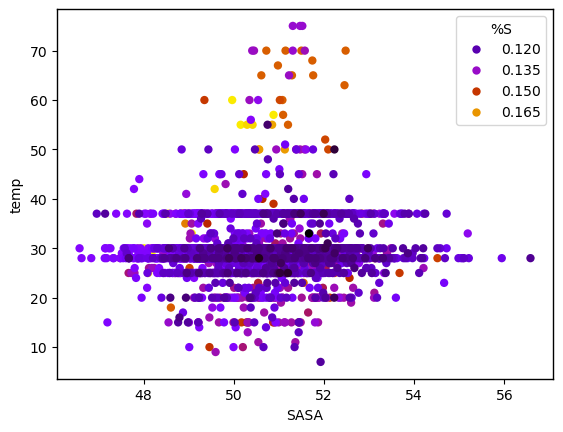

In [42]:
sns.scatterplot(data=filtered.query('seq_length < 200').sort_values('%S',ascending=False), x='SASA', y='temp', hue='%S', linewidth=0, palette='gnuplot')

In [43]:
original_df = pd.read_csv('/data/mhoffert/fiererlab/ogt/results/colabfold/genome2temp.csv')
original_df.shape

(61, 2)

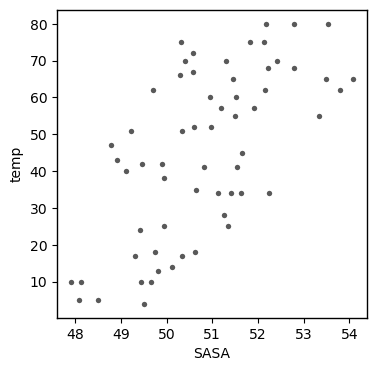

In [44]:
fig, ax = plt.subplots(figsize=(4,4))
subset = metrics_df.set_index('uid').loc[original_df['genome'], :]
sns.scatterplot(data=subset, x='SASA', y='temp', edgecolor=None, color='black', s=15,
                linewidth=0, alpha=0.65)
plt.show()

In [45]:
# subset = metrics_df[metrics_df['SASA'] < 55]
spearmanr(subset['SASA'], subset['temp'])

SignificanceResult(statistic=0.6269250570653655, pvalue=6.462382342386609e-08)

In [46]:
filtered['group'] = pd.cut(filtered['temp'], np.linspace(0, 100, 21))
filtered['group'].value_counts()

group
(25.0, 30.0]     5219
(35.0, 40.0]     1440
(20.0, 25.0]      770
(30.0, 35.0]      363
(15.0, 20.0]      219
(50.0, 55.0]       96
(45.0, 50.0]       80
(40.0, 45.0]       79
(10.0, 15.0]       74
(55.0, 60.0]       61
(60.0, 65.0]       45
(65.0, 70.0]       38
(5.0, 10.0]        21
(70.0, 75.0]       13
(75.0, 80.0]        7
(0.0, 5.0]          7
(80.0, 85.0]        0
(85.0, 90.0]        0
(90.0, 95.0]        0
(95.0, 100.0]       0
Name: count, dtype: int64

# Linear regression on structural data

In [187]:
import numpy as np
from scipy.stats import gaussian_kde
from sklearn.model_selection import train_test_split
from scipy.special import softmax

In [188]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KernelDensity
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score


### Test 1: melnikov temperatures

In [203]:
filtered = metrics_df[metrics_df['aligned_structure_len'] / metrics_df['length'] > 0.95].copy(deep=True)

In [204]:
metrics_df.columns

Index(['mean_total_sasa_fs', 'mean_polar_sasa_fs', 'mean_apolar_sasa_fs',
       'mean_delta_sasa', 'mean_norm_delta_sasa', 'mean_contacts_at_4.5',
       'total_total_sasa_fs', 'total_polar_sasa_fs', 'total_apolar_sasa_fs',
       'total_delta_sasa', 'total_norm_delta_sasa', 'total_contacts_at_4.5',
       'MM', 'MS', 'SM', 'SS', 'total', 'bb-sc', 'lidded', 'zinc', 'hbond',
       'total_score', 'avg_deg_4_5', 'avg_deg_8', 'avg_sc_nbrs_res_summary',
       'bb_internal_hbonds', 'bbsc_internal_hbonds', 'calc_bsa_apolar',
       'calc_bsa_total', 'cav_vol', 'internal_hbonds', 'nonpolar_sasa',
       'packstat', 'polar_sasa', 'sasa', 'sc_internal_hbonds',
       'total_cc_contacts', 'length', 'avg_cc_contacts_per_res', 'temp',
       'aligned_structure_len'],
      dtype='object')

In [205]:
drop_cols = ['Position', 'temp', 'mean_temp', 'uid', 'Unnamed: 0', 'lid_bitscore', 'total_score', 'seq_length', 'max_structure_length'] #, 'Genus', 'taxa', 'temp_group']
drop_cols = ['aligned_structure_len', 'temp']

In [206]:
X = filtered.drop(drop_cols, axis=1)
y = filtered['temp']

In [207]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=143)

In [208]:
X.shape

(8098, 39)

In [209]:
# function to get weights based on y variable density
def compute_gaussian_weights(_y):
    # Normalize the target variable to compute KDE
    scaler = StandardScaler()
    y_scaled = scaler.fit_transform(_y.values.reshape(-1, 1))
    
    # Estimate density of target variable using KDE
    kde = KernelDensity(kernel='gaussian', bandwidth=0.4)
    kde.fit(y_scaled)
    log_density = kde.score_samples(y_scaled)
    density = np.exp(log_density)
    
    # Compute weights as inverse of density
    weights = 1 / density

    return weights

In [210]:
print(y.shape)
weights = compute_gaussian_weights(y)
print(weights.shape)

# Fit weighted linear regression
model = LinearRegression()
model.fit(X, y, sample_weight=weights)

# Model predictions
y_pred = model.predict(X_test)

(8098,)
(8098,)


In [211]:
# Print results
print(f"Model coefficients: {model.coef_}")
print(f"Model intercept: {model.intercept_}")

mae = mean_absolute_error(y_test, y_pred)
print(f"MAE: {mae}")

mse = mean_squared_error(y_test, y_pred)
print(f"MSE: {mse}")

r2 = r2_score(y_test, y_pred)
print(f"R-squared: {r2}")

scores = cross_val_score(model, X_train, y_train, scoring='r2', cv=5)  # Example using R-squared
print(f"Cross-validated R-squared: {np.mean(scores):.2f} ± {np.std(scores):.2f}")

Model coefficients: [ 5.44475220e+10 -5.44475221e+10 -5.44475221e+10 ...  1.12391424e+00
 -9.77810077e+00 -2.19749393e+02]
Model intercept: 958.5827143322804
MAE: 8.490166128879443
MSE: 115.67832209160002
R-squared: -1.087167981141779
Cross-validated R-squared: 0.28 ± 0.03


In [212]:
def r2_score_variance_explained(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

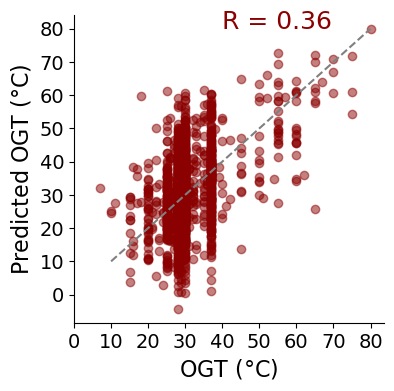

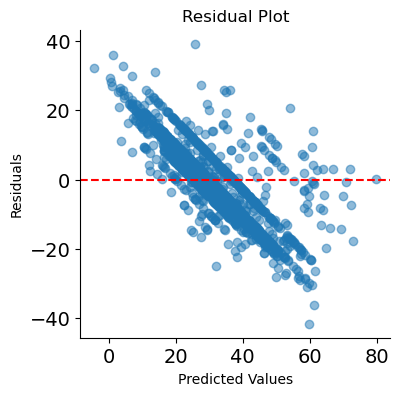

In [213]:
# Plot test dataset
fig, ax = plt.subplots(figsize=(4,4))
plt.scatter(y_test, y_pred, alpha=0.5, color='darkred')
plt.plot((10, 80), (10, 80), color='gray', linestyle='--')

plt.tick_params(labelsize=14)
plt.xlabel('OGT ($\degree$C)', fontsize=16)
plt.ylabel('Predicted OGT ($\degree$C)', fontsize=16)
ax.set_xticks(np.linspace(0, 80, 9))
ax.set_yticks(np.linspace(0, 80, 9))
sns.despine()

spr = spearmanr(y_test, y_pred)[0]
# spr = r2_score_variance_explained(y_test, y_pred)
ax.annotate(f'R = {spr:.2f}', (40, 80), color='darkred', fontsize=18)

plt.savefig('./../data/figures/linear_model_prediction_plot.png', dpi=400, bbox_inches='tight')
plt.show()

residuals = y_test - y_pred

# Plot residuals
fig, ax = plt.subplots(figsize=(4,4))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.tick_params(labelsize=14)
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residual Plot')
sns.despine()

plt.savefig('./../data/figures/linear_model_residual_plot.png', dpi=400, bbox_inches='tight')
plt.show()

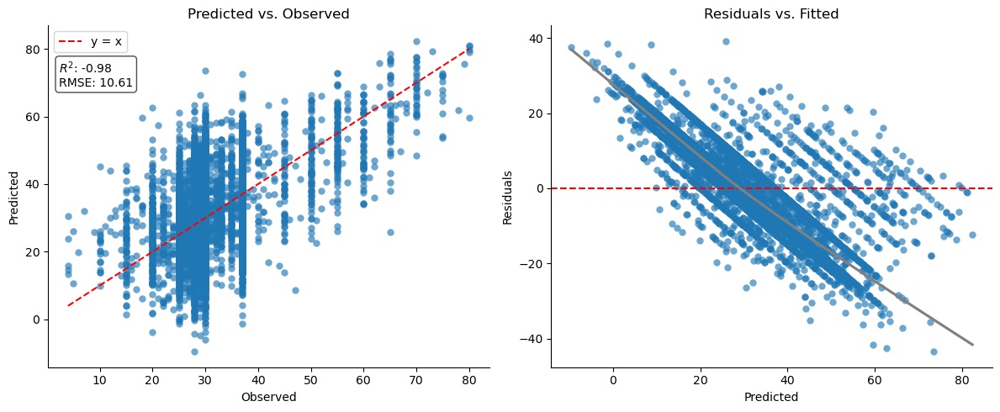

In [214]:

y_pred = model.predict(X)
rmse = np.sqrt(mean_squared_error(y, y_pred))
r2 = r2_score(y, y_pred)

# Plot
fig = plt.figure(figsize=(12, 5))

# 1. Predicted vs Observed
ax = fig.add_subplot(1,2,1)
sns.scatterplot(x=y, y=y_pred, ax=ax, linewidth=0, alpha=0.65)

ax.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', label='y = x')
ax.set_title('Predicted vs. Observed')
ax.set_xlabel('Observed')
ax.set_ylabel('Predicted')
ax.legend()
sns.despine()
ax.text(0.025, 0.9,
            f"$R^2$: {r2:.2f}\nRMSE: {rmse:.2f}",
            transform=ax.transAxes,
            fontsize=10,
            verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

# 2. Residuals vs Fitted
residuals = y - y_pred

ax = fig.add_subplot(1,2,2)
sns.scatterplot(x=y_pred, y=residuals, ax=ax, linewidth=0, alpha=0.65)
ax.axhline(0, color='red', linestyle='--')
sns.regplot(x=y_pred, y=residuals, lowess=True, scatter=False, ax=ax, color='gray')
ax.set_title('Residuals vs. Fitted')
ax.set_xlabel('Predicted')
ax.set_ylabel('Residuals')
sns.despine()

plt.tight_layout()
plt.show()

## Next attempt: simpler model with length * feature values

In [215]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from scipy.stats import t
from scipy.ndimage import uniform_filter1d
from sklearn.linear_model import Ridge
import statsmodels.api as sm

from sklearn.decomposition import PCA
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.nonparametric.smoothers_lowess import lowess
from tqdm import tqdm


In [217]:
X = filtered.drop(drop_cols, axis=1)
y = filtered[['temp']]

X_length = (X['length'] * X.T).T 
X_length = X_length.rename(columns=dict((col, f'{col}_x_length') for col in X_length.columns))
X_original = pd.concat([X, X_length], axis=1)


Text(0.025, 0.9, '$R^2$: -1.05\nRMSE: 10.81')

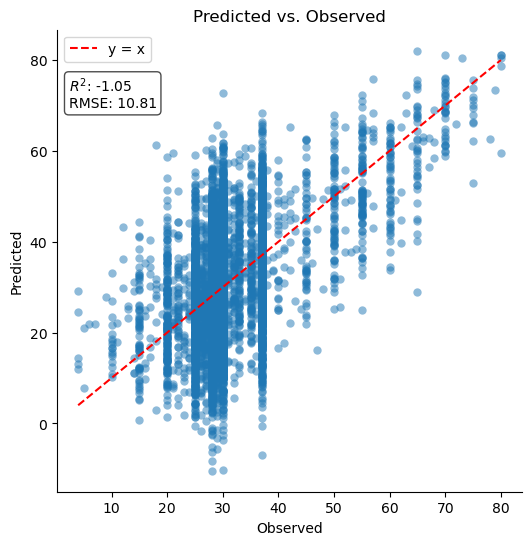

In [218]:
scaler = StandardScaler().fit(X_original)
X = scaler.transform(X_original)

y_scaler = StandardScaler().fit(y)
y_scaled = y_scaler.transform(y)

# # Create pipeline to include interaction (without higher-order powers)
# poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=True).fit(X)
# X_poly = poly.transform(X)

weights = compute_gaussian_weights(y['temp'])

model = sm.WLS(y_scaled, X, weights=weights).fit()
y_pred_scaled = pd.Series(model.get_prediction(X).predicted_mean)
y_pred = pd.Series(index=y.index,
                   data=y_scaler.inverse_transform(pd.DataFrame(y_pred_scaled)).ravel())
ci = model.conf_int()
lower = ci[:, 0]
upper = ci[:, 1]

# 1. Predicted vs Observed
fig, ax = plt.subplots(figsize=(6,6))
sns.scatterplot(x=y['temp'], y=y_pred, ax=ax, linewidth=0, alpha=0.5)
# sns.regplot(x=y, y=y_pred, ci=95, line_kws={"color": "black"}, scatter_kws={"s": 30})

ax.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', label='y = x')
ax.set_title('Predicted vs. Observed')
ax.set_xlabel('Observed')
ax.set_ylabel('Predicted')
ax.legend()
sns.despine()

# intervals = pd.DataFrame([lower, upper, y_pred], index=['lower', 'upper', 'y']).T.dropna().sort_values('y')
# intervals = intervals.apply(lambda col: uniform_filter1d(col, size=window)).sort_values('y')

# sns.lineplot(data=intervals, x='y', y='lower', color='k', linewidth=0.25)
# sns.lineplot(data=intervals, x='y', y='upper', color='k', linewidth=0.25)
# ax.fill_between(intervals['y'], intervals['lower'], intervals['upper'], color='gray', alpha=0.25)

rmse = np.sqrt(mean_squared_error(y['temp'], pd.Series(data=y_pred.ravel(), index=y.index)))
r2 = r2_score(y, y_pred)

ax.text(0.025, 0.9,
            f"$R^2$: {r2:.2f}\nRMSE: {rmse:.2f}",
            transform=ax.transAxes,
            fontsize=10,
            verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

In [219]:
pd.Series(data=model.bse, index=X_original.columns).sort_values(ascending=False).head(10) #.summary()

sasa_x_length                     744426.728585
nonpolar_sasa_x_length            450671.716154
sasa                              396485.965248
polar_sasa_x_length               333056.464620
nonpolar_sasa                     252995.743487
polar_sasa                        212588.316871
total_delta_sasa_x_length            189.244419
total_norm_delta_sasa_x_length       180.983676
mean_delta_sasa_x_length             105.251108
total_delta_sasa                     103.980767
dtype: float64

In [40]:
sasa_columns = [c for c in filtered.columns if 'sasa' in c]

#### Notes
dropping "sasa"-containing columns in subsequent models cause they're looking whacky and have very large standard error

## Improved model - conditional terms, scaling, confidence intervals

In [220]:
from sklearn.linear_model import ElasticNetCV
from collections import defaultdict

In [221]:
filtered.columns

Index(['mean_total_sasa_fs', 'mean_polar_sasa_fs', 'mean_apolar_sasa_fs',
       'mean_delta_sasa', 'mean_norm_delta_sasa', 'mean_contacts_at_4.5',
       'total_total_sasa_fs', 'total_polar_sasa_fs', 'total_apolar_sasa_fs',
       'total_delta_sasa', 'total_norm_delta_sasa', 'total_contacts_at_4.5',
       'MM', 'MS', 'SM', 'SS', 'total', 'bb-sc', 'lidded', 'zinc', 'hbond',
       'total_score', 'avg_deg_4_5', 'avg_deg_8', 'avg_sc_nbrs_res_summary',
       'bb_internal_hbonds', 'bbsc_internal_hbonds', 'calc_bsa_apolar',
       'calc_bsa_total', 'cav_vol', 'internal_hbonds', 'nonpolar_sasa',
       'packstat', 'polar_sasa', 'sasa', 'sc_internal_hbonds',
       'total_cc_contacts', 'length', 'avg_cc_contacts_per_res', 'temp',
       'aligned_structure_len'],
      dtype='object')

In [870]:
sasa_columns

['nonpolar_sasa', 'polar_sasa', 'sasa']

In [222]:
drop_cols = ['temp', 'aligned_structure_len']
    
# ['uid','Position',
#  'temp',
#  'mean_temp',
#  'Unnamed: 0',
#  'lid_bitscore',
#  'total_score',
#  'seq_length',
#  'max_structure_length',
#              'dslf_fa13',
#  #'temp_group',
# 'bitscore', 'C', 'L', 'N', 'P', '%S', '%L', '%H', 'max_structure_length']

In [223]:
filtered.columns

Index(['mean_total_sasa_fs', 'mean_polar_sasa_fs', 'mean_apolar_sasa_fs',
       'mean_delta_sasa', 'mean_norm_delta_sasa', 'mean_contacts_at_4.5',
       'total_total_sasa_fs', 'total_polar_sasa_fs', 'total_apolar_sasa_fs',
       'total_delta_sasa', 'total_norm_delta_sasa', 'total_contacts_at_4.5',
       'MM', 'MS', 'SM', 'SS', 'total', 'bb-sc', 'lidded', 'zinc', 'hbond',
       'total_score', 'avg_deg_4_5', 'avg_deg_8', 'avg_sc_nbrs_res_summary',
       'bb_internal_hbonds', 'bbsc_internal_hbonds', 'calc_bsa_apolar',
       'calc_bsa_total', 'cav_vol', 'internal_hbonds', 'nonpolar_sasa',
       'packstat', 'polar_sasa', 'sasa', 'sc_internal_hbonds',
       'total_cc_contacts', 'length', 'avg_cc_contacts_per_res', 'temp',
       'aligned_structure_len'],
      dtype='object')

ElasticNet alpha: 0.025195475303616887 l1_ratio: 0.1
Nonzero coefficients:
 mean_total_sasa_fs    0.592892
length                0.714466
sasa                  1.257391
dtype: float64


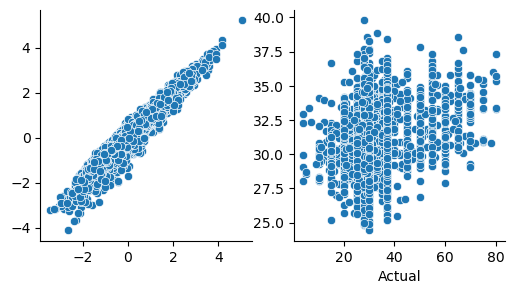

In [260]:
# test - does an ENETCV with two redundant columns lead to one of the columns getting dropped?

X_test = filtered[['sasa', 
                   'mean_total_sasa_fs', 
                   'length']].copy(deep=True)
y_test = filtered['temp']
X_test['sasa'] = X_test['sasa'] / X_test['length'] 
# X_test = X_test.drop('length', axis=1)

# X_test = filtered[['mean_total_sasa_fs']].copy()

scaler_input = StandardScaler()
X_test_scaled = scaler_input.fit_transform(X_test)

enet = ElasticNetCV(l1_ratio=[0.001, 0.1, .5, .75, .9, 1.0], cv=5, n_alphas=100, max_iter=5000)
enet.fit(X_test_scaled, y_test)
print("ElasticNet alpha:", enet.alpha_, "l1_ratio:", enet.l1_ratio_)
coef_series = pd.Series(enet.coef_, index=X_test.columns)
print("Nonzero coefficients:\n", coef_series[coef_series.abs() > 1e-6].sort_values())

fig= plt.figure(figsize=(6,3))

ax = fig.add_subplot(1,2,1)
sns.scatterplot(x=X_test_scaled[:, 0],
               y=X_test_scaled[:, 1])
sns.despine()

ax = fig.add_subplot(1,2,2)
sns.scatterplot(y=enet.predict(X_test_scaled),
                x=y_test)
ax.set_xlabel('Actual')
sns.despine()

#### Notes
The total effect of "sasa" and "mean_total_sasa_fs" is the same ... I want to try a likelihood ratio test on models with different inputs to see which is best

In [261]:

def compute_log_likelihood(model, X, y):
    """
    Computes the log-likelihood of a linear model assuming normally distributed errors.
    Best used on OLS refitted models (Post-ElasticNet).
    """
    n = len(y)
    predictions = model.predict(X)
    rss = np.sum((y - predictions) ** 2)
    mse = rss / n
    
    # Gaussian log-likelihood formula
    log_lik = -0.5 * n * (np.log(2 * np.pi) + np.log(mse) + 1)
    return log_lik

def likelihood_ratio_test(model_simple, model_complex, X_simple, X_complex, y):
    """
    Performs a Likelihood Ratio Test between a simple (nested) and complex model.
    """
    ll_simple = compute_log_likelihood(model_simple, X_simple, y)
    ll_complex = compute_log_likelihood(model_complex, X_complex, y)
    
    # LRT Statistic: 2 * (LL_complex - LL_simple)
    lr_stat = 2 * (ll_complex - ll_simple)
    
    # Degrees of freedom difference (difference in number of predictors)
    df_simple = X_simple.shape[1]
    df_complex = X_complex.shape[1]
    df_diff = df_complex - df_simple
    
    if df_diff <= 0:
        raise ValueError("The complex model must have more predictors than the simple model.")
        
    # Compute p-value from Chi-squared distribution
    p_value = stats.chi2.sf(lr_stat, df=df_diff)
    
    return {
        "LR Statistic": lr_stat,
        "Degrees of Freedom Diff": df_diff,
        "p-value": p_value
    }

In [262]:
inputs = [['sasa', 'mean_total_sasa_fs', 'length'],
         ['mean_total_sasa_fs', 'length'],
         ['sasa', 'length'],
         ['sasa'],
         ['mean_total_sasa_fs']]

models = []
Xs = []
for _input in inputs:
    X_test = filtered[_input].copy(deep=True)
    y_test = filtered['temp']
    # if 'length' in _input and 'sasa' in _input:
    #     X_test['sasa'] = X_test['sasa'] / X_test['length'] 
    
    scaler_input = StandardScaler()
    X_test_scaled = scaler_input.fit_transform(X_test)
    Xs.append(X_test_scaled)
    
    model = LinearRegression().fit(X_test_scaled, y_test)
    models.append(model)

In [263]:
lls = [compute_log_likelihood(models[i], Xs[i], y_test) for i in range(len(models))]
lls

[-27565.53072239391,
 -27596.13880298372,
 -27567.012483667997,
 -27754.80256466308,
 -27626.250748324554]

In [265]:
# does including length make SASA better?
likelihood_ratio_test(models[3], models[2], Xs[3], Xs[2], y_test)

{'LR Statistic': 375.58016199016856,
 'Degrees of Freedom Diff': 1,
 'p-value': 1.1408907913791643e-83}

In [266]:
# does including mean_sasa make the model better?
likelihood_ratio_test(models[2], models[0], Xs[2], Xs[0], y_test)

{'LR Statistic': 2.9635225481761154,
 'Degrees of Freedom Diff': 1,
 'p-value': 0.08516222286919845}

In [256]:
# model with two definitions of SASA versus 1
likelihood_ratio_test(models[1], models[0], Xs[1], Xs[0], y_test)

{'LR Statistic': 61.21616117962549,
 'Degrees of Freedom Diff': 1,
 'p-value': 5.114001274255384e-15}

<Axes: xlabel='sasa', ylabel='mean_total_sasa_fs'>

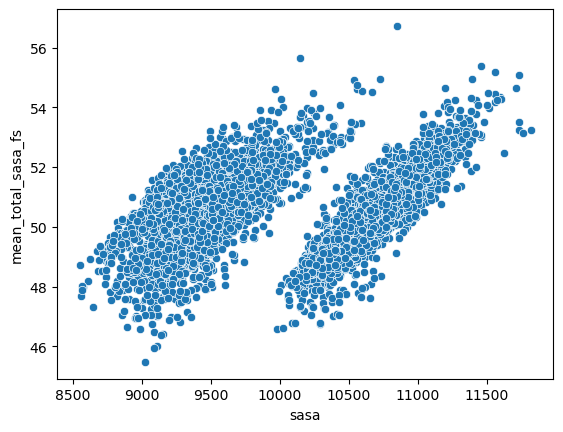

In [251]:
sns.scatterplot(data=filtered, x='sasa', y='mean_total_sasa_fs')

#### Notes 
The definitions of sasa are somewhat redundant, but for some reason the Rosetta-based LeGrand statistic is more correlated. Because it's less defensible, I'm going to eliminate it from the model.

In [269]:
metrics_df.columns

Index(['mean_total_sasa_fs', 'mean_polar_sasa_fs', 'mean_apolar_sasa_fs',
       'mean_delta_sasa', 'mean_norm_delta_sasa', 'mean_contacts_at_4.5',
       'total_total_sasa_fs', 'total_polar_sasa_fs', 'total_apolar_sasa_fs',
       'total_delta_sasa', 'total_norm_delta_sasa', 'total_contacts_at_4.5',
       'MM', 'MS', 'SM', 'SS', 'total', 'bb-sc', 'lidded', 'zinc', 'hbond',
       'total_score', 'avg_deg_4_5', 'avg_deg_8', 'avg_sc_nbrs_res_summary',
       'bb_internal_hbonds', 'bbsc_internal_hbonds', 'calc_bsa_apolar',
       'calc_bsa_total', 'cav_vol', 'internal_hbonds', 'nonpolar_sasa',
       'packstat', 'polar_sasa', 'sasa', 'sc_internal_hbonds',
       'total_cc_contacts', 'length', 'avg_cc_contacts_per_res', 'temp',
       'aligned_structure_len'],
      dtype='object')

In [706]:
drop_from_model = ['mean_norm_delta_sasa', 'total_total_sasa_fs', 'total_polar_sasa_fs', 'total_apolar_sasa_fs',
       'total_delta_sasa', 'total_norm_delta_sasa', 'total_contacts_at_4.5', 'calc_bsa_apolar',
       'calc_bsa_total', 'polar_sasa', 'sasa', 'nonpolar_sasa', 'temp', 'aligned_structure_len', 'total_cc_contacts', 'lidded']
kept_in_model = list(set(list(filtered.columns)) - set(drop_from_model))

In [707]:
%%time
# make matrix of correlations between variables
dists = filtered[kept_in_model].corr(method='spearman')

CPU times: user 63.8 ms, sys: 3.16 ms, total: 67 ms
Wall time: 63.6 ms


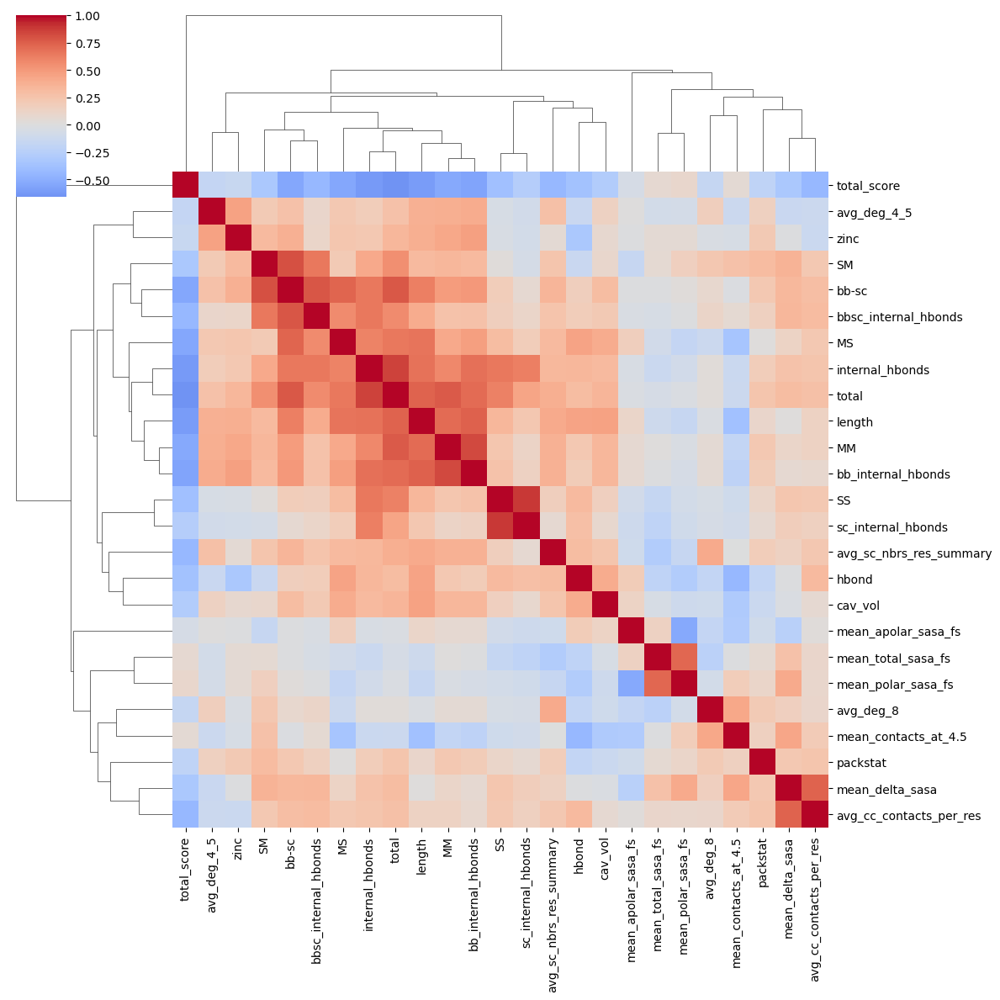

In [708]:
# fig, ax = plt.subplots(figsize=(8,8))
g = sns.clustermap(dists, cmap='coolwarm', center=0, figsize=(12,12))
g.ax_heatmap.set_aspect('equal')

In [709]:
# length_scaled = ['lk_ball_wtd',
#  'sc_internal_hbonds',
#  'fa_intra_sol_xover4',
#  'hbond_sr_bb',
#  'pro_close',
#  'fa_intra_rep',
#  'dslf_fa13',
#  'cav_vol',
#  'hbond_lr_bb',
#  'fa_dun',
#  'packstat',
#  'fa_rep',
#  'bbsc_internal_hbonds',
#  'omega',
#  'hbond_bb_sc',
#  'hbond_sc',
#  'bb_internal_hbonds',
#  'fa_elec',
#  'fa_sol',
#  'total_cc_contacts',
#  'fa_atr',
#  'nonpolar_sasa', 'polar_sasa']

In [710]:
# set up X
X_original = filtered.drop(drop_from_model, axis=1)
# clean up columns
X_original = X_original.rename(columns=dict((c, c.replace(' ', '_')) for c in X_original.columns))
y = filtered[['temp']]

# scale y
y_scaler = StandardScaler().fit(y)
y_scaled = y_scaler.transform(y)
y_scaled = pd.Series(data=y_scaled[:, 0],
          index=y.index)

# X = X_original.copy()

# # try modifying cols by length
# for col in X.columns:
#     if col in length_scaled:
#         X[f'{col}_per_res'] = X[col] / X['length']
#         X.drop(col, axis=1, inplace=True)

# scale X
scaler_input = StandardScaler()

X_scaled = pd.DataFrame(index=X_original.index, 
                 data=scaler_input.fit_transform(X_original),
                columns=X_original.columns)
        
# X = X.drop('length', axis=1)




# X_poly = X.copy()


# X_poly.drop('length', axis=1, inplace=True)

# Create pipeline to include interaction (without higher-order powers)
# poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=True).fit(X)
# X_poly = pd.DataFrame(index=X.index, columns=poly.get_feature_names_out(X.columns),data=poly.transform(X))
X_scaled.columns

Index(['mean_total_sasa_fs', 'mean_polar_sasa_fs', 'mean_apolar_sasa_fs',
       'mean_delta_sasa', 'mean_contacts_at_4.5', 'MM', 'MS', 'SM', 'SS',
       'total', 'bb-sc', 'zinc', 'hbond', 'total_score', 'avg_deg_4_5',
       'avg_deg_8', 'avg_sc_nbrs_res_summary', 'bb_internal_hbonds',
       'bbsc_internal_hbonds', 'cav_vol', 'internal_hbonds', 'packstat',
       'sc_internal_hbonds', 'length', 'avg_cc_contacts_per_res'],
      dtype='object')

In [776]:
X_scaled

,mean_total_sasa_fs,mean_polar_sasa_fs,mean_apolar_sasa_fs,mean_delta_sasa,mean_contacts_at_4.5,MM,MS,SM,SS,total,...,avg_deg_8,avg_sc_nbrs_res_summary,bb_internal_hbonds,bbsc_internal_hbonds,cav_vol,internal_hbonds,packstat,sc_internal_hbonds,length,avg_cc_contacts_per_res
GB_GCA_000016765.1,-0.767623,-0.692970,0.041821,-1.630812,-1.820492,0.314458,0.401170,0.290888,0.273012,0.467990,...,-1.194029,-0.683869,0.521029,0.865199,-1.409961,1.252312,1.107786,1.203089,0.752387,-1.613757
GB_GCA_000283575.1,-0.305403,-0.347749,0.117130,-0.832256,-0.488320,0.867520,0.401170,-1.238894,-0.761740,-0.217323,...,0.701623,0.729215,-0.053780,-1.585956,1.195951,-1.293069,-1.106305,-1.177646,0.370554,-1.526106
GB_GCA_000376885.1,1.598651,1.244715,0.189721,-0.167170,0.390808,-0.607312,-1.454331,-1.493858,-1.796492,-1.930605,...,-0.814898,-1.619559,-1.011797,-1.340841,-0.987310,-1.929415,-0.082100,-1.610507,-1.385878,-0.236073
GB_GCA_000423665.1,1.062446,2.326908,-1.965673,1.565957,0.425869,1.789290,-0.217330,1.820670,0.686913,1.667287,...,-0.251619,-0.263763,2.245459,0.865199,1.221393,1.676542,-1.558161,0.120937,0.981487,0.634282
GB_GCA_000717275.1,-0.071786,0.080112,-0.198219,-0.819284,-0.693238,-1.897790,-1.145081,-0.474003,-1.382591,-1.930605,...,0.539139,0.652832,-1.969813,-0.360379,-0.968173,-1.929415,1.243342,-1.394076,-1.844077,-0.404744
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RS_GCF_904846715.1,-0.532596,0.319669,-1.087477,-0.385246,-1.632174,-0.238604,1.328920,0.035924,0.893863,0.639318,...,-0.359942,0.423683,0.521029,0.620084,-0.366514,1.252312,0.098642,1.419520,0.981487,-0.482843
RS_GCF_904848165.1,0.458218,1.657362,-1.759687,0.165925,-1.457232,0.683166,0.710420,0.035924,2.135566,1.410295,...,-0.663246,0.901076,0.521029,0.129853,0.361981,1.252312,0.580621,1.852381,0.905121,0.143634
RS_GCF_907163105.1,-0.037995,-0.110513,0.108371,2.666754,1.715407,0.498812,-1.763581,0.035924,2.342516,0.724982,...,2.066492,0.099056,-0.245384,-0.360379,-0.427278,0.615967,0.038395,1.852381,-0.927678,2.033248
RS_GCF_907163265.1,-1.014117,-1.625691,1.045836,0.309995,-0.996918,-0.054250,0.401170,1.055779,0.686913,0.724982,...,0.235835,1.111129,0.137823,0.865199,0.577642,0.934139,-1.347295,0.986659,0.905121,1.999701


ElasticNet alpha: 0.005049859502478702 l1_ratio: 0.5
Nonzero coefficients:
 total_score               -0.251090
internal_hbonds           -0.134316
bbsc_internal_hbonds      -0.060150
avg_sc_nbrs_res_summary   -0.050010
MM                        -0.045739
packstat                  -0.030292
SM                        -0.029597
avg_cc_contacts_per_res   -0.012738
cav_vol                   -0.008042
avg_deg_8                  0.007805
mean_apolar_sasa_fs        0.010306
avg_deg_4_5                0.018517
hbond                      0.023616
MS                         0.036652
mean_delta_sasa            0.155618
mean_contacts_at_4.5       0.162510
mean_total_sasa_fs         0.188284
zinc                       0.261857
dtype: float64


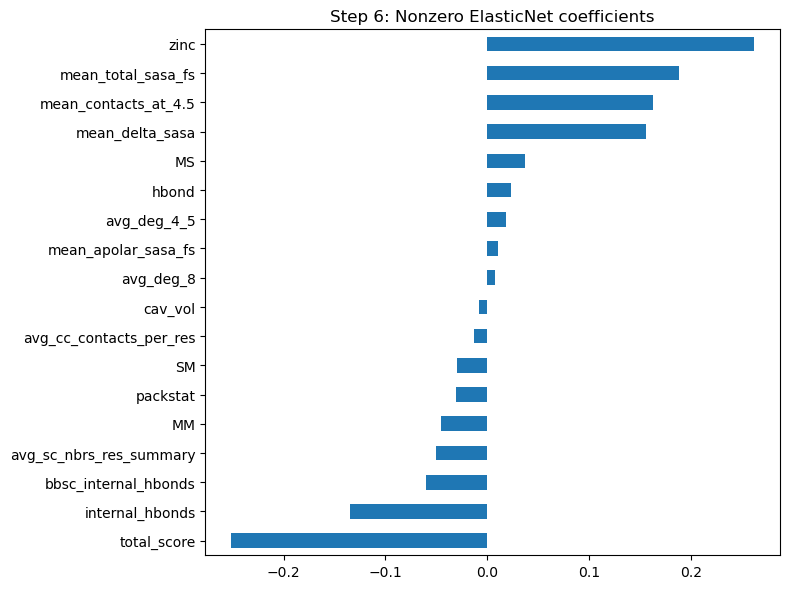

In [711]:
# elastic net
# --- 6) Fit penalized model (elastic net CV) to select among linear and quadratic terms ---
enet = ElasticNetCV(l1_ratio=[.5, .75, .9, 1.0], cv=5, n_alphas=100, max_iter=5000)
enet.fit(X_scaled, y_scaled)
print("ElasticNet alpha:", enet.alpha_, "l1_ratio:", enet.l1_ratio_)
coef_series = pd.Series(enet.coef_, index=X_scaled.columns)
print("Nonzero coefficients:\n", coef_series[coef_series.abs() > 1e-6].sort_values())

# --- STEP 6: Coefficients from ElasticNet ---
fig, ax = plt.subplots(figsize=(8,6))
coef_series[coef_series.abs()>1e-6].sort_values().plot(kind="barh")
plt.title("Step 6: Nonzero ElasticNet coefficients")
plt.tight_layout()
plt.show()

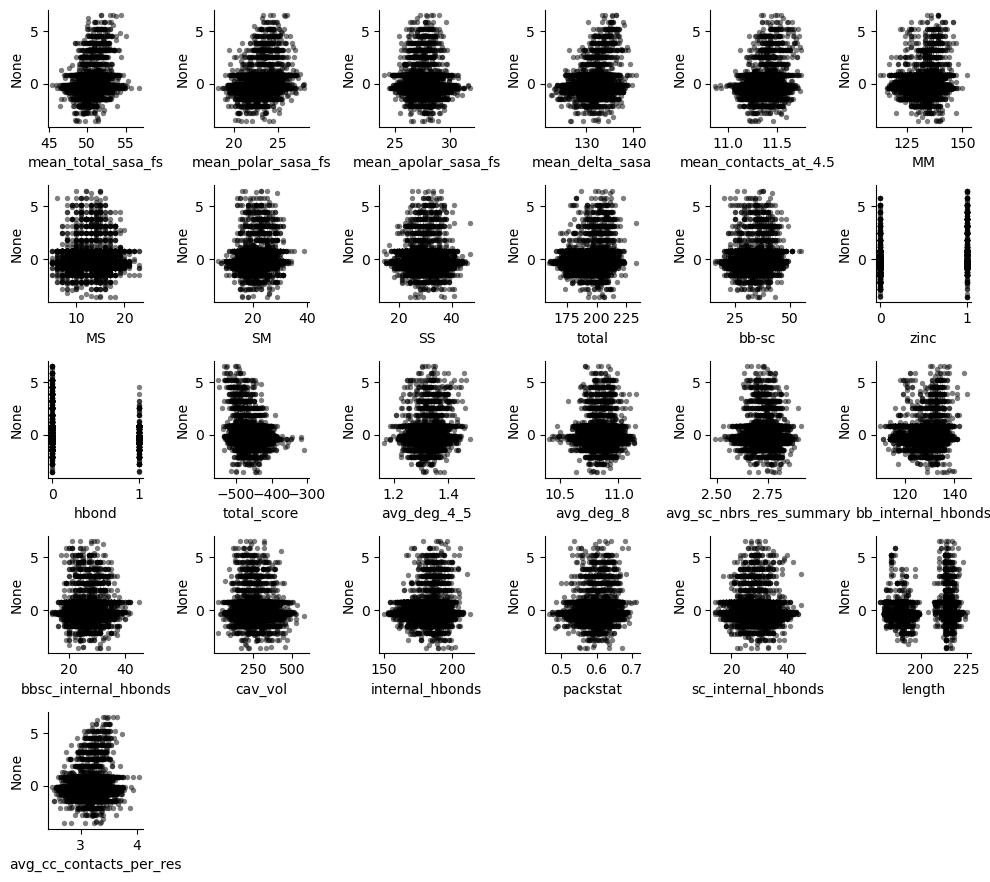

In [712]:
# first, plotting after filtering
fig = plt.figure(figsize=(10, 12))
for i, metric in enumerate(X_scaled.columns):
    ax = fig.add_subplot(7,6,i+1)
    sns.scatterplot(data=metrics_df, x=metric, y=y_scaled, edgecolor=None, color='black', s=15,
                    linewidth=0, alpha=0.5, 
                   )
    sns.despine(fig)
    plt.tight_layout()

In [713]:
X_final = sm.add_constant(X_scaled[coef_series[coef_series.abs()>1e-6].index])
X_final['zinc'] = X_final['zinc'].astype(int)
X_final['hbond'] = X_final['hbond'].astype(int)

In [714]:
X_final.astype(float)

,const,mean_total_sasa_fs,mean_apolar_sasa_fs,mean_delta_sasa,mean_contacts_at_4.5,MM,MS,SM,zinc,hbond,total_score,avg_deg_4_5,avg_deg_8,avg_sc_nbrs_res_summary,bbsc_internal_hbonds,cav_vol,internal_hbonds,packstat,avg_cc_contacts_per_res
GB_GCA_000016765.1,1.0,-0.767623,0.041821,-1.630812,-1.820492,0.314458,0.401170,0.290888,1.0,0.0,0.498251,-0.170950,-1.194029,-0.683869,0.865199,-1.409961,1.252312,1.107786,-1.613757
GB_GCA_000283575.1,1.0,-0.305403,0.117130,-0.832256,-0.488320,0.867520,0.401170,-1.238894,1.0,0.0,0.406949,1.700135,0.701623,0.729215,-1.585956,1.195951,-1.293069,-1.106305,-1.526106
GB_GCA_000376885.1,1.0,1.598651,0.189721,-0.167170,0.390808,-0.607312,-1.454331,-1.493858,0.0,0.0,0.360180,-1.131777,-0.814898,-1.619559,-1.340841,-0.987310,-1.929415,-0.082100,-0.236073
GB_GCA_000423665.1,1.0,1.062446,-1.965673,1.565957,0.425869,1.789290,-0.217330,1.820670,0.0,0.0,-0.362469,0.183039,-0.251619,-0.263763,0.865199,1.221393,1.676542,-1.558161,0.634282
GB_GCA_000717275.1,1.0,-0.071786,-0.198219,-0.819284,-0.693238,-1.897790,-1.145081,-0.474003,0.0,0.0,1.496866,-0.904212,0.539139,0.652832,-0.360379,-0.968173,-1.929415,1.243342,-0.404744
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RS_GCF_904846715.1,1.0,-0.532596,-1.087477,-0.385246,-1.632174,-0.238604,1.328920,0.035924,0.0,2.0,-0.256627,0.891017,-0.359942,0.423683,0.620084,-0.366514,1.252312,0.098642,-0.482843
RS_GCF_904848165.1,1.0,0.458218,-1.759687,0.165925,-1.457232,0.683166,0.710420,0.035924,0.0,2.0,-0.139005,0.233609,-0.663246,0.901076,0.129853,0.361981,1.252312,0.580621,0.143634
RS_GCF_907163105.1,1.0,-0.037995,0.108371,2.666754,1.715407,0.498812,-1.763581,0.035924,0.0,0.0,-1.044013,-0.828358,2.066492,0.099056,-0.360379,-0.427278,0.615967,0.038395,2.033248
RS_GCF_907163265.1,1.0,-1.014117,1.045836,0.309995,-0.996918,-0.054250,0.401170,1.055779,0.0,2.0,0.133430,0.006045,0.235835,1.111129,0.865199,0.577642,0.934139,-1.347295,1.999701


In [715]:
def plot_model(model, y, y_scaler, X, x_scaler, save=None):
    

    y_pred = pd.Series(data=model.get_prediction(X).predicted_mean, index=y.index)
    y_pred = y_pred.map(lambda y_unsc: y_scaler.inverse_transform([[y_unsc]])[0][0])
    residuals = y - y_pred
    print("Condition number of X", np.linalg.cond(X))
    print("Size of X", X.shape)

    rmse = np.sqrt(mean_squared_error(y, y_pred))
    r2 = spearmanr(y, y_pred)[0]
    
    fig = plt.figure(figsize=(7, 4))

    # 1. Predicted vs Observed
    ax = fig.add_subplot(1,2,1)
    
    # plot of regression vals
    sns.scatterplot(x=y, y=y_pred, ax=ax, linewidth=0, alpha=0.5, s=15, color='k')
    
    # guiding x = y line
    ax.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', label='y = x')

    # # box w/ stats
    # ax.text(0.03, 0.95,
    #             f"$Spearman R$: {r2:.2f}\nRMSE: {rmse:.2f}",
    #             transform=ax.transAxes,
    #             fontsize=10,
    #             verticalalignment='top',
    #             bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))
    
    ax.set_ylabel('Fitted values', fontsize=16)
    ax.set_xlabel('Actual values', fontsize=16)

    
    # get cis
    pred_scaled = model.get_prediction(X)
    pred_summary = pred_scaled.summary_frame(alpha=0.05)  # 95% CI
    
    # upper and lower
    ci_lower = pred_summary['mean_ci_lower'].values
    ci_upper = pred_summary['mean_ci_upper'].values
    
    # make a df
    ci_df = pd.DataFrame({
        'y': y,         # your original x-axis variable
        'pred': y_pred,           # predicted y
        'lower': ci_lower,      # lower CI
        'upper': ci_upper       # upper CI
    }).sort_values('y')
    
    # smooth w/ loess
    smoothed_lower = lowess(ci_df['lower'], ci_df['y'], frac=0.1, return_sorted=False)
    smoothed_upper = lowess(ci_df['upper'], ci_df['y'], frac=0.1, return_sorted=False)
    
    # 2. Residuals vs Fitted
    ax = fig.add_subplot(1,2,2)
    sns.scatterplot(x=y, y=residuals, ax=ax, linewidth=0, alpha=0.65, s=2, color='k')
    for vline in list(range(20, 40, 5)) + [28, 37]:
        ax.axvline(vline, zorder=0, linestyle='--', color='gray')
    ax.axhline(0, color='red', linestyle='--')
    sns.regplot(x=y, y=residuals, lowess=True, scatter=False, ax=ax, color='gray')
    ax.set_title('residuals vs. actual')
    ax.set_xlabel('Actual')
    ax.set_ylabel('Residuals')
    sns.despine()
    
    plt.tight_layout()
    if save is not None:
        if '.png' in save:
            kwargs = {'dpi':400}
        else:
            kwargs = {}
        plt.savefig(save, **kwargs)
    plt.show()


In [716]:
weights = compute_gaussian_weights(y_scaled)

model = sm.GLM(y_scaled, 
               X_final.values, 
               family=sm.families.Gaussian(), 
               var_weights=weights
              ).fit(cov_type='HC3')

model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                      y   No. Observations:                 8098
Model:                            GLM   Df Residuals:                     8079
Model Family:                Gaussian   Df Model:                           18
Link Function:               Identity   Scale:                          30.670
Method:                          IRLS   Log-Likelihood:                -21035.
Date:                Wed, 20 May 2026   Deviance:                   2.4778e+05
Time:                        21:02:07   Pearson chi2:                 2.48e+05
No. Iterations:                     3   Pseudo R-squ. (CS):             0.8506
Covariance Type:                  HC3                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.3643      0.155     -2.350      0.019      -0.668      -0.060
x1             0.8404      0.095      8.831      0.000       0.654       1.027
x2            -0.2011      0.121     -1.661      0.097      -0.438       0.036
x3             0.0076      0.164      0.046      0.963      -0.314       0.329
x4             0.6744      0.099      6.827      0.000       0.481       0.868
x5            -0.4237      0.145     -2.925      0.003      -0.708      -0.140
x6             0.2450      0.126      1.939      0.053      -0.003       0.493
x7            -0.2542      0.170     -1.492      0.136      -0.588       0.080
x8             1.7050      0.274      6.234      0.000       1.169       2.241
x9            -0.0563      0.155     -0.364      0.716      -0.360       0.247
x10           -1.2101      0.149     -8.097      0.000      -1.503      -0.917
x11            0.1394      0.097      1.440      0.150      -0.050       0.329
x12            0.4884      0.118      4.126      0.000       0.256       0.720
x13           -0.4389      0.117     -3.742      0.000      -0.669      -0.209
x14           -0.1749      0.174     -1.005      0.315      -0.516       0.166
x15           -0.0270      0.082     -0.331      0.740      -0.187       0.133
x16           -0.2430      0.177     -1.372      0.170      -0.590       0.104
x17           -0.2745      0.133     -2.058      0.040      -0.536      -0.013
x18            0.3451      0.149      2.312      0.021       0.053       0.638
==============================================================================
"""

Condition number of X 7.992147848111592
Size of X (8098, 19)


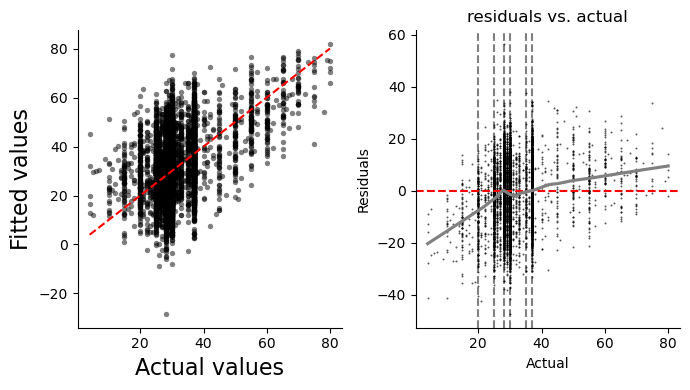

In [717]:
plot_model(model, y['temp'], y_scaler, X_final, scaler_input,
          './../data/figures/20260513_structure_smGLM.png')

In [718]:
pvals = pd.Series(data=model.pvalues.values,
          index=X_final.columns).sort_values()
pvals

mean_total_sasa_fs         1.040651e-18
total_score                5.634943e-16
mean_contacts_at_4.5       8.676794e-12
zinc                       4.552184e-10
avg_deg_8                  3.696352e-05
avg_sc_nbrs_res_summary    1.828079e-04
MM                         3.439841e-03
const                      1.877931e-02
avg_cc_contacts_per_res    2.076526e-02
packstat                   3.959725e-02
MS                         5.255261e-02
mean_apolar_sasa_fs        9.672799e-02
SM                         1.357284e-01
avg_deg_4_5                1.497663e-01
internal_hbonds            1.700904e-01
bbsc_internal_hbonds       3.146663e-01
hbond                      7.161687e-01
cav_vol                    7.403494e-01
mean_delta_sasa            9.630953e-01
dtype: float64

In [719]:
coefs = pd.Series(data=model.params.values,
          index=X_final.columns).sort_values()
coefs

total_score               -1.210141
avg_sc_nbrs_res_summary   -0.438869
MM                        -0.423662
const                     -0.364329
packstat                  -0.274473
SM                        -0.254214
internal_hbonds           -0.242956
mean_apolar_sasa_fs       -0.201110
bbsc_internal_hbonds      -0.174929
hbond                     -0.056283
cav_vol                   -0.027034
mean_delta_sasa            0.007587
avg_deg_4_5                0.139385
MS                         0.244994
avg_cc_contacts_per_res    0.345147
avg_deg_8                  0.488436
mean_contacts_at_4.5       0.674372
mean_total_sasa_fs         0.840363
zinc                       1.704972
dtype: float64

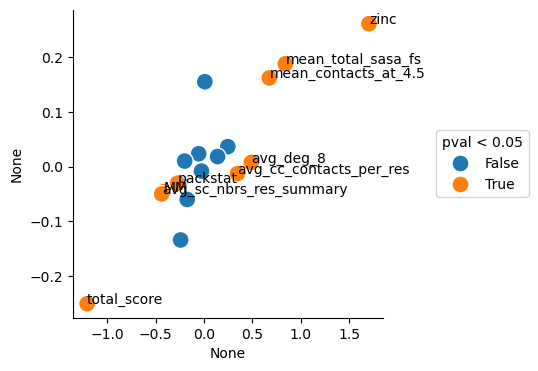

In [720]:
# do elasticnet and GLM have same param values?
fig, ax = plt.subplots(figsize=(4,4))
sns.scatterplot(x=coefs, y=coef_series, 
                hue=pvals < 0.05, s=150)
lgd = ax.legend(loc='center left', bbox_to_anchor=(1.15, 0.5), title='pval < 0.05')
for _x, _y, _ind in zip(coefs, coef_series.reindex(coefs.index), coefs.index):
    if pvals.loc[_ind] < 0.05:
        ax.annotate(_ind, xy=(_x, _y), xycoords='data')
    
sns.despine()

### Estimates of heteroscedasticity

In [546]:
from statsmodels.stats.diagnostic import het_breuschpagan

# Use OLS/GLM residuals and your design matrix
# Note: statsmodels requires the exogenous matrix to include the constant if it was used
bp_test = het_breuschpagan(model.resid_response, X_final.values)

labels = ['Lagrange Multiplier statistic', 'p-value', 'f-value', 'f p-value']
print(dict(zip(labels, bp_test)))

{'Lagrange Multiplier statistic': 605.3704249831354, 'p-value': 6.3020914626390264e-117, 'f-value': 36.26369394432336, 'f p-value': 8.748774441167794e-122}


In [547]:
model_default = sm.GLM(y_scaled, X_final.values, family=sm.families.Gaussian(), var_weights=weights).fit()
model_robust = sm.GLM(y_scaled, X_final.values, family=sm.families.Gaussian(), var_weights=weights).fit(cov_type='HC3')

print("Default SE:", model_default.bse.sort_values().head())
print("Robust SE: ", model_robust.bse.sort_values().head())

Default SE: x17    0.022359
x15    0.024349
x11    0.025100
x2     0.026976
x1     0.027016
dtype: float64
Robust SE:  x15    0.081577
x1     0.095164
x11    0.096771
x4     0.098782
x13    0.117293
dtype: float64


## One or two more model tests:
"Global" model: total score  plus other global terms  
"Micro" model: individual score terms

In [548]:
filtered.columns

Index(['mean_total_sasa_fs', 'mean_polar_sasa_fs', 'mean_apolar_sasa_fs',
       'mean_delta_sasa', 'mean_norm_delta_sasa', 'mean_contacts_at_4.5',
       'total_total_sasa_fs', 'total_polar_sasa_fs', 'total_apolar_sasa_fs',
       'total_delta_sasa', 'total_norm_delta_sasa', 'total_contacts_at_4.5',
       'MM', 'MS', 'SM', 'SS', 'total', 'bb-sc', 'lidded', 'zinc', 'hbond',
       'total_score', 'avg_deg_4_5', 'avg_deg_8', 'avg_sc_nbrs_res_summary',
       'bb_internal_hbonds', 'bbsc_internal_hbonds', 'calc_bsa_apolar',
       'calc_bsa_total', 'cav_vol', 'internal_hbonds', 'nonpolar_sasa',
       'packstat', 'polar_sasa', 'sasa', 'sc_internal_hbonds',
       'total_cc_contacts', 'length', 'avg_cc_contacts_per_res', 'temp',
       'aligned_structure_len'],
      dtype='object')

### Global model

In [566]:
# one more test: performance on signficant coefficients only
weights = compute_gaussian_weights(y_scaled)
# Xvals = X_final.loc[:, list(pvals[pvals < 0.05].index)].values, 
macro_features = [
    'total_score', 
    'length', 
    'mean_total_sasa_fs', 
    'packstat', 
    'cav_vol', 
    'mean_contacts_at_4.5', 
    'zinc',
    'hbond'
]
Xvals = sm.add_constant(X_scaled[macro_features])
model2 = sm.GLM(y_scaled, 
               # 
                Xvals,
               family=sm.families.Gaussian(), 
               var_weights=weights
              ).fit(cov_type='HC3')

model2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                      y   No. Observations:                 8098
Model:                            GLM   Df Residuals:                     8089
Model Family:                Gaussian   Df Model:                            8
Link Function:               Identity   Scale:                          34.964
Method:                          IRLS   Log-Likelihood:                -21570.
Date:                Wed, 20 May 2026   Deviance:                   2.8283e+05
Time:                        17:14:50   Pearson chi2:                 2.83e+05
No. Iterations:                     3   Pseudo R-squ. (CS):             0.7865
Covariance Type:                  HC3                                         
========================================================================================
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    0.1479      0.116      1.274      0.203      -0.080       0.375
total_score             -1.2768      0.152     -8.399      0.000      -1.575      -0.979
length                  -0.7952      0.214     -3.712      0.000      -1.215      -0.375
mean_total_sasa_fs       0.8620      0.097      8.894      0.000       0.672       1.052
packstat                -0.2956      0.146     -2.027      0.043      -0.581      -0.010
cav_vol                 -0.0213      0.102     -0.210      0.834      -0.221       0.178
mean_contacts_at_4.5     0.7772      0.106      7.298      0.000       0.568       0.986
zinc                     0.9316      0.136      6.850      0.000       0.665       1.198
hbond                    0.0323      0.142      0.228      0.820      -0.246       0.310
========================================================================================
"""

In [567]:
model2.aic

43158.47701382027

Condition number of X 4.228741164025586
Size of X (8098, 9)


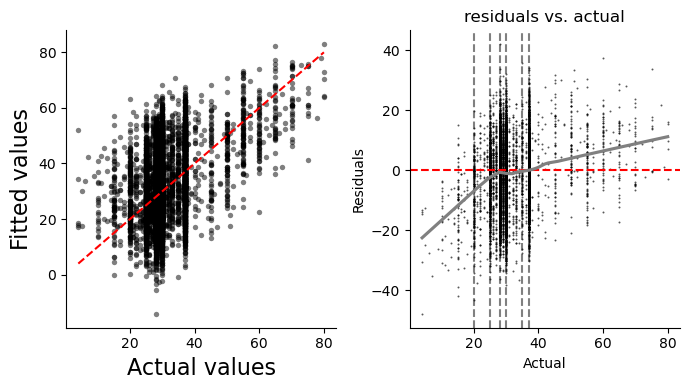

In [568]:
plot_model(model2, y['temp'], y_scaler, Xvals, scaler_input)

### Micro model

In [569]:
# one more test: performance on signficant coefficients only
weights = compute_gaussian_weights(y_scaled)
# Xvals = X_final.loc[:, list(pvals[pvals < 0.05].index)].values, 
micro_features = [
    'length', 'zinc', 'hbond',                    # Structural/Size Controls
    'bb_internal_hbonds', 'sc_internal_hbonds',    # Specific H-Bonding
    'bbsc_internal_hbonds',
    'mean_polar_sasa_fs', 'mean_apolar_sasa_fs',   # Specific Surface Environments
    'mean_delta_sasa',
    'avg_deg_4_5', 'avg_deg_8',                    # Local Packing/Coordination
    'avg_sc_nbrs_res_summary'
]
Xvals = X_scaled[micro_features]
model2 = sm.GLM(y_scaled, 
               # 
                Xvals,
               family=sm.families.Gaussian(), 
               var_weights=weights
              ).fit(cov_type='HC3')

model2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                      y   No. Observations:                 8098
Model:                            GLM   Df Residuals:                     8086
Model Family:                Gaussian   Df Model:                           11
Link Function:               Identity   Scale:                          42.421
Method:                          IRLS   Log-Likelihood:                -22351.
Date:                Wed, 20 May 2026   Deviance:                   3.4301e+05
Time:                        17:14:55   Pearson chi2:                 3.43e+05
No. Iterations:                     3   Pseudo R-squ. (CS):             0.6663
Covariance Type:                  HC3                                         
===========================================================================================
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
length                      0.6603      0.269      2.455      0.014       0.133       1.187
zinc                        0.7803      0.192      4.064      0.000       0.404       1.157
hbond                      -0.0169      0.148     -0.114      0.909      -0.308       0.274
bb_internal_hbonds         -0.5606      0.241     -2.330      0.020      -1.032      -0.089
sc_internal_hbonds          0.2411      0.147      1.642      0.100      -0.047       0.529
bbsc_internal_hbonds       -0.3560      0.135     -2.643      0.008      -0.620      -0.092
mean_polar_sasa_fs          0.7855      0.130      6.034      0.000       0.530       1.041
mean_apolar_sasa_fs         0.6748      0.145      4.670      0.000       0.392       0.958
mean_delta_sasa             1.1848      0.124      9.558      0.000       0.942       1.428
avg_deg_4_5                 0.1997      0.120      1.669      0.095      -0.035       0.434
avg_deg_8                   0.7611      0.143      5.330      0.000       0.481       1.041
avg_sc_nbrs_res_summary    -0.6533      0.162     -4.025      0.000      -0.971      -0.335
===========================================================================================
"""

In [570]:
model2.aic

44726.87367022182

Condition number of X 5.8429733118525276
Size of X (8098, 12)


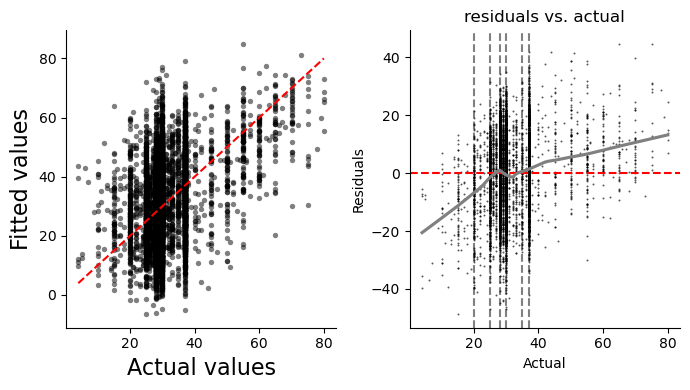

In [571]:
plot_model(model2, y['temp'], y_scaler, Xvals, scaler_input)

In [573]:
model_coefficients = pd.Series(data=model.params.values,
                               index=X_final.columns)
print(model_coefficients.shape)

model_intervals = model.conf_int().rename(columns={0:'lower', 1:'upper'})
model_intervals['not_zero'] = model_intervals.apply(lambda row: not (row['lower'] <= 0 <= row['upper']), axis=1)
model_intervals.index=model_coefficients.index

print(model_intervals.shape)

(19,)
(19, 3)


# Make actual plots for manuscript

In [751]:
# descriptions
feature_map = {
    "sc_internal_hbonds": {
    "full_name": "Side-side internal h-bonds",
    "category": "Hydrogen bonding"
    },
    "SS": {
    "full_name": "Side-side h-bonds",
    "category": "Hydrogen bonding"
    },
    "MS": {
    "full_name": "Main-side h-bonds",
    "category": "Hydrogen bonding"
    },
    "MM": {
    "full_name": "Main-main h-bonds",
    "category": "Hydrogen bonding"
    },
    "SM": {
    "full_name": "Side-main h-bonds",
    "category": "Hydrogen bonding"
    },
    "total": {
    "full_name": "Total h-bonds",
    "category": "Hydrogen bonding"
    },
    "zinc": {
    "full_name": "Lid type: zinc",
    "category": "Protein properties"
    },
    "hbond": {
    "full_name": "Lid type: h-bond",
    "category": "Protein properties"
    },
    "avg_cc_contacts": {
        "full_name": "Average C-C contacts",
        "category": "Contact density"
    },
    "avg_cc_contacts_per_res": {
        "full_name": "Average C-C contacts",
        "category": "Contact density"
    },
    "mean_contacts_at_4.5": {
        "full_name": "Contacts at 4.5 Å",
        "category": "Contact density"
    },
    "total_score": {
        "full_name": "Rosetta total reference energy",
        "category": "Reference energies"
    },
    # "SASA": {
    #     "full_name": "Solvent Accessible Surface Area",
    #     "category": "Surface/solvation"
    # },
    "mean_total_sasa_fs": {
    "full_name": "Total SASA",
    "category": "Surface/solvation"
    },
    "mean_apolar_sasa_fs": {
    "full_name": "Nonpolar SASA",
    "category": "Surface/solvation"
    },
    "mean_polar_sasa_fs": {
    "full_name": "Polar SASA",
    "category": "Surface/solvation"
    },
    "mean_delta_sasa": {
    "full_name": "$\Delta$ SASA",
    "category": "Surface/solvation"
    },
    "avg_deg_4_5": {
        "full_name": "Residue degree (4.5 Å)",
        "category": "Contact density"
    },
    "avg_deg_8": {
        "full_name": "Residue degree (8 Å)",
        "category": "Contact density"
    },
    "avg_sc_nbrs_res_summary": {
        "full_name": "Average S neighbors",
        "category": "Packing"
    },
    "bb_internal_hbonds": {
        "full_name": "BB-BB internal h-bonds",
        "category": "Hydrogen bonding"
    },
    "bbsc_internal_hbonds": {
        "full_name": "BB–S internal h-bonds",
        "category": "Hydrogen bonding"
    },
    "cav_vol": {
        "full_name": "Internal cavity volume",
        "category": "Packing/voids"
    },
    # "dslf_fa13": {
    #     "full_name": "Disulfide bond energy",
    #     "category": "Covalent bonding"
    # },
    # "fa_atr": {
    #     "full_name": "Lennard-Jones attractive term",
    #     "category": "Van der Waals"
    # },
    # "fa_dun": {
    #     "full_name": "Dunbrack rotamer probability energy",
    #     "category": "Side-chain conformations"
    # },
    # "fa_elec": {
    #     "full_name": "Electrostatic interaction energy",
    #     "category": "Electrostatics"
    # },
    # "fa_intra_sol_xover4": {
    #     "full_name": "Intra-residue solvation (distance >4 Å)",
    #     "category": "Solvation"
    # },
    # "fa_sol": {
    #     "full_name": "Lazaridis–Karplus solvation energy",
    #     "category": "Solvation"
    # },
    # "fa_intra_rep": {
    #     "full_name": "L-J intra-residue repulsive force",
    #     "category": "Van der Waals"
    # },
    # "fa_rep": {
    #     "full_name": "L-J repulsive force",
    #     "category": "Van der Waals"
    # },
    "hbond_bb_sc": {
        "full_name": "BB–side chain hydrogen bonds",
        "category": "Hydrogen bonding"
    },
    "hbond_lr_bb": {
        "full_name": "Long-range BB-BB hydrogen bonds",
        "category": "Hydrogen bonding"
    },
    "hbond_sc": {
        "full_name": "Side-chain–side-chain hydrogen bonds",
        "category": "Hydrogen bonding"
    },
    "hbond_sr_bb": {
        "full_name": "Short-range backbone–backbone hydrogen bonds",
        "category": "Hydrogen bonding"
    },
    "internal_hbonds": {
        "full_name": "All internal h-bonds",
        "category": "Hydrogen bonding"
    },
    "lk_ball_wtd": {
        "full_name": "Orientation-dependent solvation (Lazaridis–Karplus, weighted)",
        "category": "Solvation"
    },
    "omega": {
        "full_name": "Peptide bond ω torsion energy",
        "category": "Backbone geometry"
    },
    "p_aa_pp": {
        "full_name": "Amino acid–phi/psi backbone propensity energy",
        "category": "Backbone conformational preferences"
    },
    "packstat": {
        "full_name": "Packing statistic",
        "category": "Packing"
    },
    "pro_close": {
        "full_name": "Proline ring closure energy",
        "category": "Side-chain conformations"
    },
    "rama_prepro": {
        "full_name": "Ramachandran energy (pre-proline residues)",
        "category": "Backbone conformational preferences"
    },
    "ref": {
        "full_name": "Reference energy term (amino acid-specific baseline)",
        "category": "Reference energies"
    },
    "total_cc_contacts": {
        "full_name": "Total carbon–carbon contacts",
        "category": "Contact density"
    },
    # "yhh_planarity": {
    #     "full_name": "Tyrosine–histidine–histidine planarity energy",
    #     "category": "Special geometry terms"
    # },
    "length": {
        "full_name": "Protein length (residues)",
        "category": "Length"
    }
}


Condition number of X 7.992147848111592
Size of X (8098, 19)


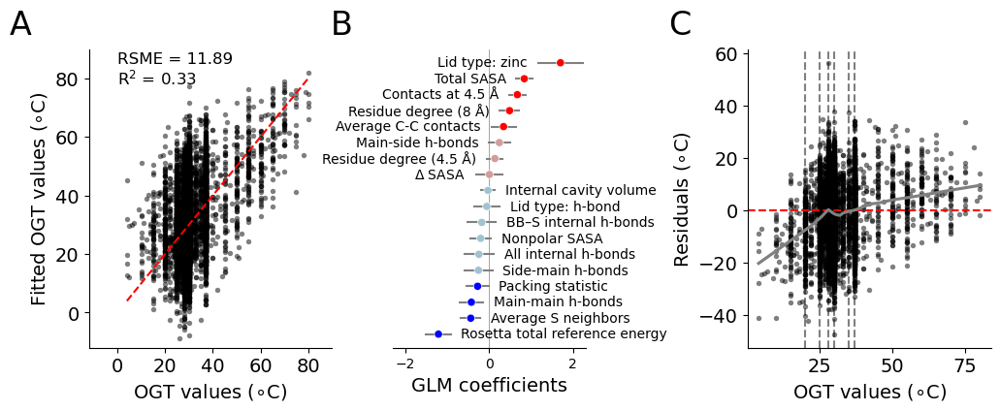

In [773]:
fig = plt.figure(figsize=(12, 4))
gs = fig.add_gridspec(1, 18)

# axis 1 ----
# ------------------------------------------------------------
ax = fig.add_subplot(gs[0, :5])
ax.annotate('A', (-0.325, 1.05), fontsize=24, annotation_clip=False, xycoords='axes fraction')

y = filtered['temp']
y_pred = pd.Series(data=model.get_prediction(X_final).predicted_mean, index=y_scaled.index)
y_pred = y_pred.map(lambda y_unsc: y_scaler.inverse_transform([[y_unsc]])[0][0])
residuals = y - y_pred
print("Condition number of X", np.linalg.cond(X_final))
print("Size of X", X_final.shape)

rmse = np.sqrt(mean_squared_error(y, y_pred))
r2 = spearmanr(y, y_pred)[0]

ax.annotate('$\mathrm{R^2}$ = '+f'{r2:.2f}', (0, 78),
           fontsize=12)
ax.annotate('RSME = '+f'{rmse:.2f}', (0, 85),
           fontsize=12)

ax.set_ylabel('Fitted OGT values ($\circ$C)', fontsize=14)
ax.set_xlabel('OGT values ($\circ$C)', fontsize=14)


# plot of regression vals
sns.scatterplot(x=y, y=y_pred, ax=ax, linewidth=0, alpha=0.5, s=15, color='k')

# guiding x = y line
ax.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', label='y = x')
ax.set_ylim(-12, 90)
ax.set_xlim(-12, 90)
ax.set_xticks(range(0, 100, 20))
plt.tick_params(labelsize=14)
sns.despine()

# axis 2 ----
# ------------------------------------------------------------

ax = fig.add_subplot(gs[0, 6:10])
ax.annotate('B', (-0.325, 1.05), fontsize=24, annotation_clip=False, xycoords='axes fraction')

plotdf = pd.DataFrame(model_coefficients.copy().drop('const'))

plotdf["category"] = plotdf.index.map(
    lambda f: feature_map[f.replace('_per_res', '')]['category']
)
plotdf = plotdf.sort_values(0)

hues=model_intervals['not_zero'].loc[plotdf.index]

sns.scatterplot(x=plotdf.mask(plotdf[0] > 0)[0], 
                y=pd.Series(index=plotdf.index,
                            data=range(len(plotdf))),
                hue=hues, 
                palette=[sns.desaturate('skyblue', 0.5), 'blue'],
                legend=False,
                zorder=2)

sns.scatterplot(x=plotdf.mask(plotdf[0] < 0)[0], 
                y=pd.Series(index=plotdf.index,
                            data=range(len(plotdf))),
                hue=hues, 
                palette=[sns.desaturate('lightcoral', 0.5), 'red'],
                legend=False,
                zorder=2)

n = len(model_coefficients)
y = model_intervals.reindex(plotdf.index).iloc[:, :2].values
x2 = [[i]*2 for i in range(n)]
for _x, _y in zip(y, x2):
    plt.plot(_x, _y, zorder=1, color='gray')
    if _x[0] < -15 or _x[0] > 15:
        ax.annotate(xy=(-10, _y[0]), text='*')

# ax.set_xticks([-10, 0, 10])
ax.set_xlim(-2.3, 2.3)

ax.axvline(0, color='gray', zorder=0, linewidth=0.5)


ax.set_ylabel('')
ax.set_xlabel('GLM coefficients', fontsize=14)

# # # Clear default ticks
ax.set_yticks(list(range(len(plotdf.index))))
ylabels = ax.set_yticklabels(['' for i in plotdf.index], rotation=0)
plt.tick_params(left=False)

for i in list(range(len(plotdf.index))):
    
    
    
    if plotdf.iloc[i, 0] > 0:
        xcoord = model_intervals.loc[plotdf.index[i], 'lower'] - 0.25
        ha = 'right'
    else:
        xcoord = model_intervals.loc[plotdf.index[i], 'upper'] + 0.25
        ha='left'
    
    ax.annotate(feature_map[plotdf.index[i]]['full_name'], 
                (xcoord, i),
                va='center', ha=ha)

sns.despine(left=True, ax=ax)
# ax.spines['left'].set_visible(False)
# axis 3 ----
# ------------------------------------------------------------
    
# 2. Residuals vs Fitted
ax = fig.add_subplot(gs[0, 13:])
ax.annotate('C', (-0.325, 1.05), fontsize=24, annotation_clip=False, xycoords='axes fraction')
y = filtered['temp']
sns.scatterplot(x=y, y=residuals, ax=ax, linewidth=0, alpha=0.5, s=15, color='k')
for vline in list(range(20, 40, 5)) + [28, 37]:
    ax.axvline(vline, zorder=0, linestyle='--', color='gray')
ax.axhline(0, color='red', linestyle='--')
sns.regplot(x=y, y=residuals, lowess=True, scatter=False, ax=ax, color='gray')
# ax.set_title('residuals vs. actual')
ax.set_xlabel('OGT values ($\circ$C)', fontsize=14)
ax.set_ylabel('Residuals ($\circ$C)', fontsize=14)
plt.tick_params(labelsize=14)
sns.despine(ax=ax)
# ax.spines['right'].set_visible(False)

# plt.tight_layout()
# plt.savefig(save, **kwargs)
fig.subplots_adjust(wspace=0.25)
plt.savefig('./../data/figures/structural_model_summary.svg', bbox_inches='tight')
plt.savefig('./../data/figures/structural_model_summary.png', bbox_inches='tight', dpi=400)

In [748]:
plotdf

,0,category
total_score,-1.210141,Reference energies
avg_sc_nbrs_res_summary,-0.438869,Packing
MM,-0.423662,Hydrogen bonding
packstat,-0.274473,Packing
SM,-0.254214,Hydrogen bonding
internal_hbonds,-0.242956,Hydrogen bonding
mean_apolar_sasa_fs,-0.201110,Surface/solvation
bbsc_internal_hbonds,-0.174929,Hydrogen bonding
hbond,-0.056283,Protein properties
cav_vol,-0.027034,Packing/voids


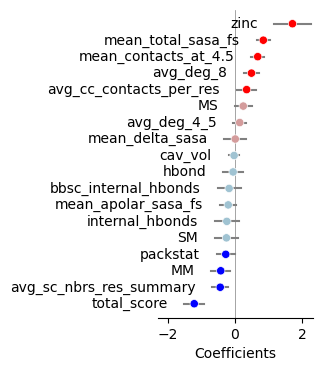

In [643]:
fig, ax = plt.subplots(figsize=(2, 4))

plotdf = pd.DataFrame(model_coefficients.copy().drop('const'))

plotdf["category"] = plotdf.index.map(
    lambda f: feature_map[f.replace('_per_res', '')]['category']
)
plotdf = plotdf.sort_values(0)

hues=model_intervals['not_zero'].loc[plotdf.index]

sns.scatterplot(x=plotdf.mask(plotdf[0] > 0)[0], 
                y=pd.Series(index=plotdf.index,
                            data=range(len(plotdf))),
                hue=hues, 
                palette=[sns.desaturate('skyblue', 0.5), 'blue'],
                legend=False,
               zorder=2)

sns.scatterplot(x=plotdf.mask(plotdf[0] < 0)[0], 
                y=pd.Series(index=plotdf.index,
                            data=range(len(plotdf))),
               hue=hues, 
                palette=[sns.desaturate('lightcoral', 0.5), 'red'],
                legend=False,
               zorder=2)

n = len(model_coefficients)
y = model_intervals.reindex(plotdf.index).iloc[:, :2].values
x2 = [[i]*2 for i in range(n)]
for _x, _y in zip(y, x2):
    plt.plot(_x, _y, zorder=1, color='gray')
    if _x[0] < -15 or _x[0] > 15:
        ax.annotate(xy=(-10, _y[0]), text='*')

# ax.set_xticks([-10, 0, 10])
ax.set_xlim(-2.3, 2.3)

ax.axvline(0, color='gray', zorder=0, linewidth=0.5)

sns.despine(left=True)
ax.set_ylabel('')
ax.set_xlabel('Coefficients')

# # Clear default ticks
ax.set_yticks(list(range(len(plotdf.index))))
ylabels = ax.set_yticklabels(['' for i in plotdf.index], rotation=0)
plt.tick_params(left=False)

for i in list(range(len(plotdf.index))):
    ax.annotate(plotdf.index[i], 
                (model_intervals.loc[plotdf.index[i], 'lower']-0.5, i),
                va='center', ha='right')

# ## Plot category labels
# # Collapse plotting by category groups
# categories = plotdf["category"]
# x_positions = range(len(plotdf))

# # Find start and end indices for each category
# group_ranges = defaultdict(list)
# for i, cat in enumerate(categories):
#     group_ranges[cat].append(i)

# # Add category labels + brackets
# for cat, idxs in group_ranges.items():
#     start, end = min(idxs), max(idxs)
#     mid = (start + end) / 2

#     # Place category label at midpoint
#     ax.text(
#          1.15, mid, cat, va="center", ha="left",
#         transform=ax.get_yaxis_transform(), fontsize=14
#     )

#     # Draw a bracket line spanning the group
#     ax.plot(
#           [1.1, 1.1], [start, end], transform=ax.get_yaxis_transform(),
#         color="black", linewidth=1, clip_on=False
#     )

# # Legend
# ax.get_legend().remove()
# handles, labels = ax.get_legend_handles_labels()
# lgd = ax.legend(handles, labels, title='coef != 0', loc='upper left', bbox_to_anchor=(1, 0.5))

# # plt.savefig('./../data/figures/20251009_coefficients.png', dpi=400, bbox_inches='tight')

In [638]:
model_intervals

,lower,upper,not_zero
const,-0.668204,-0.060454,True
mean_total_sasa_fs,0.653844,1.026881,True
mean_apolar_sasa_fs,-0.438428,0.036208,False
mean_delta_sasa,-0.313777,0.328950,False
mean_contacts_at_4.5,0.480764,0.867980,True
MM,-0.707505,-0.139819,True
MS,-0.002703,0.492691,False
SM,-0.588188,0.079759,False
zinc,1.168914,2.241030,True
hbond,-0.359688,0.247122,False


AttributeError: 'numpy.ndarray' object has no attribute 'index'

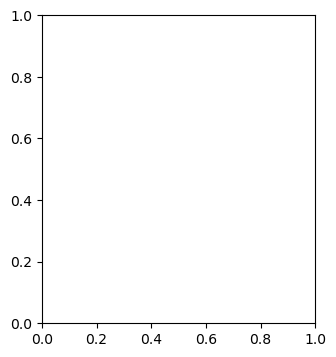

In [370]:
# coefficient_df = pd.Series(index=pd.MultiIndex.from_tuples([(i.split(' ')[0], i.split(' ')[1]) for i in model_coefficients.iloc[42:].index]),
#              data=model_coefficients.iloc[42:].values).unstack()

# fig, ax = plt.subplots(figsize=(12, 12))
# sns.heatmap(coefficient_df.reindex(index=model_coefficients.iloc[1:42].index, 
#                                    columns=model_coefficients.iloc[1:42].index).T, 
#             cmap='bwr', center=0)

# plt.savefig('./../data/figures/20250630_coefficient_heatmap.png', dpi=400, bbox_inches='tight')

## Perturbation

In [821]:
baseline_score = spearmanr(y['temp'], y_pred)[0]

rep_importances = []
for rep in range(5):
    importances = {}
    for i, col in enumerate(X_final.columns):
        display(i)
        clear_output(wait=True)
        X_perm = X_final.copy()
        X_perm[col] = np.random.permutation(X_perm[col].values)
        y_pred_perm = model.get_prediction(X_perm).predicted_mean
        perm_score = spearmanr(y['temp'], y_pred_perm)[0]
        importances[col] = baseline_score - perm_score
    
    importances_df = pd.DataFrame.from_dict(importances, orient='index', columns=[f'importance_{rep}'])
    rep_importances.append(importances_df)

33

<Axes: xlabel='None', ylabel='None'>

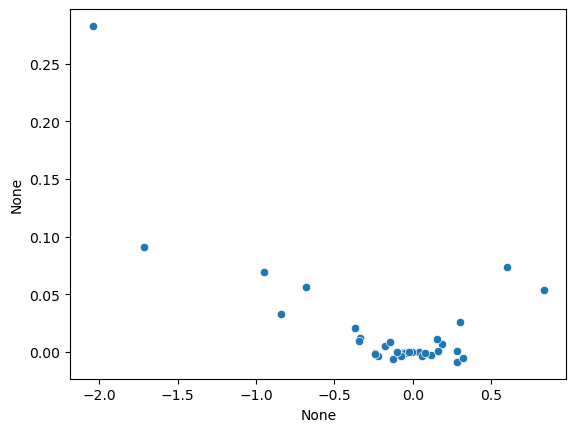

In [822]:
sns.scatterplot(y=pd.concat(rep_importances, axis=1).mean(1), x=model_coefficients)

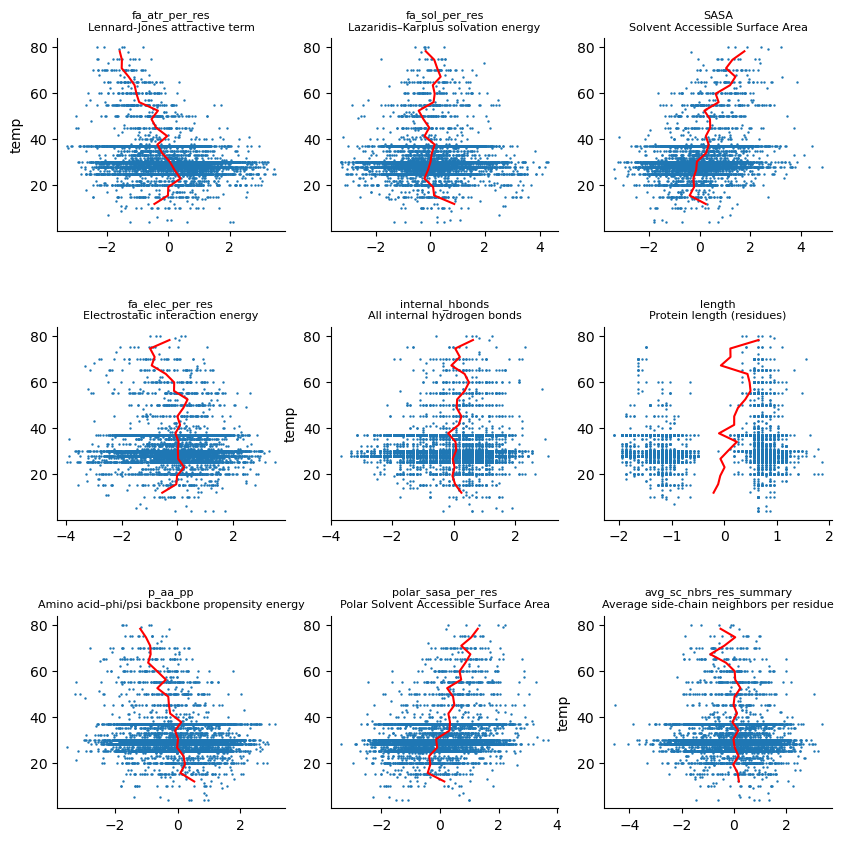

In [836]:
fig = plt.figure(figsize=(10, 10))
i = 1
for col in pd.concat(rep_importances, axis=1).mean(1).sort_values(ascending=False).index[:9]:
    
    ax = fig.add_subplot(3, 3, i)
    
    sns.scatterplot(x=X_final[col], 
                    y=y['temp'], 
                    #hue=clusters,
                    linewidth=0, ax=ax, s=3, palette='tab10')
    
    means = (X_final[col]).groupby(pd.cut(y['temp'], np.linspace(10, 80, 20))).mean().reset_index()
    means['temp'] = means['temp'].apply(lambda x: float(x.mid))
    plt.plot(means[col], means['temp'], c='red')
    
    # xlims = np.array(ax.get_xlim())
    # ax.set_yticks(range(10,90,20))
    # ax.set_xlim(xlims * 0.25)
    ax.set_xlabel('')
    ax.set_title(f'{col}\n{feature_map[col.replace("_per_res", "")]["full_name"]}', fontsize=8)
    
    if i % 4 != 1:
        ax.set_ylabel('')
    sns.despine()
    #ax.get_legend().remove()
    i += 1
fig.subplots_adjust(hspace=0.5)

# plt.savefig('./../data/figures/20251009_model_key_features.png', dpi=400, bbox_inches='tight')

# Mean only model

In [13]:
# setup
def gridplot(plotdf, x, y, gridval, ax, ncols, nrows):

    fig = plt.figure(figsize=(ncols*2, nrows*2))
    print(len(plotdf[gridval].unique()))
    assert len(plotdf[gridval].unique()) <= ncols * nrows
    axes = []
    for i, val in enumerate(plotdf[gridval].unique()):
        ax = fig.add_subplot( nrows, ncols, i+1)
        sns.scatterplot(data=plotdf[plotdf[gridval].eq(val)],
                       x=x, y=y, linewidth=0, alpha=0.65)

        sns.despine()
        mic = mutual_info_regression(plotdf[plotdf[gridval].eq(val)][[x]], plotdf[plotdf[gridval].eq(val)][y])[0]
        ax.set_title(f'{val}\n{mic:.2f}')
        ax.set_xlabel('')
        if i % ncols != 0:
            ax.set_ylabel('')

        axes.append(ax)
    return fig, ax
        
    
            

sasa_cols = [c for c in filtered.columns if 'sasa' in c]
drop_cols = [
    # 'uid',
             'Position',
 'temp',
 # 'mean_temp',
 # 'temp_group',
 'Unnamed: 0',
 'lid_bitscore',
 'total_score',
 'seq_length',
 'max_structure_length',
 # 'group',
'bitscore', 'fa_atr']

In [17]:
filtered['temp_group'] = pd.cut(filtered['mean_temp'], np.linspace(0, 100, 51))
mean_df = filtered.drop(drop_cols + sasa_cols + ['uid'], axis=1).groupby('temp_group').mean().dropna()
mean_df.index = [i.mid for i in mean_df.index]

<Axes: xlabel='length', ylabel='Count'>

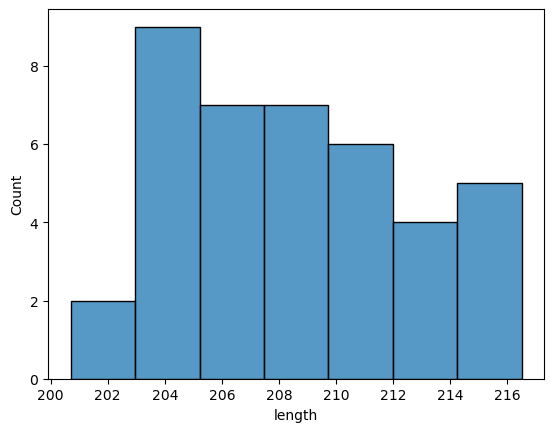

In [19]:
sns.histplot(mean_df['length'])

40


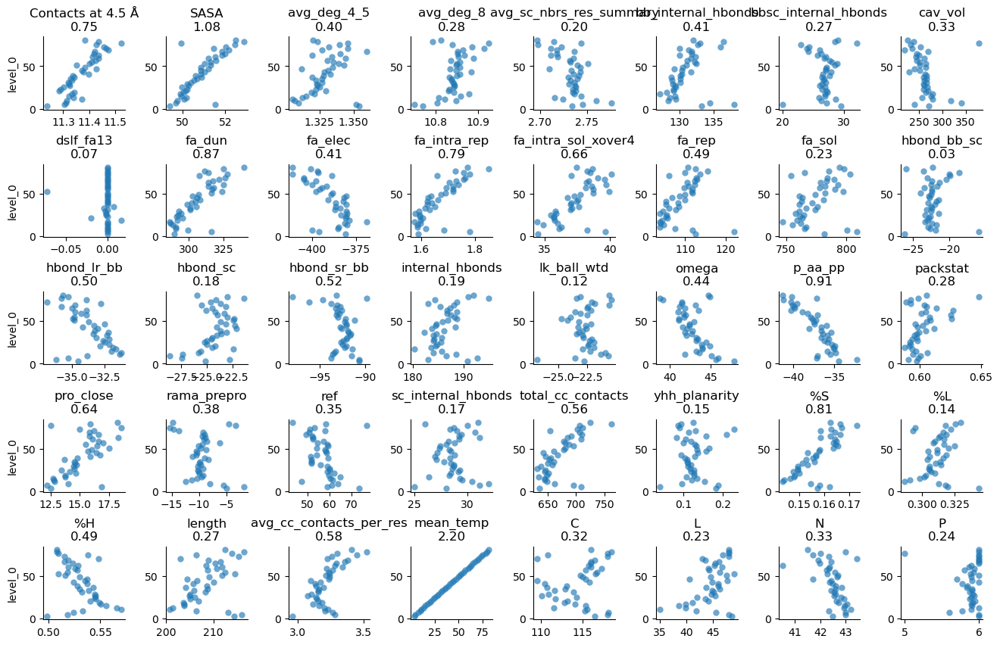

In [253]:
fig, axes = gridplot(plotdf=mean_df.stack().reset_index(), 
         # x='mean_temp',
        y='level_0',
         x=0, gridval='level_1', ax=ax, 
         ncols=8, nrows=5)

fig.subplots_adjust(wspace=0.5, hspace=0.75)

In [254]:
y = mean_df.index.values
x_scaler = StandardScaler()
x = mean_df.values
x = x_scaler.fit_transform(x)
x = sm.add_constant(x)
x.shape

# weights = compute_gaussian_weights(y)

model = sm.OLS(y, x)
result = model.fit()
# y_pred = pd.Series(model.get_prediction(X_poly).predicted_mean)

result.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 9.790e+04
Date:                Mon, 29 Sep 2025   Prob (F-statistic):           1.02e-05
Time:                        22:24:51   Log-Likelihood:                 105.86
No. Observations:                  40   AIC:                            -135.7
Df Residuals:                       2   BIC:                            -71.54
Df Model:                          37                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         42.0000      0.012   3462.375      0.000      41.948      42.052
x1             0.5939      0.353      1.684      0.234      -0.924       2.111
x2            -5.0701      2.071     -2.448      0.134     -13.980       3.840
x3            -0.6331      0.279     -2.268      0.151      -1.834       0.568
x4            -1.7235      0.596     -2.891      0.102      -4.289       0.842
x5            -0.5379      0.258     -2.084      0.173      -1.648       0.573
x6            -0.5650      0.280     -2.021      0.181      -1.768       0.638
x7            -0.2594      0.180     -1.438      0.287      -1.036       0.517
x8            -1.6595      0.725     -2.290      0.149      -4.778       1.459
x9            -0.2617      0.089     -2.954      0.098      -0.643       0.120
x10           -2.2126      0.827     -2.676      0.116      -5.770       1.345
x11           -1.5359      0.385     -3.988      0.058      -3.193       0.121
x12            6.0062      2.415      2.487      0.131      -4.383      16.395
x13           -0.3315      0.219     -1.516      0.269      -1.272       0.609
x14           -0.9828      0.519     -1.894      0.199      -3.216       1.250
x15           -3.8538      1.809     -2.130      0.167     -11.638       3.931
x16           -0.4182      0.098     -4.257      0.051      -0.841       0.005
x17           -4.0558      1.380     -2.940      0.099      -9.991       1.880
x18            0.8703      0.198      4.398      0.048       0.019       1.722
x19           -0.2580      0.200     -1.289      0.326      -1.120       0.604
x20           -0.1872      0.082     -2.294      0.149      -0.538       0.164
x21           -1.3758      0.309     -4.456      0.047      -2.704      -0.047
x22           -0.7352      0.193     -3.803      0.063      -1.567       0.097
x23           -0.1690      0.153     -1.106      0.384      -0.826       0.488
x24            0.3096      0.145      2.143      0.165      -0.312       0.931
x25            0.4287      0.157      2.727      0.112      -0.248       1.105
x26            0.1304      0.216      0.604      0.607      -0.798       1.059
x27           -1.4007      0.575     -2.437      0.135      -3.874       1.073
x28            0.8696      0.261      3.329      0.080      -0.254       1.993
x29          -11.6162      4.956     -2.344      0.144     -32.942       9.709
x30           -0.2326      0.064     -3.620      0.069      -0.509       0.044
x31           -0.5079      0.345     -1.473      0.279      -1.992       0.976
x32            0.0794      0.107      0.740      0.536      -0.382       0.541
x33            0.1759      0.204      0.863      0.479      -0.702       1.053
x34            2.2703      1.377      1.649      0.241      -3.653       8.193
x35            6.6009      3.076      2.146      0.165      -6.633      19.835
x3

In [255]:
# sm.graphics.plot_fit(result, 'x3')

# Improved mean-only model

In [27]:
# Paste into your Python session
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNetCV
from sklearn.pipeline import make_pipeline
import statsmodels.api as sm
from sklearn.feature_selection import mutual_info_regression
from scipy.spatial.distance import squareform
import itertools

In [28]:
def forward_transform(y, a, b):
    eps = 1e-6  # to avoid division by zero
    y = np.clip(y, a + eps, b - eps)
    return np.log((y - a) / (b - y))

def inverse_transform(y_prime, a, b):
    return a + (b - a) / (1 + np.exp(-y_prime))

In [190]:
sasa_cols = [c for c in filtered.columns if 'sasa' in c]
drop_cols = [
    # 'uid',
             'Position',
 'temp',
 'mean_temp',
 # 'temp_group',
 'Unnamed: 0',
 'lid_bitscore',
 'total_score',
 'seq_length',
 'max_structure_length',
 # 'group',
'bitscore', 'fa_atr']


filtered['temp_group'] = pd.cut(filtered['mean_temp'], np.linspace(0, 100, 301))
mean_df = filtered.drop(drop_cols + sasa_cols + ['uid'], axis=1).groupby(['temp_group']).mean().dropna()
# mean_df['length'] = mean_df.index.get_level_values(0)
mean_df.index = [i.mid for i in mean_df.index]

In [ ]:
# mean_df = pd.merge(embedding_df['cluster'], filtered.set_index('uid').drop(drop_cols + sasa_cols, axis=1), left_index=True, right_index=True)
# mean_df = mean_df.groupby(['cluster', 'temp_group']).mean().dropna()
# mean_df['cluster'] = mean_df.index.get_level_values(0)

In [193]:
# a, b = np.min(mean_df.index.values)-5, np.max(mean_df.index.values)+5
# a, b = -10, 100
# print(a, b)
Xc = mean_df #.drop('cluster', axis=1) #.reset_index(drop=True).drop(['temp_group', 'mean_temp'], axis=1)
y = mean_df.index #np.array([i.mid for i in mean_df.index.get_level_values(1)])
print(y.shape)

(194,)


In [194]:

# --- INPUT ---
# X: pandas.DataFrame, shape (N, P) - N obs, P predictors
# y: pandas.Series or 1d array, shape (N,)

# --- 1) center predictors (retain original names) ---
# Xc = mean_df.copy().astype(float)
# Xc = Xc - Xc.mean(axis=0)  # centering; optionally scale if you like
# optionally scale: s
scaler = StandardScaler().fit(Xc)
Xc = pd.DataFrame(scaler.transform(Xc), index=Xc.index, columns=Xc.columns)

In [195]:
# Xc = Xc.drop('cluster', axis=1)

In [196]:
# for col1, _cluster in itertools.product(Xc.columns, pd.get_dummies(mean_df['cluster']).astype(int).columns):
#     Xc[f'{col1}_cluster{_cluster}'] = Xc[col1] * pd.get_dummies(mean_df['cluster']).astype(int).loc[:, _cluster]

<Figure size 800x600 with 0 Axes>

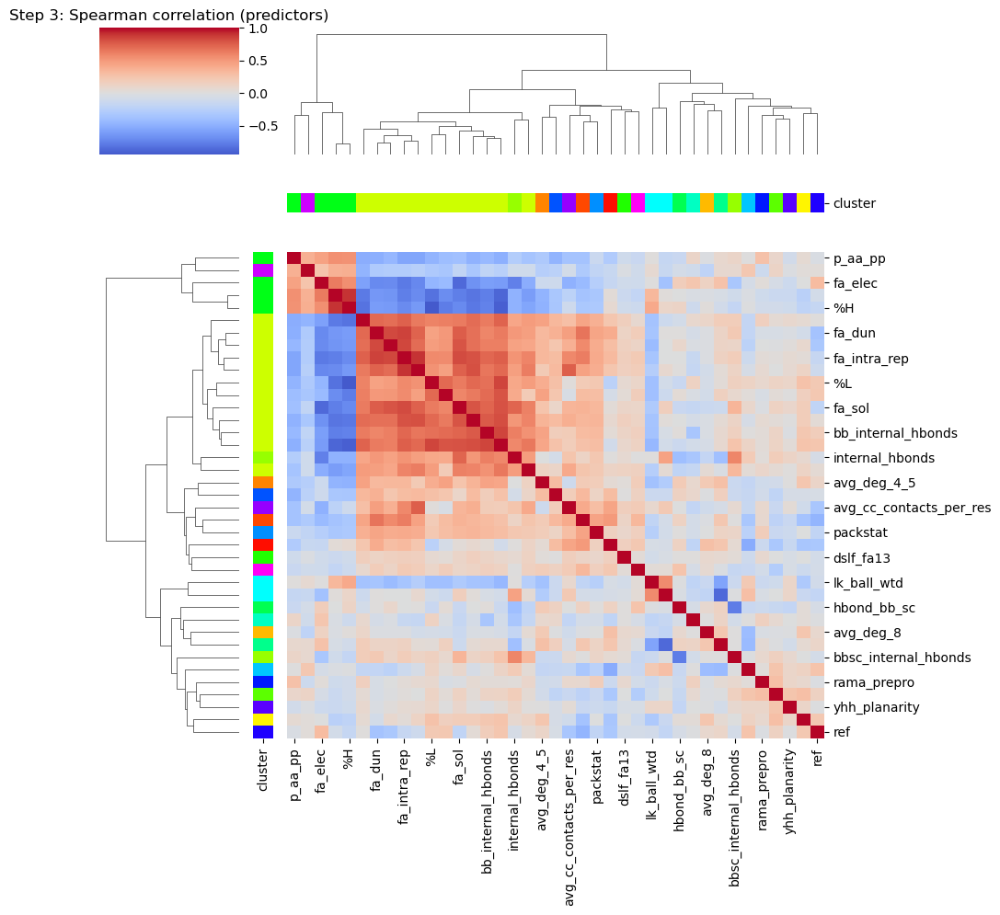

In [197]:
# tweak these thresholds as needed:
SPEARMAN_CLUSTER_THRESH = 0.5   # treat variables with |rho|>=this as rank-preserving
CLUSTER_DISTANCE = 1.0 - SPEARMAN_CLUSTER_THRESH  # used below

# --- 3) detect rank-preserving correlated predictors (Spearman) ---
# Compute Spearman correlation matrix (only for originals, not squared)
rho, pval = spearmanr(Xc, axis=0)
# spearmanr returns combined correlation matrix if input is 2d; when passed a DataFrame returns (ncols x ncols)
if isinstance(rho, np.ndarray) and rho.shape[0] == Xc.shape[1]:
    spearman_mat = pd.DataFrame(rho, index=Xc.columns, columns=Xc.columns)
else:
    raise RuntimeError("Unexpected spearmanr output format")

# Convert to distance for clustering: distance = 1 - |rho|
dist_mat = 1.0 - spearman_mat
title = "Step 3: Spearman correlation (predictors)"

# # pairwise mutual information
# mi_mat = pd.DataFrame(np.zeros((Xc.shape[1], Xc.shape[1])),
#                       index=Xc.columns, columns=Xc.columns)

# for i, col1 in enumerate(Xc.columns):
#     for j, col2 in enumerate(Xc.columns[i:], start=i):
#         mi = mutual_info_regression(Xc[[col1]], Xc[col2])[0]
#         mi_mat.iloc[i,j] = mi_mat.iloc[j,i] = mi

# # normalize MI to [0,1] by dividing by max (optional)
# mi_mat /= mi_mat.values.max()

# # distance = 1 - normalized MI
# dist_mat = 1.0 - mi_mat

# title = "Step 3: MIC correlation (predictors)"

# Condense for linkage: use squareform, but linkage accepts condensed vector; we'll extract upper triangle:
condensed = squareform(dist_mat.values, checks=False)
Z = linkage(condensed, method="average")

# cutoff on distance: choose clusters where 1 - |rho| <= CLUSTER_DISTANCE  => |rho| >= threshold
# So cluster cutoff distance = 1 - SPEARMAN_CLUSTER_THRESH
cluster_labels = fcluster(Z, t=CLUSTER_DISTANCE, criterion='distance')
cluster_df = pd.DataFrame({"var": Xc.columns, "cluster": cluster_labels})
cluster_cmap = dict((cluster, c) for c, cluster in zip(sns.color_palette('gist_rainbow', n_colors=len(cluster_df['cluster'].unique())), cluster_df['cluster'].unique()))

# --- STEP 3: Spearman correlation heatmap ---
plt.figure(figsize=(8,6))
sns.clustermap(spearman_mat, cmap="coolwarm", center=0, col_colors=cluster_df.set_index('var')['cluster'].map(cluster_cmap),
              row_colors=cluster_df.set_index('var')['cluster'].map(cluster_cmap))
plt.title(title)
plt.tight_layout()
plt.show()

In [198]:
# --- 4) choose representative variable within each cluster ---
# choose by strongest absolute Spearman correlation with target y
# compute spearman with y for original variables
spearmanr_with_y = {}
for col in Xc.columns:
    rho_col, _ = spearmanr(Xc[col], y)
    spearmanr_with_y[col] = abs(rho_col)

cluster_reps = []
for cl, grp in cluster_df.groupby('cluster'):
    vars_in_cluster = list(grp['var'])
    # pick var with largest |spearman with y|
    best = max(vars_in_cluster, key=lambda v: spearmanr_with_y[v])
    cluster_reps.append(best)

# cluster_reps now contains predictors to keep (one per rank-preserving cluster)
print("Clusters:", cluster_df.groupby('cluster').size().to_dict())
print("Selected representatives (keep):", cluster_reps, f'{len(cluster_reps)} clusters total')


Clusters: {1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 2, 7: 12, 8: 1, 9: 1, 10: 1, 11: 1, 12: 1, 13: 1, 14: 1, 15: 1, 16: 1, 17: 1, 18: 1, 19: 1, 20: 1, 21: 2, 22: 4, 23: 1}
Selected representatives (keep): ['avg_deg_4_5', 'pro_close', 'Contacts at 4.5 Å', 'SASA', 'avg_cc_contacts_per_res', 'internal_hbonds', 'fa_dun', 'packstat', 'dslf_fa13', 'hbond_bb_sc', 'P', 'avg_deg_8', 'hbond_sc', 'hbond_sr_bb', 'rama_prepro', 'avg_sc_nbrs_res_summary', 'cav_vol', 'omega', 'ref', 'yhh_planarity', 'lk_ball_wtd', 'p_aa_pp', 'N'] 23 clusters total


In [208]:
# --- 5) construct final design matrix: keep representative linear and their squared terms ---
keep_linear = cluster_reps
keep_cols = []
for col in keep_linear:
    keep_cols.append(col)
    # keep_cols.append(f"{col}__g{hinge}")
    # keep_cols.append(f"{col}__l{hinge}")

X_final = Xc #[keep_cols]

# # Optionally scale final features before penalized regression:
# scaler = StandardScaler().fit(X_final)
# X_final_scaled = pd.DataFrame(scaler.transform(X_final), columns=X_final.columns, index=X_final.index)

# --- STEP 5: Distributions of representative predictors ---
# fig, ax = plt.subplots(figsize=(10,6))
# Xc[cluster_reps].melt(var_name="Predictor") \
#     .pipe((sns.violinplot, "data"), x="Predictor", y="value", cut=0)
# plt.tick_params(rotation=90)
# plt.title("Step 5: Distributions of representative predictors")
# plt.tight_layout()
# plt.show()

ElasticNet alpha: 0.047481347313365174 l1_ratio: 0.5
Nonzero coefficients:
 Contacts at 4.5 Å          3.840761
SASA                       3.295848
avg_deg_4_5                0.973082
avg_deg_8                  3.169652
avg_sc_nbrs_res_summary   -2.679195
bb_internal_hbonds        -1.369778
bbsc_internal_hbonds       0.969161
cav_vol                   -2.060565
dslf_fa13                 -0.146653
fa_dun                     1.681489
fa_elec                   -4.214240
fa_intra_rep               0.356928
fa_intra_sol_xover4       -0.733590
fa_sol                    -5.657217
hbond_bb_sc               -0.255065
hbond_lr_bb               -0.707640
hbond_sc                   3.212955
hbond_sr_bb               -1.149693
internal_hbonds            0.353046
lk_ball_wtd                0.769081
omega                     -1.724704
p_aa_pp                   -5.499036
packstat                  -0.411886
pro_close                  0.972235
rama_prepro                0.434466
ref                     

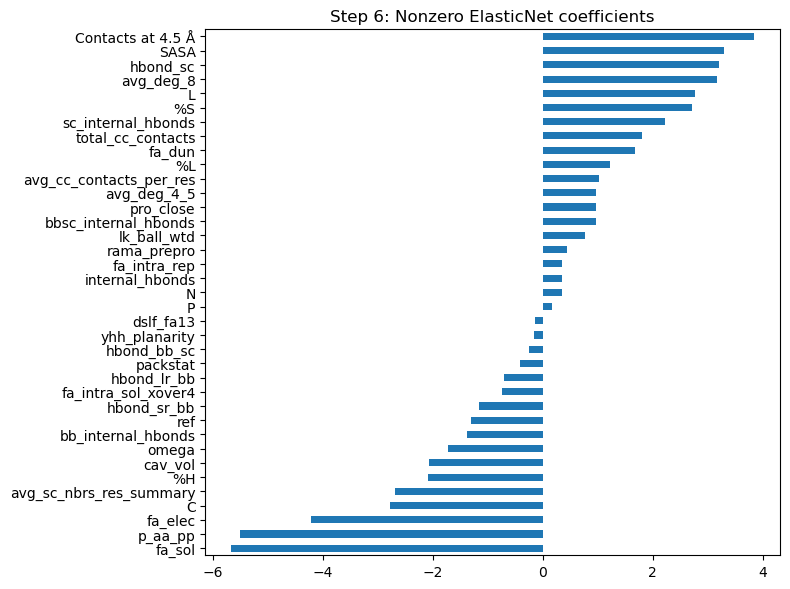

In [209]:
# --- 6) Fit penalized model (elastic net CV) to select among linear and quadratic terms ---
enet = ElasticNetCV(l1_ratio=[.1, .5, .75, .9, 1.0], cv=5, n_alphas=100, max_iter=5000)
enet.fit(X_final, y)
print("ElasticNet alpha:", enet.alpha_, "l1_ratio:", enet.l1_ratio_)
coef_series = pd.Series(enet.coef_, index=X_final.columns)
print("Nonzero coefficients:\n", coef_series[coef_series.abs() > 1e-6])

# --- STEP 6: Coefficients from ElasticNet ---
fig, ax = plt.subplots(figsize=(8,6))
coef_series[coef_series.abs()>1e-6].sort_values().plot(kind="barh")
plt.title("Step 6: Nonzero ElasticNet coefficients")
plt.tight_layout()
plt.show()

In [210]:
# --- 7) Optional: fit OLS with selected features for interpretability:
selected_features = coef_series[coef_series.abs() > 1e-6].index.tolist()
X_ols = sm.add_constant(Xc[selected_features])  # use un-scaled (or scaled) depending on interpretability
ols_res = sm.GLM(y, X_ols).fit()
print(ols_res.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                  194
Model:                            GLM   Df Residuals:                      158
Model Family:                Gaussian   Df Model:                           35
Link Function:               Identity   Scale:                          47.419
Method:                          IRLS   Log-Likelihood:                -629.60
Date:                Wed, 01 Oct 2025   Deviance:                       7485.2
Time:                        15:18:02   Pearson chi2:                 7.49e+03
No. Iterations:                     4   Pseudo R-squ. (CS):             0.9995
Covariance Type:            nonrobust                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

In [211]:
subset = pd.merge(embedding_df['cluster'], filtered.set_index('uid'), left_index=True, right_index=True) #filtered[~filtered['temp'].isin([37, 30, 28, 25])].copy() #[(filtered.length > 200)]
x_test = pd.DataFrame(scaler.transform(subset[scaler.feature_names_in_]), index=subset.index, columns=scaler.feature_names_in_)
# for col1, col2 in itertools.product(x_test.columns, mean_df['cluster'].unique()):
#     x_test[f'{col1}_cluster{col2}'] = x_test[col1] * pd.get_dummies(subset['cluster']).astype(int).loc[:, _cluster]

In [212]:
x_test * ols_res.params

,%H,%L,%S,C,Contacts at 4.5 Å,L,N,P,SASA,avg_cc_contacts_per_res,...,lk_ball_wtd,omega,p_aa_pp,packstat,pro_close,rama_prepro,ref,sc_internal_hbonds,total_cc_contacts,yhh_planarity
GB_GCA_000016765.1,3.821027,2.527533,2.998027,-2.846590,-14.341568,-2.127893,-0.020756,0.084709,-3.934010,38.799108,...,0.626506,-1.526566,-4.038594,-0.770082,-0.272409,-0.168875,-7.509020,5.860267,-37.936608,0.354970
GB_GCA_000242235.1,1.477960,0.795470,1.925387,-4.410256,-4.615253,-1.667887,0.022295,0.084709,-3.728619,9.630165,...,0.255287,1.201993,-8.153733,-0.031621,0.094227,0.379424,-2.463521,0.529823,-1.708939,-0.102031
GB_GCA_000283575.1,2.562091,1.198295,4.097206,3.408073,-5.416948,-1.667887,-0.020756,0.084709,-2.400213,37.075680,...,-0.201390,-2.107634,-0.868210,1.137608,-0.314623,-0.033528,-4.584731,-5.866710,-43.510096,0.444738
GB_GCA_000376885.1,-5.915773,-2.815291,-9.256540,37.808720,-0.552062,-1.667887,0.022295,0.084709,4.793201,11.710375,...,-0.011859,4.280936,-12.541398,0.563250,-1.003023,-0.091348,5.095635,-7.998888,-50.755630,0.330488
GB_GCA_000411155.1,-5.410555,-2.095710,-10.480130,28.426726,1.430898,-1.667887,-0.020756,0.084709,2.554830,-4.161903,...,0.487665,-1.391010,-9.421886,0.522224,0.484159,0.488495,0.322033,-1.602355,-20.101448,-0.077549
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RS_GCF_905397275.1,3.086987,2.203136,1.744665,-13.792251,-6.499685,-1.667887,-0.020756,0.084709,-4.845979,-6.737153,...,0.520561,-8.561206,6.727992,0.194020,-0.140764,0.130216,-3.333475,3.728089,32.289336,-0.934425
RS_GCF_905397435.1,3.086987,2.203136,1.744665,-13.792251,-0.064552,-1.667887,-0.020756,0.084709,-3.878685,-12.153983,...,0.579211,-9.397531,3.592128,0.501712,-0.110901,0.182334,-3.959983,0.529823,39.534870,-0.758969
RS_GCF_907163105.1,-5.652213,-3.360499,-6.025109,-12.228585,7.998814,10.292261,0.022295,0.084709,0.912221,-32.910224,...,0.751299,1.846478,-2.881268,0.378635,-0.242390,-0.206578,7.980327,9.058533,11.667432,0.220318
RS_GCF_907163265.1,2.383900,2.014395,0.031427,-7.537588,-7.856401,-1.667887,-0.020756,0.084709,-5.303861,-32.250597,...,0.161165,-6.527074,5.686943,0.645301,0.159424,0.082249,-2.973585,4.794178,58.484728,-0.297888


In [218]:
gtdb_md = pd.read_csv('/data/mhoffert/genomes/GTDB_r214.1/bac120_metadata.tsv.gz', sep='\t', compression='gzip')

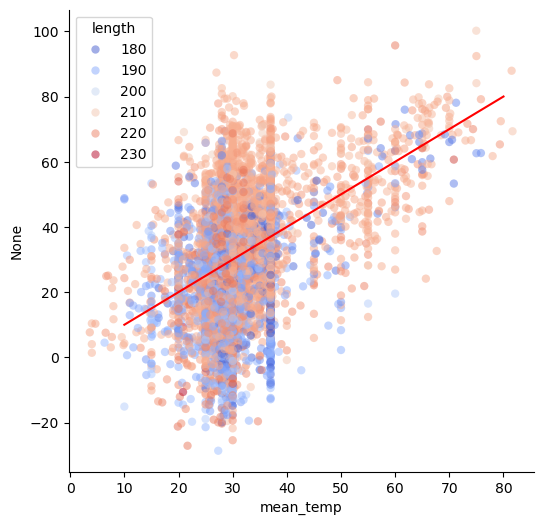

In [213]:
fig, ax = plt.subplots(figsize=(6,6))
# preds = inverse_transform(ols_res.predict(sm.add_constant(x_test[selected_features])), a, b)
preds = ols_res.predict(sm.add_constant(x_test[selected_features]))

sns.scatterplot(y=preds,
                x=subset['mean_temp'], 
                hue=subset['length'], palette='coolwarm', 
                linewidth=0, alpha=0.5)

plt.plot((10, 80), (10, 80), color='r')
# ax.set_ylim(-10, 110)

sns.despine()

<Axes: xlabel='gtdb_taxonomy', ylabel='None'>

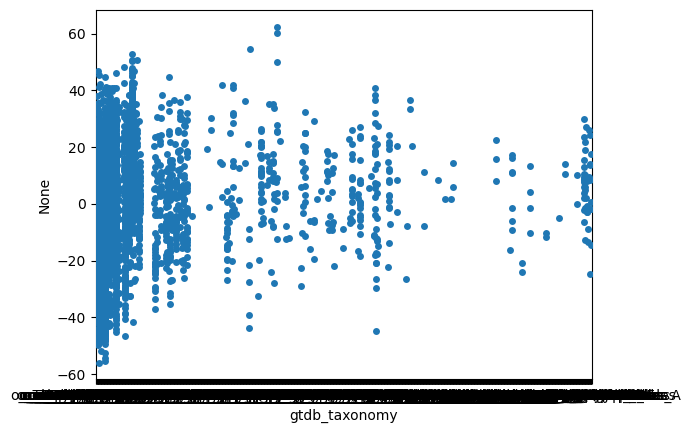

In [225]:
sns.stripplot(y=preds - subset['mean_temp'],
             x=gtdb_md.set_index('accession')['gtdb_taxonomy'].apply(lambda x: x.split(';')[-4]))
            

accession
RS_GCF_001206855.1       o__Lactobacillales
RS_GCF_001108865.1       o__Lactobacillales
RS_GCF_000730125.1       o__Actinomycetales
RS_GCF_000950275.1    o__Enterobacterales_A
RS_GCF_000468955.1       o__Lactobacillales
                              ...          
GB_GCA_934776845.1    o__Christensenellales
GB_GCA_023647245.1      o__Enterobacterales
GB_GCA_020344015.1              o__KS3-K002
GB_GCA_945889495.1               o__UBA9968
GB_GCA_934500585.1               o__UBA1381
Name: gtdb_taxonomy, Length: 394932, dtype: object

In [222]:
gtdb_md

,accession,ambiguous_bases,checkm_completeness,checkm_contamination,checkm_marker_count,checkm_marker_lineage,checkm_marker_set_count,checkm_strain_heterogeneity,coding_bases,coding_density,...,ssu_silva_blast_align_len,ssu_silva_blast_bitscore,ssu_silva_blast_evalue,ssu_silva_blast_perc_identity,ssu_silva_blast_subject_id,ssu_silva_taxonomy,total_gap_length,trna_aa_count,trna_count,trna_selenocysteine_count
0,RS_GCF_001206855.1,14,99.60,0.91,761,g__Streptococcus (UID584),238,50.00,1827337,86.246727,...,1543,2844,0,99.935,CP028436.1781495.1783046,Bacteria;Firmicutes;Bacilli;Lactobacillales;St...,21,19,35,0
1,RS_GCF_001108865.1,13,99.39,0.34,761,g__Streptococcus (UID584),238,33.33,1852015,86.277715,...,1543,2844,0,99.935,AKVY01000001.1976120.1977665,Bacteria;Firmicutes;Bacilli;Lactobacillales;St...,0,19,38,0
2,RS_GCF_000730125.1,30,100.00,0.92,476,f__Bifidobacteriaceae (UID1462),217,0.00,2212698,86.271453,...,1522,2811,0,100,CP008885.1576966.1578495,Bacteria;Actinobacteriota;Actinobacteria;Bifid...,619,19,55,0
3,RS_GCF_000950275.1,0,99.45,0.53,921,f__Vibrionaceae (UID4865),366,0.00,4128151,84.994806,...,655,1210,0,100,KY272023.1.1437,Bacteria;Proteobacteria;Gammaproteobacteria;En...,0,17,77,1
4,RS_GCF_000468955.1,0,100.00,0.00,472,o__Lactobacillales (UID543),265,0.00,2107260,86.823994,...,1545,2848,0,99.935,CP003157.2105633.2107180,Bacteria;Firmicutes;Bacilli;Lactobacillales;St...,0,19,60,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
394927,GB_GCA_934776845.1,0,91.57,0.00,149,k__Bacteria (UID2329),89,0.00,779596,89.630474,...,1490,1655,0,87.047,FJ951868.1.1481,Bacteria;Firmicutes;Clostridia;Christensenella...,0,19,41,0
394928,GB_GCA_023647245.1,4609,99.97,0.13,1162,f__Enterobacteriaceae (UID5121),336,0.00,4707023,87.866887,...,1315,2396,0,99.316,CP033396.457925.459474,Bacteria;Proteobacteria;Gammaproteobacteria;En...,0,19,80,1
394929,GB_GCA_020344015.1,0,93.69,3.30,147,k__Bacteria (UID2495),91,0.00,4223673,87.882712,...,none,none,none,none,none,none,27200,18,46,1
394930,GB_GCA_945889495.1,0,90.94,3.23,247,c__Deltaproteobacteria (UID3216),155,0.00,4966708,87.941933,...,1538,2719,0,98.57,FPLL01004645.16.1553,Bacteria;RCP2-54;metagenome,0,18,46,1


<Axes: xlabel='length', ylabel='None'>

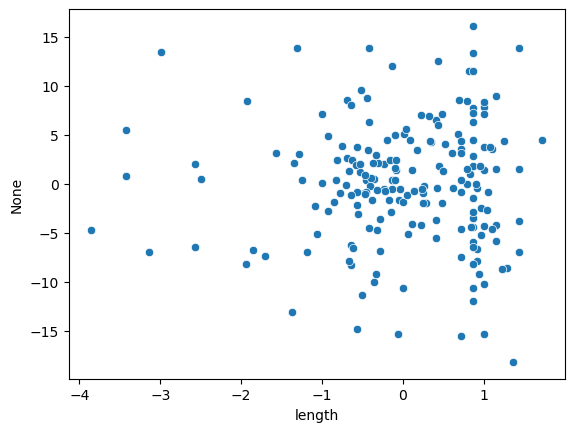

In [217]:
sns.scatterplot(y=ols_res.resid_pearson, x=Xc['length'])

# Phylogenetically independent contrasts

In [227]:
import numpy as np
from scipy import stats
from ete3 import Tree
from typing import Dict, Tuple, List
import pandas as pd

In [232]:
gtdb_tree = Tree('/data/mhoffert/genomes/GTDB_r214.1/bac120_r214.tree', format=1, quoted_node_names=True)

In [233]:
gtdb_tree.describe()

Number of leaf nodes:	80789
Total number of nodes:	161577
Rooted:	Yes
Most distant node:	RS_GCF_003265155.1
Max. distance:	3.393161


In [237]:
pruned = gtdb_tree.copy()
pruned.prune(filtered['uid'].unique(), preserve_branch_length=True)

In [238]:
pruned.describe()

Number of leaf nodes:	8532
Total number of nodes:	17063
Rooted:	Yes
Most distant node:	RS_GCF_005061465.1
Max. distance:	2.994207


In [244]:
prune_names_map = pd.Series()
for i, node in enumerate(pruned.traverse(strategy='levelorder')):
    if not node.is_leaf():
        prune_names_map.loc[node.name] = f'c{i:05d}'
        node.name = f'c{i:05d}'

In [276]:
def compute_phylogenetic_contrasts(tree: Tree, 
                                   trait_values: Dict[str, float],
                                   standardize: bool = True) -> Tuple[np.ndarray, List[str]]:
    """
    Compute Phylogenetic Independent Contrasts (PICs) using Felsenstein's algorithm.
    
    Parameters:
    -----------
    tree : ete3.Tree
        Phylogenetic tree (must have branch lengths)
    trait_values : dict
        Dictionary mapping leaf names to trait values (e.g., {'species1': 25.5, ...})
    standardize : bool
        Whether to standardize contrasts by their standard deviation (recommended)
    
    Returns:
    --------
    contrasts : np.ndarray
        Array of independent contrasts
    node_names : list
        Labels for each contrast (for debugging)
    
    Notes:
    ------
    - Tree must be bifurcating (binary) and have branch lengths
    - Missing values are not allowed
    - Contrasts are computed in postorder traversal
    """
    
    # Make a copy to avoid modifying original tree
    t = tree.copy()
    
    # Check that all leaves have trait values
    leaf_names = set([leaf.name for leaf in t.iter_leaves()])
    trait_names = set(trait_values.keys())
    
    if not leaf_names.issubset(trait_names):
        missing = leaf_names - trait_names
        raise ValueError(f"Missing trait values for leaves: {missing}")
    
    # Storage for contrasts
    contrasts = []
    node_names = []
    
    # Postorder traversal: process leaves first, then internal nodes
    for node in t.traverse("postorder"):
        
        if node.is_leaf():
            # Store trait value at leaf
            node.add_feature("trait_value", trait_values[node.name])
            node.add_feature("trait_variance", 0.0)  # No variance at tips
            
        else:
            # Internal node: compute contrast from children
            children = node.get_children()
            
            if len(children) != 2:
                print(node)
                raise ValueError(f"Tree must be bifurcating. Node has {len(children)} children.")
            
            c1, c2 = children
            
            # Get trait values (either from tips or reconstructed ancestors)
            v1 = c1.trait_value
            v2 = c2.trait_value
            
            # Get branch lengths
            bl1 = c1.dist if c1.dist > 0 else 1e-6  # Avoid zero branch lengths
            bl2 = c2.dist if c2.dist > 0 else 1e-6
            
            # Get variances accumulated along branches
            var1 = c1.trait_variance + bl1
            var2 = c2.trait_variance + bl2
            
            # Compute contrast
            contrast = v1 - v2
            
            # Standard deviation of contrast
            contrast_sd = np.sqrt(var1 + var2)
            
            # Standardize contrast by its expected SD
            if standardize:
                standardized_contrast = contrast / contrast_sd
            else:
                standardized_contrast = contrast
            
            contrasts.append(standardized_contrast)
            node_names.append(f"{c1.name}_vs_{c2.name}")
            
            # Reconstruct ancestral state at this node (weighted average)
            # This is the squared-change parsimony estimate
            node_trait = (v1 * var2 + v2 * var1) / (var1 + var2)
            
            # Variance at this node (for propagating up the tree)
            node_variance = (var1 * var2) / (var1 + var2)
            
            node.add_feature("trait_value", node_trait)
            node.add_feature("trait_variance", node_variance)
    
    return np.array(contrasts), node_names

In [269]:
Xc

,Contacts at 4.5 Å,SASA,avg_deg_4_5,avg_deg_8,avg_sc_nbrs_res_summary,bb_internal_hbonds,bbsc_internal_hbonds,cav_vol,dslf_fa13,fa_dun,...,yhh_planarity,%S,%L,%H,length,avg_cc_contacts_per_res,C,L,N,P
3.5000,-1.079029,0.438081,1.762341,-0.927039,1.519158,1.333695,-1.574386,1.955284,0.074644,0.392327,...,-0.340265,0.553639,1.033130,-0.961026,1.148864,0.235058,0.865651,0.628152,0.504787,0.561728
3.8335,-1.960986,-2.081360,0.859619,-1.986403,-0.420856,0.624444,1.830508,-0.363921,0.074644,-1.431722,...,1.331859,-0.081472,2.167558,-1.521930,0.862975,-2.805484,0.412485,0.743648,-0.193220,0.561728
4.5000,-0.831015,0.626472,1.000669,-2.137741,0.470827,2.245591,-2.753003,-0.427447,0.074644,0.651221,...,-1.198524,0.553639,0.513284,-0.588251,1.148864,0.613843,0.865651,0.628152,0.504787,0.561728
6.5000,0.747204,1.076794,-0.353415,-0.202780,1.916800,0.877748,0.193540,0.228376,0.074644,0.806674,...,-0.525235,-1.691320,-1.554767,1.787537,-0.352056,0.742282,1.205525,-1.624035,1.551798,0.561728
6.8335,-0.026027,-0.053602,-0.861197,-0.700033,1.139590,1.181713,1.961465,0.914147,0.074644,-0.029215,...,0.947122,0.672782,0.259735,-0.453816,1.363282,0.636661,1.092234,0.714774,0.504787,0.561728
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
77.8335,2.086046,-0.915613,0.746778,1.645701,0.434678,0.725765,1.961465,2.512120,0.074644,0.350377,...,-0.517836,1.653037,0.418546,-0.957542,0.862975,0.750134,0.865651,0.628152,-0.542224,-4.604130
79.1665,0.237265,2.925268,-1.072772,-2.483655,-0.216009,1.941626,0.389976,-0.835290,0.074644,1.846306,...,-0.325468,0.867517,1.378898,-1.333801,1.434754,2.168944,1.092234,0.628152,1.551798,0.561728
79.5000,1.617401,0.961441,0.662148,0.045846,-1.047444,1.637660,0.782848,-0.103969,0.074644,0.549334,...,-0.488241,1.100781,0.335570,-0.678410,1.005920,2.983977,0.865651,0.628152,-0.542224,0.561728
81.5000,0.959552,1.276538,-0.057209,1.256547,-0.179860,1.029730,1.175721,-2.157403,0.074644,2.591100,...,0.562386,0.706941,0.943250,-0.957542,0.862975,1.553016,0.639068,0.628152,-0.542224,0.561728


In [271]:
for col in Xc.columns:
    a,b = compute_phylogenetic_contrasts(pruned, 
                                         filtered.set_index('uid')[col].to_dict(),
                                        standardize=False)
    sasa_contrasts = pd.Series(index=b, data=a)
    
    a,b = compute_phylogenetic_contrasts(pruned, 
                                         filtered.set_index('uid')['mean_temp'].to_dict(),
                                        standardize=False)
    temp_contrasts = pd.Series(index=b, data=a)

    # fig, ax = plt.subplots(figsize=(6,6))
    # sns.scatterplot(x=sasa_contrasts, y=temp_contrasts, linewidth=0, alpha=0.05)
    # ax.set_xlabel('SASA')
    # ax.set_ylabel('temp')
    print(spearmanr(sasa_contrasts, temp_contrasts))

SignificanceResult(statistic=0.02213655041368005, pvalue=0.04089842948948113)
SignificanceResult(statistic=0.04043493912504796, pvalue=0.00018720161914988762)
SignificanceResult(statistic=-0.0067927119955238585, pvalue=0.5304538461753606)
SignificanceResult(statistic=0.008596685090770844, pvalue=0.4272434668255898)
SignificanceResult(statistic=-0.014665618402483245, pvalue=0.17559575397105667)
SignificanceResult(statistic=0.007515190080041174, pvalue=0.48765920080148906)
SignificanceResult(statistic=-0.012205247479361407, pvalue=0.25966000171415454)
SignificanceResult(statistic=-0.01653426982805032, pvalue=0.1267505227033308)
SignificanceResult(statistic=-0.0020523867928009653, pvalue=0.8496712769584581)
SignificanceResult(statistic=0.05182608295056182, pvalue=1.6732159583637545e-06)
SignificanceResult(statistic=-0.04185828085710483, pvalue=0.00011004610717967183)
SignificanceResult(statistic=0.058679424738922584, pvalue=5.8374134338018265e-08)
SignificanceResult(statistic=0.0485693249

In [283]:
from ete3 import Tree

# Simple test tree
t = Tree("(((A:1,B:1):1,(C:1,(D:1,E:1):1):1):1,((F:1,G:1):1,(H:1,(I:1,J:1):1):1):1);")

# Assign trait values to leaves
traits = {
    "A": 5.0,
    "B": 7.0,
    "C": 6.0,
    "D": 9.0,
    "E": 8.0,
    "F": 4.0,
    "G": 3.0,
    "H": 10.0,
    "I": 11.0,
    "J": 12.0,
}

for leaf in t:
    leaf.add_feature("trait", traits[leaf.name])

# Quick look at contrasts: just differences at each split
for node in t.traverse("postorder"):
    node.name = ''.join([l.name for l in node.get_leaves()])
    if not node.is_leaf():
        children = node.get_children()
        if all(hasattr(ch, "trait") for ch in children):
            contrast = children[0].trait - children[1].trait
            print(f"Node {node.name or 'internal'}: contrast = {contrast}")
            node.add_feature("trait", sum(ch.trait for ch in children) / 2.0)


Node AB: contrast = -2.0
Node DE: contrast = 1.0
Node CDE: contrast = -2.5
Node ABCDE: contrast = -1.25
Node FG: contrast = 1.0
Node IJ: contrast = -1.0
Node HIJ: contrast = -1.5
Node FGHIJ: contrast = -7.25
Node ABCDEFGHIJ: contrast = -0.5


In [279]:
print(t)


         /-A
      /-|
     |   \-B
   /-|
  |  |   /-C
  |   \-|
  |     |   /-D
  |      \-|
--|         \-E
  |
  |      /-F
  |   /-|
  |  |   \-G
   \-|
     |   /-H
      \-|
        |   /-I
         \-|
            \-J


In [282]:
a, b = compute_phylogenetic_contrasts(t, traits, standardize=False)
pd.Series(index=b, data=a)

A_vs_B   -2.000000
D_vs_E    1.000000
C_vs_    -2.500000
_vs_     -1.000000
F_vs_G    1.000000
I_vs_J   -1.000000
H_vs_    -1.500000
_vs_     -7.100000
_vs_     -0.451613
dtype: float64

In [266]:
spearmanr(sasa_contrasts, temp_contrasts)

SignificanceResult(statistic=0.04043493912504796, pvalue=0.00018720161914988762)

In [241]:






# Example usage
if __name__ == "__main__":
    # Create example tree
    tree_string = "((A:1,B:1):1,(C:1.5,D:1.5):0.5);"
    tree = Tree(tree_string, format=1)
    
    # Example trait values
    temperature = {'A': 25, 'B': 30, 'C': 37, 'D': 42}
    protein_feature = {'A': 0.5, 'B': 0.6, 'C': 0.8, 'D': 0.9}
    
    # Test correlation
    result = test_pic_correlation(tree, temperature, protein_feature)
    
    print(f"Correlation: {result['correlation']:.3f}")
    print(f"P-value: {result['p_value']:.3e}")
    print(f"Number of contrasts: {result['n_contrasts']}")
    
    # Example with embedding matrix
    species = ['A', 'B', 'C', 'D']
    embeddings = np.random.randn(4, 100)  # 4 species, 100 features
    
    results_df = test_embedding_pcs_with_pics(
        tree, temperature, embeddings, species, n_pcs=10
    )
    
    print("\nResults for each PC:")
    print(results_df[results_df['adj_p_value'] < 0.05])

Correlation: 0.999
P-value: 2.717e-02
Number of contrasts: 3


ValueError: n_components=10 must be between 0 and min(n_samples, n_features)=4 with svd_solver='full'

# Phylogenetic blocking

the majority of this code is implemented because it is very annoying to efficiently get a fast cophenetic matrix from ete3

## Code for building phylogenetically-informed folds

In [329]:
sys.path.append('/data/mhoffert/fiererlab/phylogenetic_blocking/')
# available here: https://github.com/realmichaelhoffert/phylogenetic_blocking.git
from phylo_blocks import *

In [330]:
gtdb_full = Tree('/data/mhoffert/genomes/GTDB_r214.1/bac120_r214.tree', format=1, quoted_node_names=True)

In [331]:
# first, prune tree
gtdb_pruned = gtdb_full.copy()

gtdb_pruned.prune(list(filtered['uid'].unique()), preserve_branch_length=True)

gtdb_pruned.describe()

Number of leaf nodes:	8532
Total number of nodes:	17063
Rooted:	Yes
Most distant node:	RS_GCF_005061465.1
Max. distance:	2.994207


In [332]:
# generating pre-processed root-node distance mapping
# uniquely re-naming each node
for i, node in enumerate(gtdb_pruned.traverse('levelorder')):

    if not node.is_leaf():
        node.name = f'c{i}'

root = gtdb_pruned.get_tree_root()
d_root = {node.name: node.get_distance(root) for node in gtdb_pruned.traverse("preorder")}

In [333]:
lca_cache = compute_lca_cache_fast_v2(gtdb_pruned)

0.999531             |***************************************-|


In [334]:
%%time
matrix, leaves = fast_cophenetic_matrix(gtdb_pruned, d_root, lca_cache)

CPU times: user 31.8 s, sys: 1.28 s, total: 33.1 s**********-|||
Wall time: 32.9 s


In [335]:
matrix.shape

(8532, 8532)

In [336]:
fold_dict = cluster_cophenetic_matrix(matrix, leaves, 10)

performing embeddings
performing kmeans
Performing dictionary
Cluster sizes: Counter({8: 1370, 1: 1357, 4: 1235, 2: 963, 3: 864, 6: 703, 0: 655, 9: 634, 7: 445, 5: 306})


In [337]:
%%time
compute_min_interfold_distances(matrix, leaves, fold_dict)

CPU times: user 21.6 s, sys: 220 ms, total: 21.8 s
Wall time: 19.4 s


array([[       inf, 2.11025516, 2.4351814 , ..., 2.22611614, 0.10910666,
        2.25700003],
       [2.11025516,        inf, 1.72554712, ..., 1.51648186, 2.04601157,
        0.01385192],
       [2.4351814 , 1.72554712,        inf, ..., 0.00662097, 2.3709378 ,
        1.87229198],
       ...,
       [2.22611614, 1.51648186, 0.00662097, ...,        inf, 2.16187255,
        1.66322673],
       [0.10910666, 2.04601157, 2.3709378 , ..., 2.16187255,        inf,
        2.19275643],
       [2.25700003, 0.01385192, 1.87229198, ..., 1.66322673, 2.19275643,
               inf]])

In [338]:
# modeling
drop_cols =['Position',
 'temp',
 'mean_temp',
 'Unnamed: 0',
 'lid_bitscore',
 'total_score',
 'seq_length',
 'max_structure_length',
 'group',
'bitscore', 'fa_atr', 'group']

X_original = filtered.set_index('uid').drop(drop_cols + sasa_columns, axis=1)
X_original = X_original.rename(columns=dict((c, c.replace(' ', '_')) for c in X_original.columns))
y = filtered.set_index('uid')['temp']

## Model

0


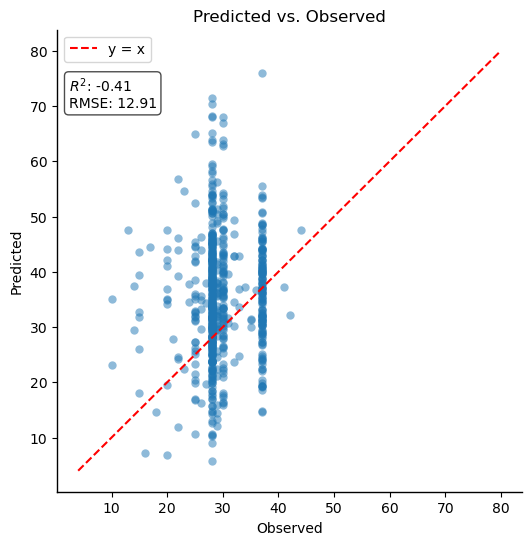

1


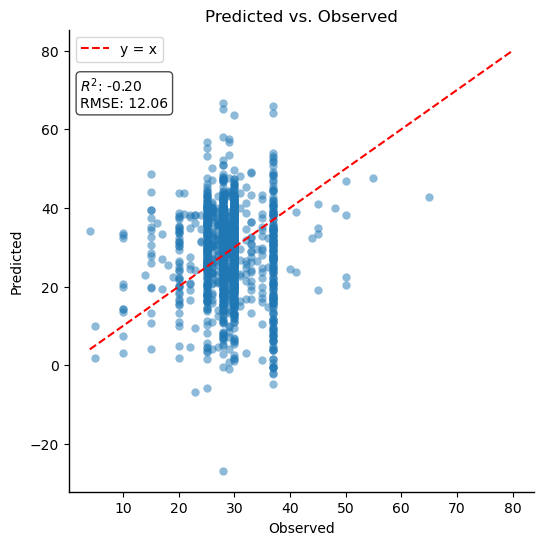

2


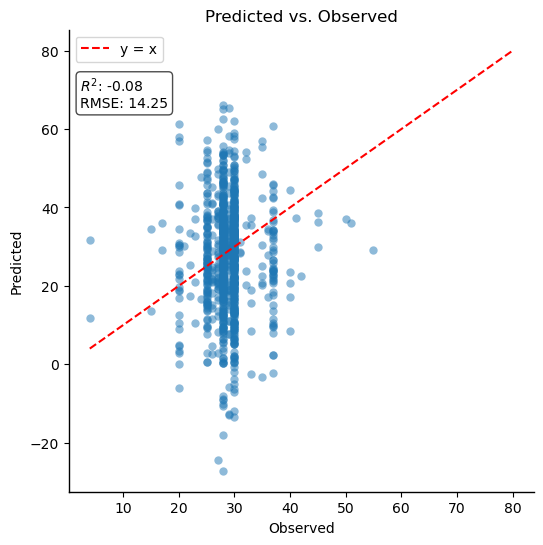

3


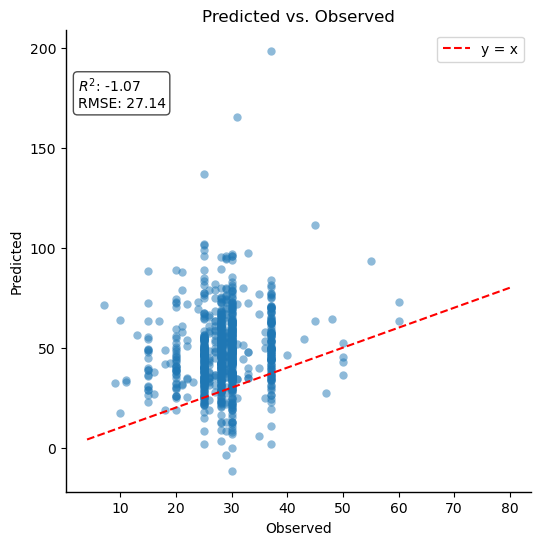

4


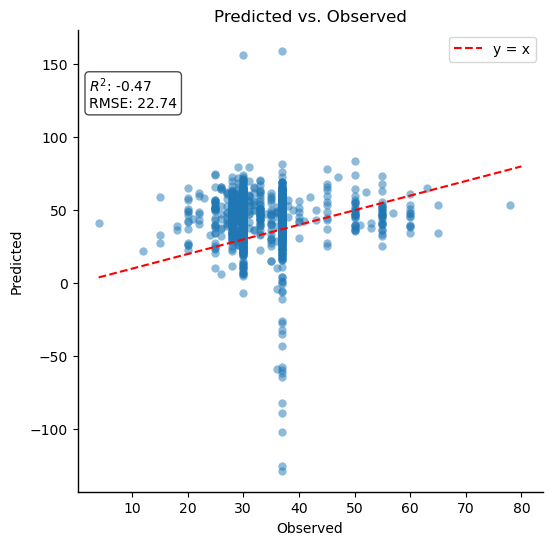

5


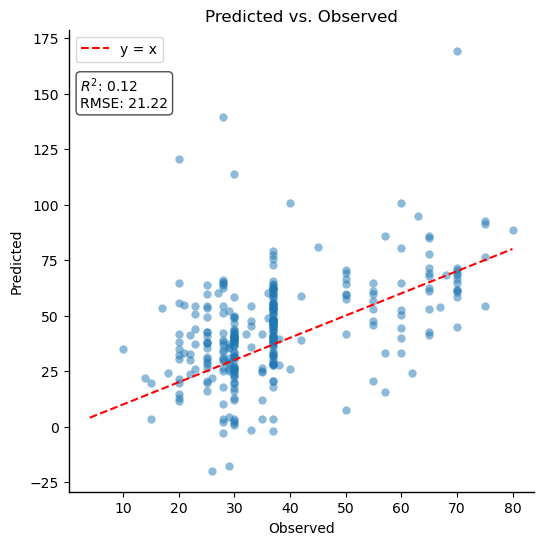

6


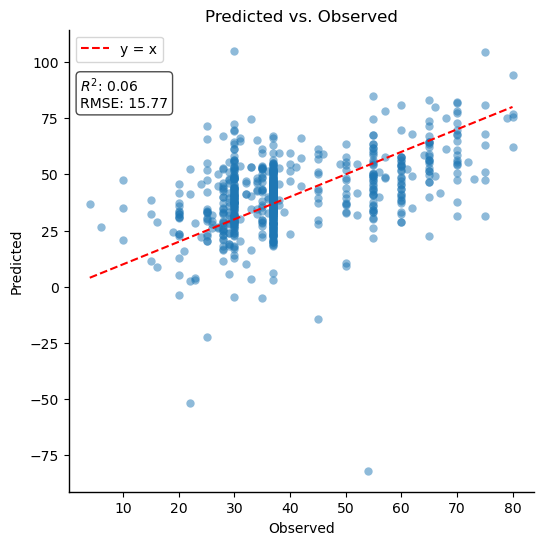

7


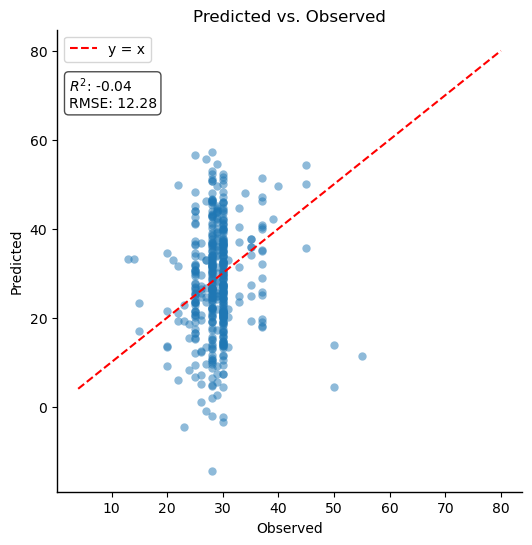

8


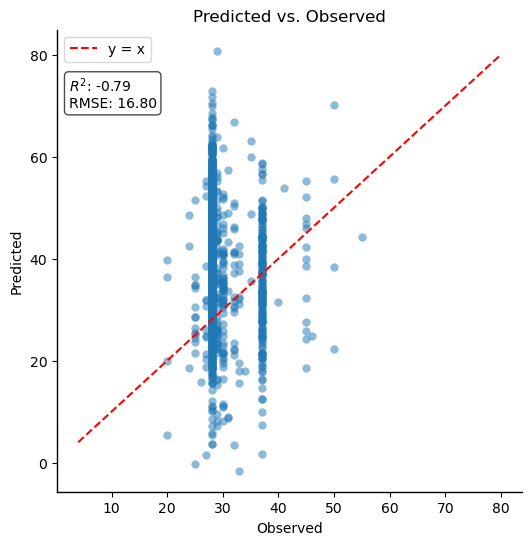

9


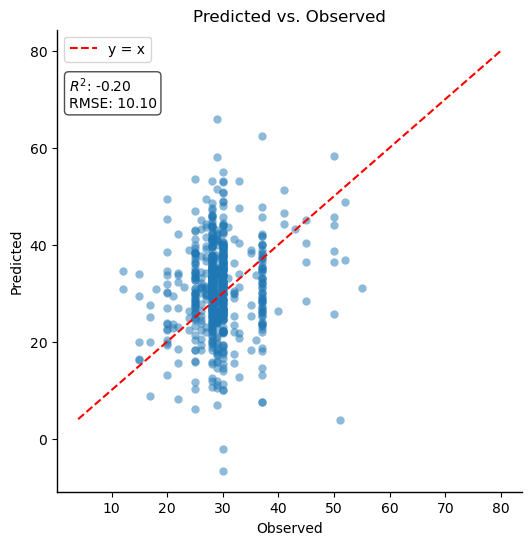

In [339]:
fold_indices = defaultdict(list)
for i, leaf_name in enumerate(leaves):
    fold = fold_dict[leaf_name]
    fold_indices[fold].append(leaf_name)
    
models = []
for fold in sorted(set(fold_dict.values())):
    print(fold)
    X_test = X_original.loc[fold_indices[fold], :]
    y_test = y.loc[fold_indices[fold]]

    X_train = X_original[~X_original.index.isin(y_test.index)]
    y_train = y[~y.index.isin(y_test.index)]

    scaler = StandardScaler().fit(X_train)
    X = scaler.transform(X_train)
    
    # Create pipeline to include interaction (without higher-order powers)
    poly = PolynomialFeatures(degree=2, interaction_only=True, include_bias=True).fit(X)
    X_poly = poly.transform(X)
    
    weights = compute_gaussian_weights(y_train)
    
    model = sm.GLM(y_train, X_poly, family=sm.families.Gaussian(), var_weights=weights).fit()
    models.append(model)
    test_pred = pd.Series(model.get_prediction(poly.transform(scaler.transform(X_test))).predicted_mean, index=X_test.index)    
    # 1. Predicted vs Observed
    fig, ax = plt.subplots(figsize=(6,6))
    sns.scatterplot(x=y_test, y=test_pred, ax=ax, linewidth=0, alpha=0.5)
    # sns.regplot(x=y, y=y_pred, ci=95, line_kws={"color": "black"}, scatter_kws={"s": 30})
    
    ax.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', label='y = x')
    
    residuals = y - y_pred
    rmse = np.sqrt(mean_squared_error(test_pred, y_test))
    r2 = r2_score_variance_explained(test_pred, y_test)
    
    
    ax.text(0.025, 0.9,
                f"$R^2$: {r2:.2f}\nRMSE: {rmse:.2f}",
                transform=ax.transAxes,
                fontsize=10,
                verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))
    
    ax.set_title('Predicted vs. Observed')
    ax.set_xlabel('Observed')
    ax.set_ylabel('Predicted')
    ax.legend()
    sns.despine()
    plt.show()


In [346]:
weights.max()

790.3024137843353

In [345]:
weights

array([4.45567316, 4.45567316, 1.71434508, ..., 1.77201445, 1.71434508,
       1.71434508])

## Trying to figure out why some predictions are unstable

In [338]:
# 2. Multicollinearity: check condition number of X_poly
print("Condition number of X_poly:", np.linalg.cond(X_poly))

Condition number of X_poly: 7.583326142978395e+17


Text(0.5, 1.0, 'Weight Distribution')

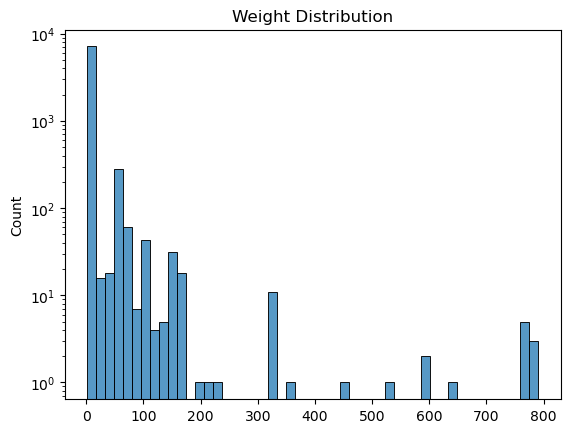

In [340]:
# 3. Weight distribution
fig, ax = plt.subplots()
sns.histplot(weights, bins=50)
ax.set_yscale('log')
plt.title("Weight Distribution")

Exception ignored in: <Finalize object, dead>
Traceback (most recent call last):
  File "/data/mhoffert/miniforge3/envs/adenylate_kinase_ogt/lib/python3.10/multiprocessing/util.py", line 218, in __call__
    if self._pid != getpid():
KeyboardInterrupt: 





In [336]:
plt.figure(figsize=(10, 3 * len(X_original.columns)))
for i, col in enumerate(X_original.columns):
    plt.subplot(len(X_original.columns), 1, i + 1)
    sns.kdeplot(X_train[col], label='train')
    sns.kdeplot(X_test[col], label='test')
    plt.title(f'{col} distribution')
    plt.legend()
plt.tight_layout()


In [337]:
X_original

,Contacts_at_4.5_Å,SASA,avg_deg_4_5,avg_deg_8,avg_sc_nbrs_res_summary,bb_internal_hbonds,bbsc_internal_hbonds,cav_vol,dslf_fa13,fa_atr,...,%S,%L,%H,length,avg_cc_contacts_per_res,bitscore,C,L,N,P
uid,,,,,,,,,,,,,,,,,,,,,
GB_GCA_000376885.1,11.358289,52.616491,1.278,10.765,2.648,124.0,21.0,167.472,0.0,-1068.002,...,0.122995,0.267380,0.609626,187.0,3.080214,178.2,90.0,48.0,42.0,6.0
GB_GCA_000016765.1,11.125581,49.464040,1.316,10.730,2.697,132.0,30.0,185.995,0.0,-1182.655,...,0.167442,0.348837,0.483721,215.0,2.786047,175.3,116.0,49.0,43.0,6.0
GB_GCA_000242235.1,11.289720,49.538232,1.327,10.981,2.842,128.0,22.0,316.792,0.0,-1215.348,...,0.163551,0.322430,0.514019,214.0,3.102804,192.2,117.0,48.0,42.0,6.0
GB_GCA_000283575.1,11.276190,50.018080,1.390,10.905,2.771,129.0,20.0,356.047,0.0,-1156.575,...,0.171429,0.328571,0.500000,210.0,2.804762,168.7,112.0,48.0,43.0,6.0
GB_GCA_001054945.1,11.359116,51.483049,1.243,10.768,2.669,117.0,20.0,211.329,0.0,-1025.660,...,0.127072,0.270718,0.602210,181.0,2.939227,192.9,88.0,44.0,42.0,6.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RS_GCF_905397275.1,11.257919,49.134618,1.353,10.846,2.780,130.0,29.0,444.240,0.0,-1233.408,...,0.162896,0.343891,0.493213,221.0,3.280543,195.8,123.0,48.0,43.0,6.0
RS_GCF_907163105.1,11.502591,51.214600,1.290,11.031,2.738,128.0,25.0,201.476,0.0,-1135.922,...,0.134715,0.259067,0.606218,193.0,3.564767,165.6,122.0,22.0,42.0,6.0
RS_GCF_905397435.1,11.366516,49.484025,1.362,10.810,2.811,133.0,30.0,426.889,0.0,-1237.094,...,0.162896,0.343891,0.493213,221.0,3.339367,194.9,123.0,48.0,43.0,6.0


## Testing GAM

  0% (0 of 11) |                         | Elapsed Time: 0:00:00 ETA:  --:--:--

Training GAM with grid search...


100% (11 of 11) |########################| Elapsed Time: 0:00:28 Time:  0:00:280:02


R² Score: 0.33934791361921035
RMSE: 5.823176261701254


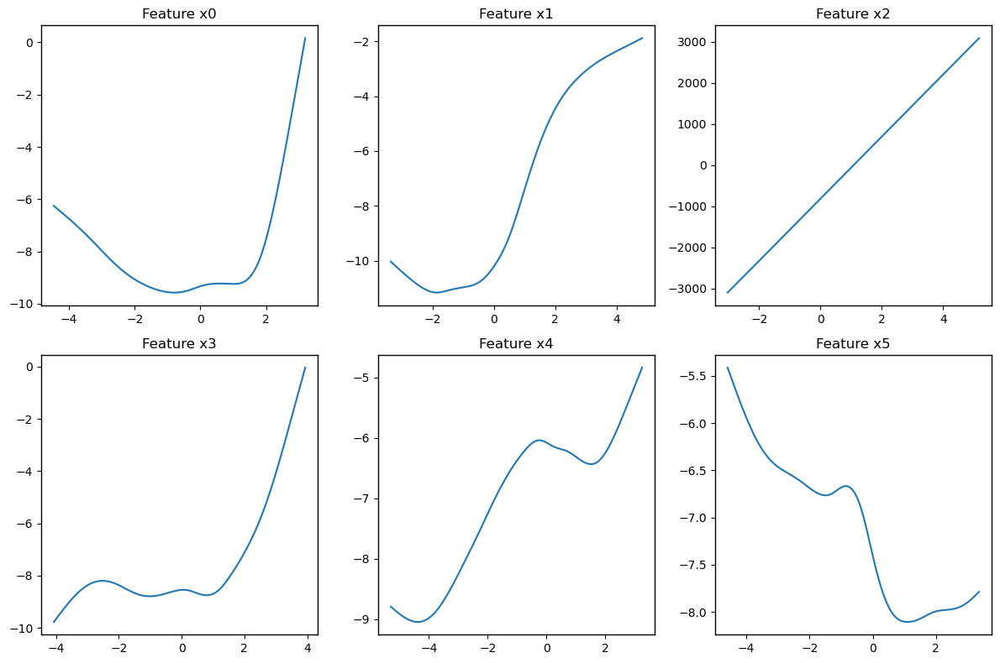

In [149]:
import pandas as pd
import numpy as np
from pygam import LinearGAM, s
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error

# Example: load your real data here
# X = pd.read_csv('your_data.csv')
# y = X.pop('target')

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=143)
train_weights = compute_gaussian_weights(y_train)

# Standardize features (important for splines)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define the model: add a spline term for each variable
terms = s(0)
for i in range(1, X.shape[1]):
    terms += s(i)
    
gam = LinearGAM(terms)

# Train with grid search over smoothing parameters
print("Training GAM with grid search...")
gam.gridsearch(X_train_scaled, y_train, weights=train_weights)

# Evaluate on test set
y_pred = gam.predict(X_test_scaled)
print("R² Score:", r2_score(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

# Plot partial dependence for a few features
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
for i in range(6):  # first 6 terms
    plt.subplot(2, 3, i + 1)
    XX = gam.generate_X_grid(term=i)
    plt.plot(XX[:, i], gam.partial_dependence(term=i, X=XX))
    plt.title(f'Feature x{i}')
plt.tight_layout()
plt.show()


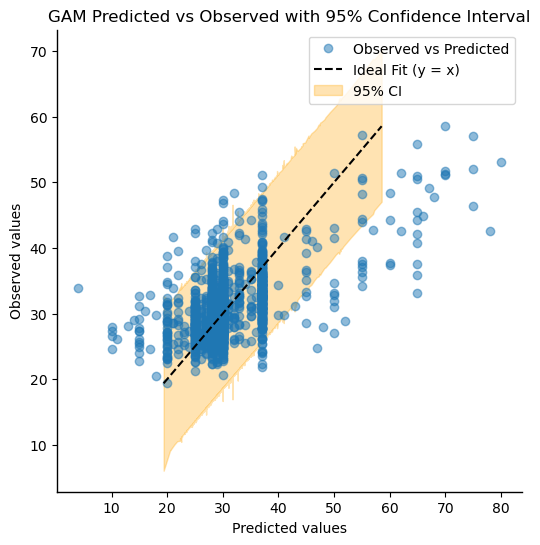

In [151]:
# Predict on test set
y_pred = gam.predict(X_test_scaled)

# Get 95% confidence intervals for predictions
conf_intervals = gam.prediction_intervals(X_test_scaled, width=0.95)
lower, upper = conf_intervals[:, 0], conf_intervals[:, 1]

# Sort for nicer plotting
idx_sort = np.argsort(y_pred)
y_pred_sorted = y_pred[idx_sort]
y_test_sorted = y_test.iloc[idx_sort] if hasattr(y_test, 'iloc') else y_test[idx_sort]
lower_sorted = lower[idx_sort]
upper_sorted = upper[idx_sort]

# Plot
plt.figure(figsize=(6, 6))
plt.plot(y_test_sorted, y_pred_sorted, 'o', alpha=0.5, label='Observed vs Predicted')
plt.plot(y_pred_sorted, y_pred_sorted, 'k--', label='Ideal Fit (y = x)')

sns.despine()

# Fill confidence interval region
plt.fill_between(y_pred_sorted, lower_sorted, upper_sorted, color='orange', alpha=0.3, label='95% CI')

plt.xlabel('Predicted values')
plt.ylabel('Observed values')
plt.title('GAM Predicted vs Observed with 95% Confidence Interval')
plt.legend()
plt.show()

ValueError: operands could not be broadcast together with shapes (8532,1,2) (8532,) 

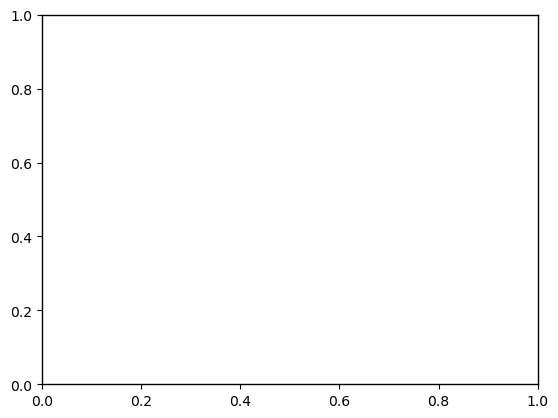

In [139]:
from statsmodels.graphics.regressionplots import plot_ccpr
plot_ccpr(model, [['SASA', 'length']])

In [141]:
from sklearn.feature_selection import mutual_info_regression

mi = mutual_info_regression(X[['SASA']], X[['length']])
print("MI between SASA and lid bitscore:", mi[0])

MI between SASA and lid bitscore: 0.09079958790605058


In [132]:
X

,Contacts at 4.5 Å,SASA,total_score,avg_deg_4_5,avg_deg_8,avg_sc_nbrs_res_summary,bb_internal_hbonds,bbsc_internal_hbonds,cav_vol,dslf_fa13,...,length,avg_cc_contacts_per_res,seq_length,bitscore,C,L,N,P,max_structure_length,lid_bitscore
0,11.358289,52.616491,-454.076,1.278,10.765,2.648,124.0,21.0,167.472,0.0,...,187.0,3.080214,187,178.2,90.0,48.0,42.0,6.0,24,0.0
1,11.125581,49.464040,-450.126,1.316,10.730,2.697,132.0,30.0,185.995,0.0,...,215.0,2.786047,215,175.3,116.0,49.0,43.0,6.0,23,52.3
2,11.289720,49.538232,-419.604,1.327,10.981,2.842,128.0,22.0,316.792,0.0,...,214.0,3.102804,214,192.2,117.0,48.0,42.0,6.0,24,59.2
3,11.276190,50.018080,-452.738,1.390,10.905,2.771,129.0,20.0,356.047,0.0,...,210.0,2.804762,210,168.7,112.0,48.0,43.0,6.0,24,58.3
4,11.359116,51.483049,-431.800,1.243,10.768,2.669,117.0,20.0,211.329,0.0,...,181.0,2.939227,181,192.9,88.0,44.0,42.0,6.0,21,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8527,11.257919,49.134618,-492.694,1.353,10.846,2.780,130.0,29.0,444.240,0.0,...,221.0,3.280543,221,195.8,123.0,48.0,43.0,6.0,28,61.7
8528,11.502591,51.214600,-494.248,1.290,11.031,2.738,128.0,25.0,201.476,0.0,...,193.0,3.564767,193,165.6,122.0,22.0,42.0,6.0,24,0.0
8529,11.366516,49.484025,-469.955,1.362,10.810,2.811,133.0,30.0,426.889,0.0,...,221.0,3.339367,221,194.9,123.0,48.0,43.0,6.0,28,61.6
8530,11.479070,49.243296,-487.960,1.288,10.833,2.731,133.0,34.0,213.390,0.0,...,215.0,3.265116,215,190.8,118.0,48.0,42.0,6.0,24,66.3


In [222]:
print("Shape:", X_transformed.shape)
print("Feature-wise mean (first 10):", np.mean(X_transformed, axis=0)[:10])
print("Feature-wise std  (first 10):", np.std(X_transformed, axis=0)[:10])

Shape: (8532, 1177)
Feature-wise mean (first 10): [ 1.00000000e+00 -1.97893350e-14  3.62756134e-15  1.87285073e-15
 -7.57233432e-16  3.49973996e-15 -1.45559972e-15  1.55359980e-15
 -4.23282287e-16  1.03904487e-16]
Feature-wise std  (first 10): [0. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [157]:
s_err

8.370419033100681

In [122]:
lower_smooth = uniform_filter1d(lower, size=window)


In [145]:
intervals = pd.DataFrame([lower, upper, y_pred], index=['lower', 'upper', 'y']).T.dropna().sort_values('y')
temp = intervals.apply(lambda col: uniform_filter1d(col, size=window)).sample(1000).sort_values('y')

In [151]:
coeffs = pd.Series(data=poly_model.get_params)
coeffs

AttributeError: 'Pipeline' object has no attribute 'coef_'

In [161]:
len(poly_model[:-1].get_feature_names_out())

1176

### Test 2: ogtfinder temps

In [34]:
drop_cols = ['Position', 'temp', 'mean_temp', 'uid', 'Unnamed: 0'] #, 'Genus', 'taxa', 'temp_group']


In [35]:
X = filtered[filtered.uid.isin(ogtfinder_temps.index)].drop(drop_cols, axis=1)
y = filtered[filtered.uid.isin(ogtfinder_temps.index)]['uid'].map(ogtfinder_temps)

In [36]:
X

,Contacts at 4.5 Å,SASA,total_score,avg_deg_4_5,avg_deg_8,avg_sc_nbrs_res_summary,bb_internal_hbonds,bbsc_internal_hbonds,cav_vol,dslf_fa13,...,length,avg_cc_contacts_per_res,seq_length,bitscore,C,L,N,P,max_structure_length,lid_bitscore
4,11.359116,51.483049,-431.800,1.243,10.768,2.669,117.0,20.0,211.329,0.0,...,181.0,2.939227,181,192.9,88.0,44.0,42.0,6.0,21,0.0
6,11.314917,51.804797,-443.850,1.298,10.757,2.727,117.0,22.0,223.269,0.0,...,181.0,3.116022,181,179.2,88.0,44.0,42.0,6.0,21,0.0
8,11.248619,50.426727,-421.557,1.287,10.890,2.767,119.0,25.0,165.650,0.0,...,181.0,3.044199,181,181.4,88.0,44.0,42.0,6.0,21,0.0
9,11.446009,50.458129,-437.262,1.347,10.812,2.679,132.0,32.0,209.604,0.0,...,213.0,3.103286,213,199.8,115.0,48.0,43.0,6.0,24,67.7
15,11.513812,47.834396,-400.078,1.320,10.867,2.692,121.0,28.0,186.972,0.0,...,181.0,3.149171,181,166.1,104.0,27.0,43.0,6.0,25,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8527,11.257919,49.134618,-492.694,1.353,10.846,2.780,130.0,29.0,444.240,0.0,...,221.0,3.280543,221,195.8,123.0,48.0,43.0,6.0,28,61.7
8528,11.502591,51.214600,-494.248,1.290,11.031,2.738,128.0,25.0,201.476,0.0,...,193.0,3.564767,193,165.6,122.0,22.0,42.0,6.0,24,0.0
8529,11.366516,49.484025,-469.955,1.362,10.810,2.811,133.0,30.0,426.889,0.0,...,221.0,3.339367,221,194.9,123.0,48.0,43.0,6.0,28,61.6
8530,11.479070,49.243296,-487.960,1.288,10.833,2.731,133.0,34.0,213.390,0.0,...,215.0,3.265116,215,190.8,118.0,48.0,42.0,6.0,24,66.3


In [37]:
y

4       37.0
6       37.5
8       30.0
9       30.0
15      25.0
        ... 
8527    27.5
8528    37.0
8529    30.0
8530    29.0
8531    27.5
Name: uid, Length: 3196, dtype: float64

In [38]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [39]:
# Simulated dataset
np.random.seed(42)
# n_samples = 1000
# X = np.random.uniform(-3, 3, n_samples).reshape(-1, 1)
# y = 2 * X.flatten() + np.random.normal(scale=(0.5 + X.flatten()**2), size=n_samples)

# Normalize the target variable to compute KDE
scaler = StandardScaler()
y_scaled = scaler.fit_transform(y_train.values.reshape(-1, 1))

# Estimate density of target variable using KDE
kde = KernelDensity(kernel='gaussian', bandwidth=0.2)
kde.fit(y_scaled)
log_density = kde.score_samples(y_scaled)
density = np.exp(log_density)

# Compute weights as inverse of density
weights = 1 / density

# Fit weighted linear regression
model = LinearRegression()
model.fit(X_train, y_train, sample_weight=weights)

# Model predictions
y_pred = model.predict(X_test)

is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.


In [40]:
# Print results
print(f"Model coefficients: {model.coef_}")
print(f"Model intercept: {model.intercept_}")

mae = mean_absolute_error(y_test, y_pred)
print(f"MAE: {mae}")

mse = mean_squared_error(y_test, y_pred)
print(f"MSE: {mse}")

r2 = r2_score(y_test, y_pred)
print(f"R-squared: {r2}")

scores = cross_val_score(model, X_train, y_train, scoring='r2', cv=5)  # Example using R-squared
print(f"Cross-validated R-squared: {np.mean(scores):.2f} ± {np.std(scores):.2f}")

Model coefficients: [ 1.48785872e+01 -7.39072968e-01  5.95305782e+02  3.98653377e+01
  1.36699943e+01 -5.14725714e+01 -2.21998906e-02 -2.40387519e-01
 -3.77479629e-03 -5.90629864e+02 -5.95913518e+02 -5.95346288e+02
 -5.95657098e+02 -6.07843897e+02 -5.96297139e+02 -5.95476028e+02
 -5.95714461e+02 -5.95520544e+02 -5.94833393e+02 -5.95572655e+02
 -5.95865651e+02 -9.39398336e-02 -5.94928405e+02 -3.58018876e+02
 -5.95090167e+02 -5.96663898e+02 -8.14081149e+01 -3.57995153e+02
 -5.95048875e+02 -5.95429111e+02 -5.95247224e+02  3.58019818e+02
  1.68647084e-01 -1.55865673e-01 -6.09416839e+02  1.19360753e+01
  2.34939814e+01 -3.54300567e+01 -1.70366402e+00  2.03001168e+01
 -1.70366399e+00  7.43460965e-02  5.28677157e-01  7.12501321e-01
 -3.30329622e-01 -2.61451297e+00 -6.06660235e-01  3.63599770e-01]
Model intercept: -68.70363920656463
MAE: 8.132586200176478
MSE: 106.21827806118958
R-squared: -0.47448478964805263
Cross-validated R-squared: 0.30 ± 0.03


is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
is_sparse is deprecated and will be removed in a future version. Check `

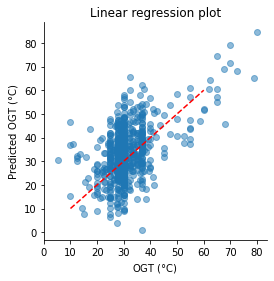

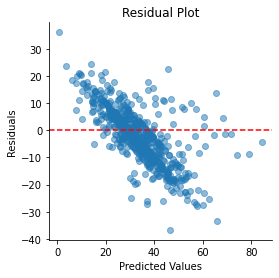

In [43]:
# Plot test dataset
fig, ax = plt.subplots(figsize=(4,4))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot((10, 60), (10, 60), color='red', linestyle='--')
plt.xlabel('OGT ($\degree$C)')
plt.ylabel('Predicted OGT ($\degree$C)')
plt.title('Linear regression plot')
ax.set_xticks(np.linspace(0, 80, 9))
ax.set_yticks(np.linspace(0, 80, 9))
sns.despine()

# plt.savefig('./../data/figures/linear_model_prediction_plot.png', dpi=400, bbox_inches='tight')
plt.show()
residuals = y_test - y_pred

# Plot residuals
fig, ax = plt.subplots(figsize=(4,4))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residual Plot')
sns.despine()

# plt.savefig('./../data/figures/linear_model_residual_plot.png', dpi=400, bbox_inches='tight')
plt.show()

### Test 3: XGBoost

In [53]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_squared_error, make_scorer #, root_mean_squared_error

In [54]:
parameters = {'n_estimators':[100, 500, 1000], 'learning_rate':[0.01, 0.1, 1]}
# reg = RandomForestRegressor(n_jobs=16)
reg = GradientBoostingRegressor()
clf = GridSearchCV(reg, parameters, scoring='neg_root_mean_squared_error')
clf.fit(X=X_train, y=y_train)

is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.
is_sparse is deprecated and will be removed in a future version. Check `

GridSearchCV(estimator=GradientBoostingRegressor(),
             param_grid={'learning_rate': [0.01, 0.1, 1],
                         'n_estimators': [100, 500, 1000]},
             scoring='neg_root_mean_squared_error')

In [55]:
def plot_grid_search(cv_results, grid_param_1, grid_param_2, name_param_1, name_param_2):
    # Get Test Scores Mean and std for each grid search
    scores_mean = cv_results['mean_test_score']
    scores_mean = np.array(scores_mean).reshape(len(grid_param_2),len(grid_param_1))

    scores_sd = cv_results['std_test_score']
    scores_sd = np.array(scores_sd).reshape(len(grid_param_2),len(grid_param_1))

    # Plot Grid search scores
    _, ax = plt.subplots(1,1)

    # Param1 is the X-axis, Param 2 is represented as a different curve (color line)
    for idx, val in enumerate(grid_param_2):
        ax.plot(grid_param_1, scores_mean[idx,:], '-o', label= name_param_2 + ': ' + str(val))

    ax.set_title("Grid Search Scores", fontsize=20, fontweight='bold')
    ax.set_xlabel(name_param_1, fontsize=16)
    ax.set_ylabel('CV Average Score', fontsize=16)
    ax.legend(loc="best", fontsize=15)
    ax.grid('on')



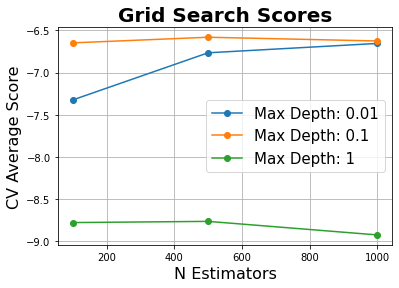

In [56]:
# Calling Method 
plot_grid_search(clf.cv_results_, parameters['n_estimators'], parameters['learning_rate'], 'N Estimators', 'Max Depth')

is_sparse is deprecated and will be removed in a future version. Check `isinstance(dtype, pd.SparseDtype)` instead.


Text(0.5, 1.0, 'Regressor Performance')

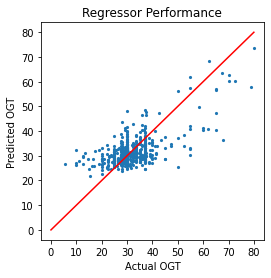

In [57]:
fig, ax = plt.subplots(figsize=(4, 4))
sns.scatterplot(x=y_test, y=clf.best_estimator_.predict(X_test), linewidth=0, alpha=1, s=10)
plt.plot((0, 80), (0, 80), color='r')
yticks = ax.set_yticks(list(np.linspace(0, 80, 9)))
xticks = ax.set_xticks(list(np.linspace(0, 80, 9)))
ax.set_xlabel('Actual OGT')
ax.set_ylabel('Predicted OGT')
ax.set_title('Regressor Performance')

In [42]:
m = ElasticNet()
m = m.fit(X_train, y_train)

# pipe = make_pipeline(StandardScaler(), ElasticNet())


# pipe.fit(X_train, y_train)
# # sa_test_score=root_mean_squared_error(y_test, model.predict(X_test))
# print(pipe.score(X_test, y_test))

ax = fig.add_subplot(1,4,i+1)

# p = m.predict(x)
# sa_test_score=root_mean_squared_error(y_test, m.predict(X_test))


ax.set_title(sa_test_score)
ax.set_xlabel('Actual OGT')
ax.set_ylabel('Predicted OGT')
sns.scatterplot(x=y_test, y=m.predict(X_test), linewidth=0, s=10)
plt.plot((0,80), (0, 80), linewidth=0.5, color='gray')
fig.suptitle('GLMNet performance')

NameError: name 'ElasticNet' is not defined

## Reformatting ESM2 model code

# Additional methods

## Likelihood method

In [24]:
metrics_df = pd.read_csv('/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/metric_tables/20240327_metrics_df_full.tsv.gz', sep='\t')
filtered = pd.read_csv('/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/metric_tables/20240327_metrics_df_filtered.tsv.gz', sep='\t')

In [25]:
plot_filenames = {col_name: col_name.replace(' ','_').strip('Å²()_').replace('Δ','d').replace('%','percent_') for col_name in metrics_df.columns}
metrics_to_plot = [metric for metric in metrics_df.columns if 'Å' in metric or 'SASA' in metric]
metrics_to_plot = metrics_to_plot + [metric for metric in metrics_df.columns if '%' in metric or 'internal_hbonds' in metric or 'sasa' in metric]
metrics_to_plot = metrics_to_plot + ['cav_vol', 'packstat',  'avg_deg_4_5', 'avg_deg_8', 'avg_sc_nbrs_res_summary', 'avg_cc_contacts_per_res']
print(metrics_to_plot)
include_legend = False

['Contacts at 4.5 Å', 'SASA', 'bb_internal_hbonds', 'bbsc_internal_hbonds', 'internal_hbonds', 'nonpolar_sasa', 'polar_sasa', 'sasa', 'sc_internal_hbonds', '%S', '%L', '%H', 'cav_vol', 'packstat', 'avg_deg_4_5', 'avg_deg_8', 'avg_sc_nbrs_res_summary', 'avg_cc_contacts_per_res']


In [284]:
import numpy as np
from scipy.stats import gaussian_kde
from sklearn.model_selection import train_test_split
from scipy.special import softmax

In [66]:
all_columns = metrics_to_plot + additional_metrics

In [573]:
print(all_columns)

['Contacts at 4.5 Å', 'SASA', 'bb_internal_hbonds', 'bbsc_internal_hbonds', 'internal_hbonds', 'nonpolar_sasa', 'polar_sasa', 'sasa', 'sc_internal_hbonds', '%S', '%L', '%H', 'cav_vol', 'packstat', 'avg_deg_4_5', 'avg_deg_8', 'avg_sc_nbrs_res_summary', 'avg_cc_contacts_per_res', 'dslf_fa13', 'fa_atr', 'fa_dun', 'fa_elec', 'fa_intra_rep', 'fa_intra_sol_xover4', 'fa_rep', 'fa_sol', 'hbond_bb_sc', 'hbond_sc', 'hbond_sr_bb', 'lk_ball_wtd', 'omega', 'p_aa_pp', 'pro_close', 'rama_prepro', 'ref', 'total_cc_contacts', 'yhh_planarity']


In [163]:
model_data = filtered[all_columns + ['temp'] + ['uid']].drop('dslf_fa13', axis=1)

In [190]:
model_data['temp_group'] = pd.cut(model_data['temp'], np.linspace(0, 80, 21))

In [191]:
train, test = train_test_split(model_data, test_size=0.1)

## Gaussian smoothing method development

## Gaussian kde

In [166]:
kde_data = train.groupby('temp_group').apply(lambda x: pd.Series(data=[list(x[c].values) for c in model_data.columns],
                                                        index=model_data.columns))

In [168]:
# genus median for Topt and proteins
# Step 1: Fit KDEs for each feature for each T_opt
kde_models = {}
for temp, row in kde_data.iterrows():
    kde_models[temp.right] = {}
    for feature_name, values in row.drop(['temp', 'temp_group']).items():
        if len(values) > 2:
            print(feature_name)
            kde_models[temp.right][feature_name] = gaussian_kde(values)



Contacts at 4.5 Å
SASA
bb_internal_hbonds
bbsc_internal_hbonds
internal_hbonds
nonpolar_sasa
polar_sasa
sasa
sc_internal_hbonds
%S
%L
%H
cav_vol
packstat
avg_deg_4_5
avg_deg_8
avg_sc_nbrs_res_summary
avg_cc_contacts_per_res
fa_atr
fa_dun
fa_elec
fa_intra_rep
fa_intra_sol_xover4
fa_rep
fa_sol
hbond_bb_sc
hbond_sc
hbond_sr_bb
lk_ball_wtd
omega
p_aa_pp
pro_close
rama_prepro
ref
total_cc_contacts
yhh_planarity
uid


TypeError: The `dtype` and `signature` arguments to ufuncs only select the general DType and not details such as the byte order or time unit. You can avoid this error by using the scalar types `np.float64` or the dtype string notation.

In [159]:
# # New observation with feature values to classify
# new_point = {'feature1': 8.0, 'feature2': 3.5}
actual = []
predicted = []
for index, row in test.iterrows():
    # Step 2: Calculate likelihoods for each T_opt
    likelihoods = {}
    for T_opt, feature_kdes in kde_models.items():
        combined_likelihood = 1.0  # Initialize as 1 for multiplying likelihoods
        for feature_name, kde in feature_kdes.items():
            feature_value = row.loc[feature_name]
            feature_likelihood = kde(feature_value)[0] # Likelihood for this feature
            combined_likelihood += np.log10(feature_likelihood)  # Multiply to combine
        likelihoods[T_opt] = combined_likelihood

    # Step 3: Identify T_opt with the highest combined likelihood
    best_T_opt = max(likelihoods, key=likelihoods.get)
    temp = pd.Series(likelihoods).astype(float)
    # print("Predicted T_opt:", best_T_opt)
    # print("Likelihoods by T_opt:", likelihoods)
    actual.append(row['temp'])
    predicted.append(temp[~temp.eq(1)].idxmax())

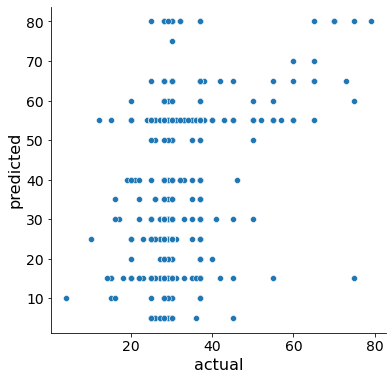

In [170]:
fig, ax = plt.subplots(figsize=(6,6))

sns.scatterplot(x=actual, y=predicted)

ax.set_ylabel('predicted', fontsize=16)
ax.set_xlabel('actual', fontsize=16)
plt.tick_params(labelsize=14)
sns.despine()

In [574]:
filtered

,Unnamed: 0,Position,Contacts at 4.5 Å,SASA,uid,total_score,avg_deg_4_5,avg_deg_8,avg_sc_nbrs_res_summary,bb_internal_hbonds,...,mean_temp,seq_length,bitscore,C,L,N,P,max_structure_length,lid_bitscore,temp_group
0,0,94.0,11.358289,52.616491,GB_GCA_000376885.1,-454.076,1.278,10.765,2.648,124.0,...,37.00,187,178.2,90.0,48.0,42.0,6.0,24,0.0,"(36.0, 38.0]"
1,1,108.0,11.125581,49.464040,GB_GCA_000016765.1,-450.126,1.316,10.730,2.697,132.0,...,30.00,215,175.3,116.0,49.0,43.0,6.0,23,52.3,"(28.0, 30.0]"
2,2,119.5,11.289720,49.538232,GB_GCA_000242235.1,-419.604,1.327,10.981,2.842,128.0,...,37.00,214,192.2,117.0,48.0,42.0,6.0,24,59.2,"(36.0, 38.0]"
3,3,105.5,11.276190,50.018080,GB_GCA_000283575.1,-452.738,1.390,10.905,2.771,129.0,...,30.00,210,168.7,112.0,48.0,43.0,6.0,24,58.3,"(28.0, 30.0]"
4,4,91.0,11.359116,51.483049,GB_GCA_001054945.1,-431.800,1.243,10.768,2.669,117.0,...,37.00,181,192.9,88.0,44.0,42.0,6.0,21,0.0,"(36.0, 38.0]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8527,9336,111.0,11.257919,49.134618,RS_GCF_905397275.1,-492.694,1.353,10.846,2.780,130.0,...,28.75,221,195.8,123.0,48.0,43.0,6.0,28,61.7,"(28.0, 30.0]"
8528,9337,99.0,11.502591,51.214600,RS_GCF_907163105.1,-494.248,1.290,11.031,2.738,128.0,...,33.50,193,165.6,122.0,22.0,42.0,6.0,24,0.0,"(28.0, 30.0]"
8529,9338,111.0,11.366516,49.484025,RS_GCF_905397435.1,-469.955,1.362,10.810,2.811,133.0,...,26.40,221,194.9,123.0,48.0,43.0,6.0,28,61.6,"(26.0, 28.0]"
8530,9339,108.0,11.479070,49.243296,RS_GCF_910593845.1,-487.960,1.288,10.833,2.731,133.0,...,29.50,215,190.8,118.0,48.0,42.0,6.0,24,66.3,"(28.0, 30.0]"


In [575]:
gtdb_md = pd.read_csv('/data/mhoffert/genomes/GTDB_r214.1/bac120_metadata.tsv.gz', sep='\t')

In [576]:
gtdb_md

,accession,ambiguous_bases,checkm_completeness,checkm_contamination,checkm_marker_count,checkm_marker_lineage,checkm_marker_set_count,checkm_strain_heterogeneity,coding_bases,coding_density,...,ssu_silva_blast_align_len,ssu_silva_blast_bitscore,ssu_silva_blast_evalue,ssu_silva_blast_perc_identity,ssu_silva_blast_subject_id,ssu_silva_taxonomy,total_gap_length,trna_aa_count,trna_count,trna_selenocysteine_count
0,RS_GCF_001206855.1,14,99.60,0.91,761,g__Streptococcus (UID584),238,50.00,1827337,86.246727,...,1543,2844,0,99.935,CP028436.1781495.1783046,Bacteria;Firmicutes;Bacilli;Lactobacillales;St...,21,19,35,0
1,RS_GCF_001108865.1,13,99.39,0.34,761,g__Streptococcus (UID584),238,33.33,1852015,86.277715,...,1543,2844,0,99.935,AKVY01000001.1976120.1977665,Bacteria;Firmicutes;Bacilli;Lactobacillales;St...,0,19,38,0
2,RS_GCF_000730125.1,30,100.00,0.92,476,f__Bifidobacteriaceae (UID1462),217,0.00,2212698,86.271453,...,1522,2811,0,100,CP008885.1576966.1578495,Bacteria;Actinobacteriota;Actinobacteria;Bifid...,619,19,55,0
3,RS_GCF_000950275.1,0,99.45,0.53,921,f__Vibrionaceae (UID4865),366,0.00,4128151,84.994806,...,655,1210,0,100,KY272023.1.1437,Bacteria;Proteobacteria;Gammaproteobacteria;En...,0,17,77,1
4,RS_GCF_000468955.1,0,100.00,0.00,472,o__Lactobacillales (UID543),265,0.00,2107260,86.823994,...,1545,2848,0,99.935,CP003157.2105633.2107180,Bacteria;Firmicutes;Bacilli;Lactobacillales;St...,0,19,60,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
394927,GB_GCA_934776845.1,0,91.57,0.00,149,k__Bacteria (UID2329),89,0.00,779596,89.630474,...,1490,1655,0,87.047,FJ951868.1.1481,Bacteria;Firmicutes;Clostridia;Christensenella...,0,19,41,0
394928,GB_GCA_023647245.1,4609,99.97,0.13,1162,f__Enterobacteriaceae (UID5121),336,0.00,4707023,87.866887,...,1315,2396,0,99.316,CP033396.457925.459474,Bacteria;Proteobacteria;Gammaproteobacteria;En...,0,19,80,1
394929,GB_GCA_020344015.1,0,93.69,3.30,147,k__Bacteria (UID2495),91,0.00,4223673,87.882712,...,none,none,none,none,none,none,27200,18,46,1
394930,GB_GCA_945889495.1,0,90.94,3.23,247,c__Deltaproteobacteria (UID3216),155,0.00,4966708,87.941933,...,1538,2719,0,98.57,FPLL01004645.16.1553,Bacteria;RCP2-54;metagenome,0,18,46,1


In [604]:
filtered['taxa'] = gtdb_md.set_index('accession').reindex(filtered['uid'])['gtdb_taxonomy'].apply(lambda x: x.split(';')[-4]).values

In [605]:
temp = filtered.groupby('taxa').agg({'SASA':'mean', 'temp':'mean', 'Position':'count'}).reset_index()

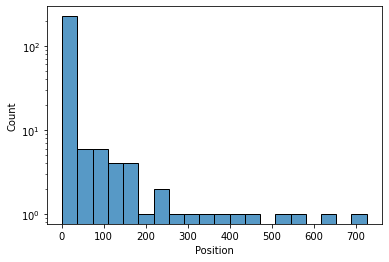

In [606]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(temp['Position'], bins=20)
ax.set_yscale('log')

(10.0, 80.0)

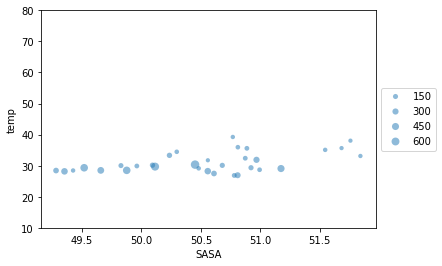

In [614]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.scatterplot(data=temp[temp.Position > 50],
                x='SASA', y='temp', linewidth=0, alpha=0.5, size='Position')
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
ax.set_ylim(10, 80)

<Axes: xlabel='temp', ylabel='SASA'>

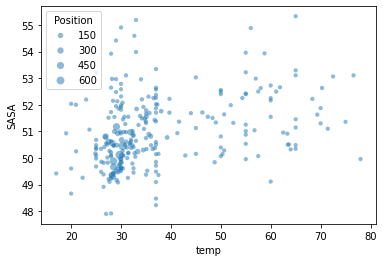

In [610]:
sns.scatterplot(data=temp,
                y='SASA', x='temp', linewidth=0, alpha=0.5, size='Position')

KeyError: 'SASA'

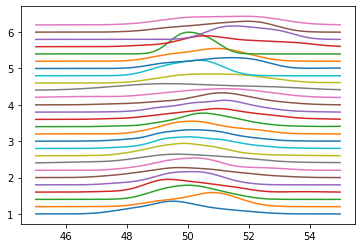

In [153]:
x = list(np.linspace(45, 55, 200))
for _i in range(10, 80):
    if _i in kde_models.keys():
        sns.lineplot(y=[kde_models[_i]['SASA'](i)[0] + (_i/10) for i in x],
                     x=x,)

In [136]:
kde_models.keys()

dict_keys([2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 14.0, 16.0, 18.0, 20.0, 22.0, 24.0, 26.0, 28.0, 30.0, 32.0, 34.0, 36.0, 38.0, 40.0, 42.0, 44.0, 46.0, 48.0, 50.0, 52.0, 54.0, 56.0, 58.0, 60.0, 62.0, 64.0, 66.0, 68.0, 70.0, 72.0, 74.0, 76.0, 78.0, 80.0, 82.0, 84.0, 86.0, 88.0, 90.0, 92.0, 94.0, 96.0, 98.0, 100.0])

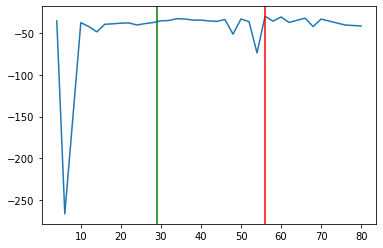

In [123]:
fig, ax = plt.subplots(figsize=(6,4))
temp = pd.Series(likelihoods).astype(float)
sns.lineplot(temp[~temp.eq(1)].apply(np.log10))
ax.axvline(row['temp'], color='green')
ax.axvline(temp[~temp.eq(1)].idxmax(), color='red')

56.0

In [111]:
(temp < 1e-10).head()

2.0     False
4.0      True
6.0      True
8.0     False
10.0     True
dtype: bool

In [109]:
temp[temp <= 1e-10]

4.0      4.391812e-36
6.0     2.394834e-267
10.0     4.417012e-38
12.0     8.126022e-43
14.0     4.472377e-49
16.0     4.911195e-40
18.0     1.671509e-39
20.0     1.037182e-38
22.0     1.889928e-38
24.0     6.904423e-41
26.0     2.702500e-39
28.0     5.161264e-38
30.0     6.591653e-36
32.0     1.707423e-35
34.0     2.651096e-33
36.0     9.278036e-34
38.0     4.532641e-35
40.0     4.711143e-35
42.0     4.751573e-36
44.0     1.440855e-36
46.0     2.349553e-34
48.0     6.541414e-52
50.0     1.111113e-33
52.0     5.773342e-37
54.0     2.347963e-74
56.0     2.010358e-30
58.0     2.844883e-36
60.0     2.728765e-31
62.0     7.317454e-38
66.0     1.083049e-32
68.0     9.018237e-43
70.0     8.200011e-34
76.0     5.830602e-41
80.0     4.298809e-42
dtype: float64

In [108]:
temp[~temp.eq(1) | (temp > 1e-200)]

2.0       1.000000e+00
4.0       4.391812e-36
6.0      2.394834e-267
8.0       1.000000e+00
10.0      4.417012e-38
12.0      8.126022e-43
14.0      4.472377e-49
16.0      4.911195e-40
18.0      1.671509e-39
20.0      1.037182e-38
22.0      1.889928e-38
24.0      6.904423e-41
26.0      2.702500e-39
28.0      5.161264e-38
30.0      6.591653e-36
32.0      1.707423e-35
34.0      2.651096e-33
36.0      9.278036e-34
38.0      4.532641e-35
40.0      4.711143e-35
42.0      4.751573e-36
44.0      1.440855e-36
46.0      2.349553e-34
48.0      6.541414e-52
50.0      1.111113e-33
52.0      5.773342e-37
54.0      2.347963e-74
56.0      2.010358e-30
58.0      2.844883e-36
60.0      2.728765e-31
62.0      7.317454e-38
64.0      1.000000e+00
66.0      1.083049e-32
68.0      9.018237e-43
70.0      8.200011e-34
72.0      1.000000e+00
74.0      1.000000e+00
76.0      5.830602e-41
78.0      1.000000e+00
80.0      4.298809e-42
82.0      1.000000e+00
84.0      1.000000e+00
86.0      1.000000e+00
88.0      1

In [94]:
row['temp']

29.0

In [ ]:
kdes = {}

    kdes[filtered[col].groupby('temp').apply(lambda x: gaussian_kde(values)) for col in metrics_to_plot))

In [ ]:


# Step 1: Estimate the density using Gaussian KDE
kde = gaussian_kde(feature_values)

# Step 2: Define a new point and calculate its likelihood based on the KDE
new_point_value = 6.5  # Example new observation for this feature

# Calculate the density (likelihood) for the new point's feature value
likelihood = kde(new_point_value)

print("Estimated Density (Likelihood) for New Point:", likelihood)

## Quantile regression

In [1]:
from sklearn.linear_model import QuantileRegressor

In [7]:
filtered = pd.read_csv('/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/metric_tables/20240327_metrics_df_filtered.tsv.gz', sep='\t')

In [8]:
qd = filtered.groupby('mean_temp').apply(lambda x: x.sample(np.min([1, len(x)])))
X = qd['SASA'].values.reshape(-1, 1)
y = qd['mean_temp'].values

In [9]:
qd

,,Unnamed: 0,Position,Contacts at 4.5 Å,SASA,uid,total_score,avg_deg_4_5,avg_deg_8,avg_sc_nbrs_res_summary,bb_internal_hbonds,...,temp,mean_temp,seq_length,bitscore,C,L,N,P,max_structure_length,lid_bitscore
mean_temp,,,,,,,,,,,,,,,,,,,,,,
3.620290,7283,7985,108.5,11.287037,51.329232,RS_GCF_018861705.1,-443.329,1.370,10.806,2.774,135.0,...,4.0,3.620290,216,186.5,118.0,48.0,43.0,6.0,23,67.6
4.000000,268,301,107.5,11.224299,48.718660,RS_GCF_000155675.2,-435.194,1.355,10.636,2.656,129.0,...,4.0,4.000000,214,183.7,116.0,49.0,42.0,6.0,24,33.5
4.653187,7282,7984,108.5,11.305556,51.520231,RS_GCF_018861865.1,-441.630,1.352,10.750,2.745,138.0,...,6.0,4.653187,216,186.7,118.0,48.0,43.0,6.0,25,63.7
6.345491,264,297,97.0,11.544041,51.924500,RS_GCF_000153485.2,-450.585,1.301,10.927,2.803,129.0,...,7.0,6.345491,193,173.3,119.0,22.0,45.0,6.0,24,0.0
6.547163,2598,2848,109.5,11.302752,52.029072,RS_GCF_001877035.1,-436.714,1.339,10.752,2.767,138.0,...,10.0,6.547163,218,181.9,120.0,48.0,43.0,6.0,25,67.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
78.000000,6586,7233,107.5,11.523364,49.956800,RS_GCF_014646935.1,-490.653,1.346,10.925,2.744,133.0,...,78.0,78.000000,214,196.7,118.0,48.0,42.0,5.0,24,73.5
79.333333,120,130,109.5,11.385321,53.850847,RS_GCF_000018945.1,-527.650,1.303,10.734,2.726,137.0,...,79.0,79.333333,218,183.7,119.0,48.0,44.0,6.0,24,57.0
79.500000,2523,2767,108.0,11.488372,51.859836,RS_GCF_001719065.1,-503.888,1.344,10.851,2.703,136.0,...,80.0,79.500000,215,182.4,118.0,48.0,42.0,6.0,24,69.2


In [10]:
quantiles = [0.05, 0.5, 0.95]
predictions = {}
out_bounds_predictions = np.zeros_like(y, dtype=np.bool_)
for quantile in quantiles:
    print(quantile)
    qr = QuantileRegressor(quantile=quantile, alpha=0, solver='highs')
    y_pred = qr.fit(X, y).predict(X)
    predictions[quantile] = y_pred

    if quantile == min(quantiles):
        out_bounds_predictions = np.logical_or(
            out_bounds_predictions, y_pred >= y
        )
    elif quantile == max(quantiles):
        out_bounds_predictions = np.logical_or(
            out_bounds_predictions, y_pred <= y
        )

0.05
0.5
0.95


In [16]:
predictions.keys()

dict_keys([0.05, 0.5, 0.95])

In [ ]:
y

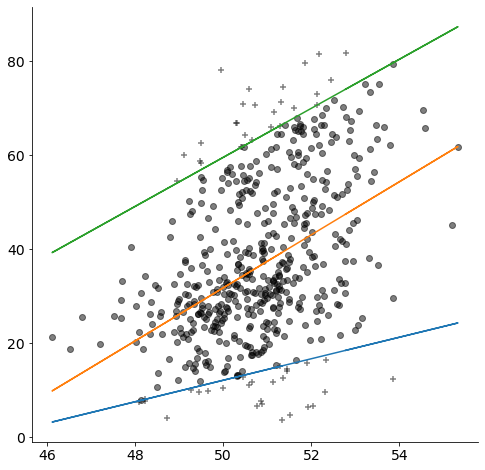

In [14]:
# plt.plot(X, y, color="black", linestyle="dashed", label="True mean")
fig, ax = plt.subplots(figsize=(8,8))

for quantile, y_pred in predictions.items():
    ax.plot(X, y_pred, label=f"Quantile: {quantile}")

ax.scatter(
    X[out_bounds_predictions],
    y[out_bounds_predictions],
    color="black",
    marker="+",
    alpha=0.5,
    label="Outside interval",
)
ax.scatter(
    X[~out_bounds_predictions],
    y[~out_bounds_predictions],
    color="black",
    alpha=0.5,
    label="Inside interval",
)

plt.tick_params(labelsize=14)
sns.despine()

# plt.legend()
# plt.xlabel("x")
# plt.ylabel("y")
# _ = plt.title("Quantiles of heteroscedastic Normal distributed target")

In [ ]:
from numpy.linalg import norm
 
# define two lists or array
A = np.array([2,1,2,3,2,9])
B = np.array([3,4,2,4,5,5])
 
print("A:", A)
print("B:", B)
 
# compute cosine similarity
cosine = np.dot(A,B)/(norm(A)*norm(B))

In [97]:
filtered.set_index('mean_temp')[metrics_to_plot]

,Contacts at 4.5 Å,SASA,bb_internal_hbonds,bbsc_internal_hbonds,internal_hbonds,nonpolar_sasa,polar_sasa,sasa,sc_internal_hbonds,%S,%L,%H,cav_vol,packstat,avg_deg_4_5,avg_deg_8,avg_sc_nbrs_res_summary,avg_cc_contacts_per_res
mean_temp,,,,,,,,,,,,,,,,,,
37.00,11.358289,52.616491,124.0,21.0,166.0,5516.588,4111.250,9627.839,21.0,0.122995,0.267380,0.609626,167.472,0.576,1.278,10.765,2.648,3.080214
30.00,11.125581,49.464040,132.0,30.0,196.0,6315.315,4147.046,10462.361,34.0,0.167442,0.348837,0.483721,185.995,0.641,1.316,10.730,2.697,2.786047
37.00,11.289720,49.538232,128.0,22.0,179.0,6323.363,4168.722,10492.085,29.0,0.163551,0.322430,0.514019,316.792,0.605,1.327,10.981,2.842,3.102804
30.00,11.276190,50.018080,129.0,20.0,172.0,6057.662,4275.751,10333.413,23.0,0.171429,0.328571,0.500000,356.047,0.548,1.390,10.905,2.771,2.804762
37.00,11.359116,51.483049,117.0,20.0,168.0,4898.901,4315.683,9214.585,31.0,0.127072,0.270718,0.602210,211.329,0.591,1.243,10.768,2.669,2.939227
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28.75,11.257919,49.134618,130.0,29.0,191.0,6426.260,4261.519,10687.780,32.0,0.162896,0.343891,0.493213,444.240,0.594,1.353,10.846,2.780,3.280543
33.50,11.502591,51.214600,128.0,25.0,190.0,5717.950,4053.678,9771.629,37.0,0.134715,0.259067,0.606218,201.476,0.585,1.290,11.031,2.738,3.564767
26.40,11.366516,49.484025,133.0,30.0,192.0,6414.023,4352.185,10766.208,29.0,0.162896,0.343891,0.493213,426.889,0.579,1.362,10.810,2.811,3.339367


In [101]:
from scipy.spatial.distance import pdist,squareform

In [223]:
bins = np.linspace(0, 80, 81)
qd = filtered.copy(deep=True) # filtered.groupby('mean_temp').apply(lambda x: x.sample(np.min([500, len(x)])))
qd['group'] = pd.cut(qd['mean_temp'], bins)

In [219]:
mean_cosines_anchor = pd.Series()
anchor = qd['group'].unique()[31]
for g in qd['group'].unique():
    subset = qd[qd['group'].isin([g, anchor])]
    sq = pd.DataFrame(squareform(pdist(subset[metrics_to_plot], 'cosine')), index=subset['group'].rename('g1'), columns=subset['group'].rename('g2')).stack().reset_index()

    idx = pd.IndexSlice
    temp = sq.groupby(['g1', 'g2']).mean().dropna()
    if len(temp) == 4:
        cos_dissim_anchor = temp.loc[idx[anchor, g], 0]
        mean_cosines_anchor.loc[g] = cos_dissim_anchor

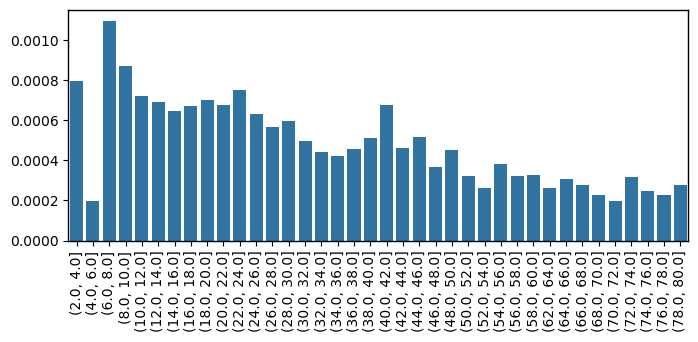

In [222]:
fig, ax = plt.subplots(figsize=(8, 3))
sns.barplot(mean_cosines_anchor.sort_index())
xticks = plt.xticks(rotation=90)

In [172]:
cosines = pdist(qd[['SASA', 'Contacts at 4.5 Å']], 'cosine')
temp_diffs = pdist(qd[['mean_temp']], lambda u, v: np.abs(u-v))


In [173]:
cosine_diffs = pd.DataFrame([cosines, temp_diffs], index=['cosine', 'temp_diff']).T

cosine_diffs['group'] = pd.cut(cosine_diffs['temp_diff'], bins)
anchor = 37

<Axes: xlabel='group', ylabel='cosine'>

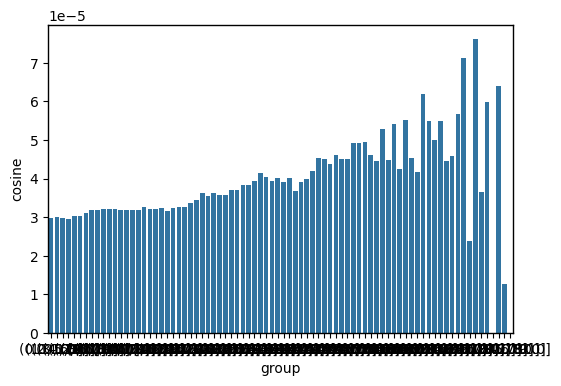

In [174]:
fig, ax = plt.subplots(figsize=(6,4))
sns.barplot(data=cosine_diffs.groupby('group').mean().reset_index(), 
            x='group', y='cosine')

<Axes: xlabel='temp_diff', ylabel='cosine'>

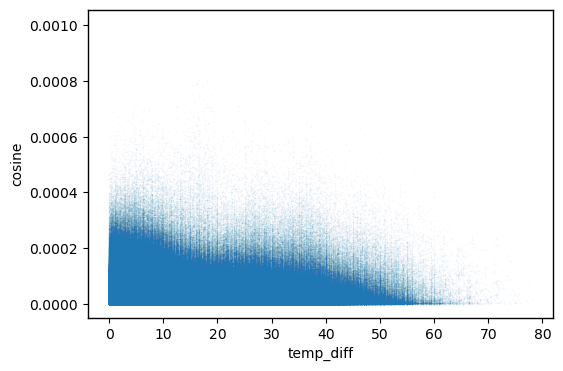

In [175]:
fig, ax = plt.subplots(figsize=(6,4))
sns.scatterplot(data=cosine_diffs, 
            x='temp_diff', y='cosine', alpha=0.05, linewidth=0, s=1)

<Axes: xlabel='temp_diff', ylabel='cosine'>

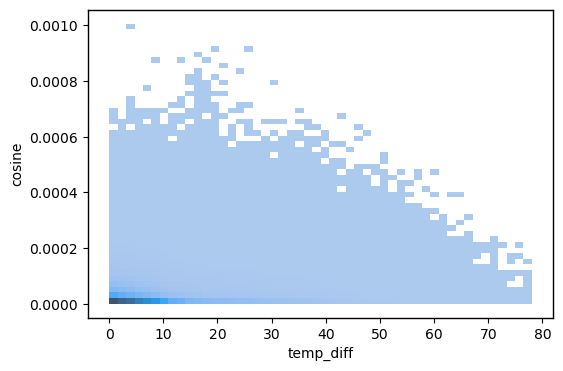

In [176]:
fig, ax = plt.subplots(figsize=(6,4))
sns.histplot(data=cosine_diffs, 
            x='temp_diff', y='cosine', bins=50) #, alpha=0.05, linewidth=0, s=1)

<Axes: xlabel='temp_diff', ylabel='cosine'>

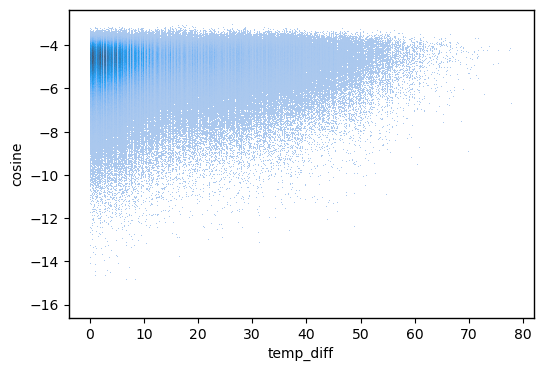

In [177]:
fig, ax = plt.subplots(figsize=(6,4))
sns.histplot( x=cosine_diffs['temp_diff'], y=cosine_diffs['cosine'].apply(np.log10)) #, alpha=0.05, linewidth=0, s=1)

In [158]:
temp = pd.DataFrame(index=['A', 'B', 'C'], data=[[2,1,2,2], [2,2,2,2], [2,0,1,0]])
pd.DataFrame(squareform(pdist(temp, 'cosine')), index=temp.index, columns=temp.index)

,A,B,C
A,0.000000,0.029275,0.255792
B,0.029275,0.000000,0.329180
C,0.255792,0.329180,0.000000


In [178]:
cosine_diffs

,cosine,temp_diff,group
0,4.988796e-05,0.379710,"(0.0, 1.0]"
1,7.502649e-05,0.379710,"(0.0, 1.0]"
2,2.355538e-05,0.379710,"(0.0, 1.0]"
3,9.451912e-08,1.032896,"(1.0, 2.0]"
4,2.680710e-06,2.725201,"(2.0, 3.0]"
...,...,...,...
5690246,2.782963e-05,2.166667,"(2.0, 3.0]"
5690247,4.655200e-06,2.333333,"(2.0, 3.0]"
5690248,2.400692e-06,2.000000,"(1.0, 2.0]"
5690249,2.178283e-05,2.166667,"(2.0, 3.0]"


# Correlation in nonlid regions

In [ ]:
%autoreload 1

from protein_utils import read_pfam_table_pandas, get_lid

from Bio import SeqIO

In [236]:
test_metrics = pd.read_csv('./../data/metric_tables/20240524_full_metrics.tsv', sep='\t')

In [238]:
test_metrics.shape

(1975243, 4)

In [239]:
# code to annotate with lid locs
hmm = '/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/PF05191/PF05191.hmm'
adk_base = '/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/adks/'


lid_locs = pd.DataFrame(index=test_metrics['uid'].unique(), columns=['lid_start', 'lid_stop'],
             data=[get_lid(hmm, f'{adk_base}{uid}_adk.faa') for uid in test_metrics['uid'].unique()])
lid_locs

,lid_start,lid_stop
GB_GCA_000376885.1,-1,-1
GB_GCA_000016765.1,127,163
GB_GCA_000242235.1,141,176
GB_GCA_000283575.1,123,158
GB_GCA_001054945.1,-1,-1
...,...,...
RS_GCF_905397275.1,123,158
RS_GCF_907163105.1,-1,-1
RS_GCF_905397435.1,123,158
RS_GCF_910593845.1,128,163


In [241]:
test_metrics['lid'] = test_metrics.apply(lambda row: (row['Position'] >= lid_locs.loc[row['uid'], 'lid_start']) &
                   (row['Position'] <= lid_locs.loc[row['uid'], 'lid_stop']), axis=1)

In [368]:
residues = 'ILYWVER'
residue_locs = {}
for i, uid in enumerate(test_metrics['uid'].unique()):
    
    
    with open(f'/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/adks/{uid}_adk.faa', 'r') as handle:
        records = [r for r in SeqIO.parse(handle, 'fasta')]
    resmap = dict((i+1, r) for i, r in enumerate(records[0].seq))
    residue_locs[uid] = resmap

In [369]:
%%time
test_metrics['residue'] = test_metrics.apply(lambda row: residue_locs[row['uid']][row['Position']], axis=1)

CPU times: user 24.4 s, sys: 143 ms, total: 24.5 s
Wall time: 24.5 s


In [370]:
test_metrics.head()

,Position,Contacts at 4.5 Å,SASA,uid,lid,residue
0,1,10,68.143124,GB_GCA_000376885.1,False,M
1,2,15,38.130233,GB_GCA_000376885.1,False,R
2,3,16,0.084949,GB_GCA_000376885.1,False,L
3,4,15,0.000000,GB_GCA_000376885.1,False,L
4,5,16,0.192095,GB_GCA_000376885.1,False,I


In [374]:
f_full_metrics = test_metrics[test_metrics['uid'].isin(filtered['uid'])]

In [592]:
# add corrected residue position
with open('/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/20240122_all_adks.faa', 'r') as handle:
    records = [r for r in SeqIO.parse(handle, 'fasta')]


In [597]:
filtered_uids = filtered['uid'].unique()
filtered_records = [r for r in records if r.id.split('|')[1] in filtered_uids]

In [605]:
with open('/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/20240122_all_adks_filtered.faa', 'w') as handle:
    SeqIO.write(filtered_records, handle, format='fasta')

Alignment with mafft, trimmed with clipkit:
`clipkit 20240122_all_adks_filtered.afa -m gappy -o 20240122_all_adks_filtered_nogap.afa`

In [609]:
# add corrected residue position
with open('/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/20240122_all_adks_filtered_nogap.afa', 'r') as handle:
    records = [r for r in SeqIO.parse(handle, 'fasta')]

In [620]:
plotdf = pd.DataFrame([list(str(r.seq)) for r in records[:5]]).stack().reset_index().rename(columns={'level_0':'protein', 'level_1':'site', 0:'residue'})

In [646]:
temp = pd.DataFrame([list(str(r.seq)) for r in records])
temp

,0,1,2,3,4,5,6,7,8,9,...,227,228,229,230,231,232,233,234,235,236
0,-,M,-,N,I,I,L,L,G,P,...,L,D,N,-,-,-,-,-,-,-
1,M,M,-,G,I,V,M,L,G,A,...,L,L,-,-,-,-,-,-,-,-
2,-,M,-,R,L,I,L,L,G,A,...,L,G,-,-,-,R,-,-,-,-
3,-,M,-,R,L,L,I,M,G,P,...,L,T,K,-,-,-,-,-,-,-
4,G,-,-,A,I,L,I,L,G,A,...,L,E,Y,-,L,L,E,K,-,-
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8527,-,M,-,R,L,I,L,L,G,A,...,L,K,-,-,-,-,-,-,-,-
8528,-,M,-,R,L,I,L,L,G,A,...,L,K,-,-,-,-,-,-,-,-
8529,-,M,I,N,I,V,L,F,G,P,...,V,E,K,I,-,-,-,-,-,-
8530,-,M,-,R,L,I,L,L,G,P,...,L,V,-,-,-,-,-,-,-,-


In [647]:
temp_wide = temp.apply(lambda row: row.value_counts(), axis=0).fillna(0)
temp_stack_norm = temp_wide.divide(temp_wide.sum(), 1).stack().reset_index()

In [648]:
temp_stack_norm

,level_0,level_1,0
0,-,0,0.876231
1,-,1,0.029301
2,-,2,0.889006
3,-,3,0.007618
4,-,4,0.001641
...,...,...,...
5209,Y,232,0.000234
5210,Y,233,0.000000
5211,Y,234,0.020042
5212,Y,235,0.000234


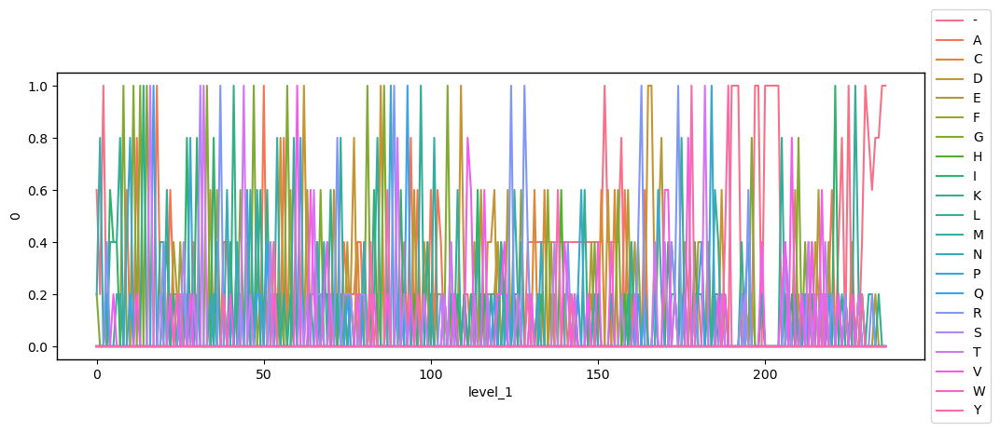

In [649]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.lineplot(data=temp_wide_norm, x='level_1', y=0, hue='level_0')
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))


<Axes: >

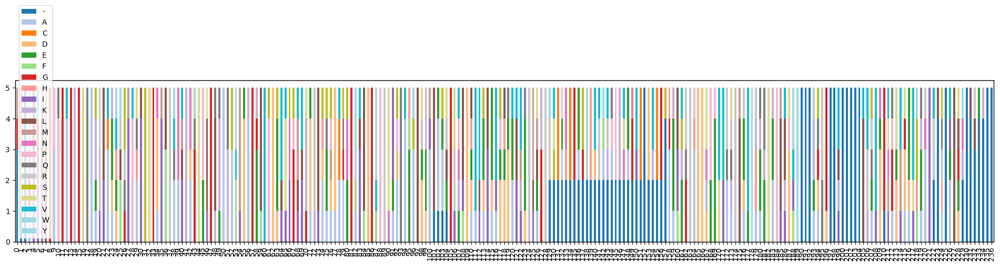

In [631]:
fig, ax = plt.subplots(figsize=(24, 4))
temp.apply(lambda row: row.value_counts(), axis=0).fillna(0).T.plot(kind='bar', stacked=True, colormap='tab20', ax=ax)

In [621]:
plotdf.head()

,protein,site,residue
0,0,0,-
1,0,1,M
2,0,2,-
3,0,3,N
4,0,4,I


In [ ]:
sns.barplot(data=plotdf, x=site, )

In [375]:
position_spearmans = []
for p in range(1, 200):
    a = f_full_metrics[f_full_metrics.Position.eq(p)].set_index('uid')['Contacts at 4.5 Å'].dropna()
    b = filtered.set_index('uid').reindex(a.index)['mean_temp']
    position_spearmans.append(spearmanr(a, b)[0])
    

<Axes: ylabel='Count'>

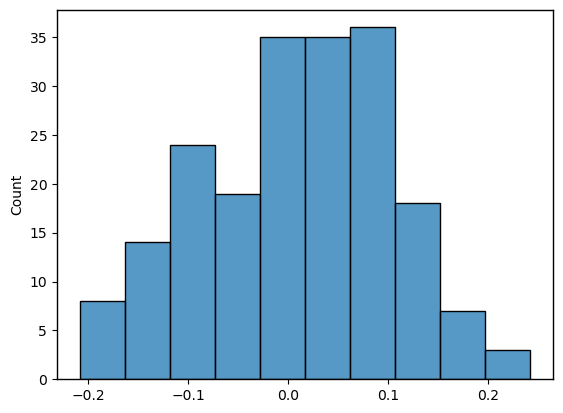

In [376]:
sns.histplot(position_spearmans)

In [377]:
test_metrics.head()

,Position,Contacts at 4.5 Å,SASA,uid,lid,residue
0,1,10,68.143124,GB_GCA_000376885.1,False,M
1,2,15,38.130233,GB_GCA_000376885.1,False,R
2,3,16,0.084949,GB_GCA_000376885.1,False,L
3,4,15,0.000000,GB_GCA_000376885.1,False,L
4,5,16,0.192095,GB_GCA_000376885.1,False,I


In [386]:
per_res = f_full_metrics.groupby(['uid', 'residue']).agg({'Contacts at 4.5 Å':'mean', 'SASA':'mean'})

In [393]:
per_res.loc[idx[:, r], 'SASA'].reset_index().set_index('uid')

,residue,SASA
uid,,
GB_GCA_000016765.1,A,50.440782
GB_GCA_000242235.1,A,40.140888
GB_GCA_000283575.1,A,32.731585
GB_GCA_000376885.1,A,35.466811
GB_GCA_000411155.1,A,38.941966
...,...,...
RS_GCF_905397275.1,A,39.891568
RS_GCF_905397435.1,A,43.047888
RS_GCF_907163105.1,A,26.575901


<Axes: xlabel='SASA', ylabel='mean_temp'>

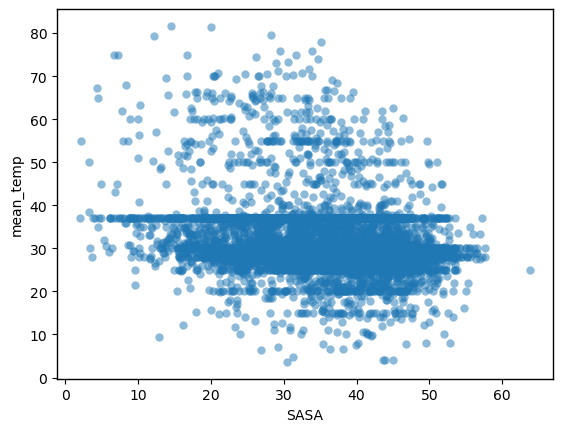

In [394]:
r = 'A'
sns.scatterplot(y = filtered.set_index('uid')['mean_temp'], x=per_res.loc[idx[:, r], :].reset_index().set_index('uid')['SASA'], linewidth=0, alpha=0.5)

In [399]:
residue_spearmans = []
residues = f_full_metrics['residue'].unique()
for r in residues:
    a = f_full_metrics[f_full_metrics.residue.eq(r)].groupby('uid').agg({'SASA':'mean'}).dropna()
    b = filtered.set_index('uid').reindex(a.index)['mean_temp']
    residue_spearmans.append(spearmanr(a, b)[0])

<Axes: ylabel='Count'>

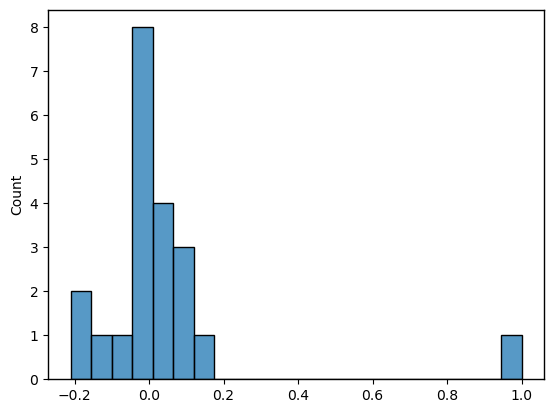

In [400]:
sns.histplot(residue_spearmans)

In [410]:
f_full_metrics.groupby(['Position', 'residue']).agg({'SASA':'mean'}).reset_index()

,Position,residue,SASA
0,1,M,80.105028
1,1,V,12.911883
2,2,A,44.162698
3,2,D,6.461265
4,2,E,57.987264
...,...,...,...
4585,261,S,16.254349
4586,262,A,71.992495
4587,263,A,25.913775
4588,264,L,11.148859


In [423]:
print(list(residues))

['M', 'R', 'L', 'I', 'G', 'P', 'Q', 'V', 'K', 'T', 'A', 'E', 'H', 'F', 'S', 'D', 'Y', 'N', 'W', 'C', 'X']


In [576]:
p_r_spearmans = []
index = []
counts = []
residues = f_full_metrics['residue'].unique()
for r in residues:
    print(r)
    for p in range(20, 180):
        display(r, p)
        clear_output(wait=True)
        a = f_full_metrics[f_full_metrics.residue.eq(r) & f_full_metrics.Position.eq(p)].set_index('uid')['Contacts at 4.5 Å'].dropna()
        b = filtered.set_index('uid').reindex(a.index)['mean_temp']
        p_r_spearmans.append(spearmanr(a, b)[0])
        counts.append(len(a))
        index.append((r, p))

'X'

179

<Axes: xlabel='R', ylabel='Count'>

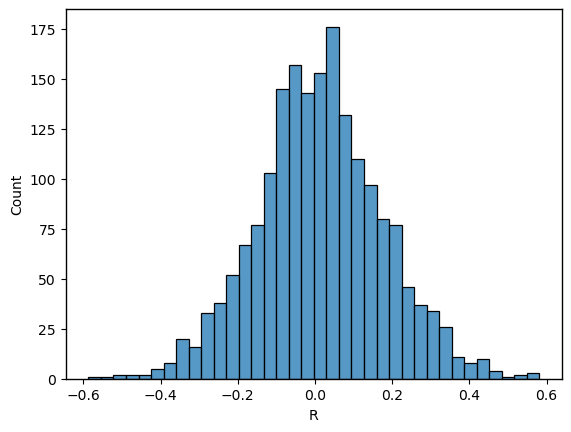

In [577]:
temp = pd.DataFrame(index=pd.MultiIndex.from_tuples(index), columns=['R', 'count'],
             data=np.transpose([p_r_spearmans, counts])).dropna()

sns.histplot(temp[temp['count'] > 100]['R'])

In [578]:
temp[temp['count'] > 100].sort_values('R')

,,R,count
H,169,-0.587171,152.0
M,112,-0.526147,133.0
L,62,-0.521194,115.0
K,59,-0.521164,116.0
I,92,-0.482924,119.0
...,...,...,...
A,124,0.517547,235.0
T,147,0.530206,216.0
S,92,0.553811,140.0
I,177,0.570365,305.0


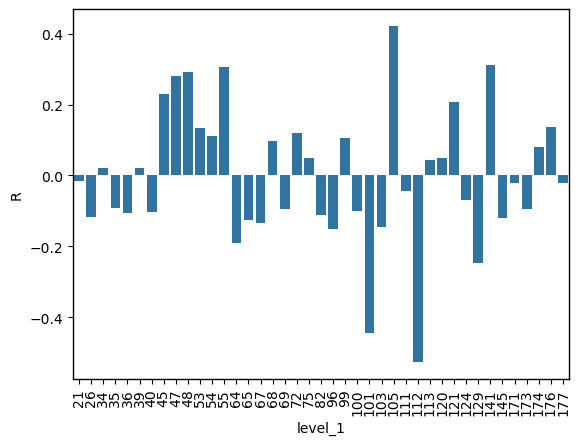

In [586]:
sns.barplot(data=temp[temp['count'] > 100].loc[idx['M', :], 'R'].reset_index(), y='R', x='level_1')
xticks = plt.xticks(rotation=90)

<Axes: xlabel='SASA', ylabel='mean_temp'>

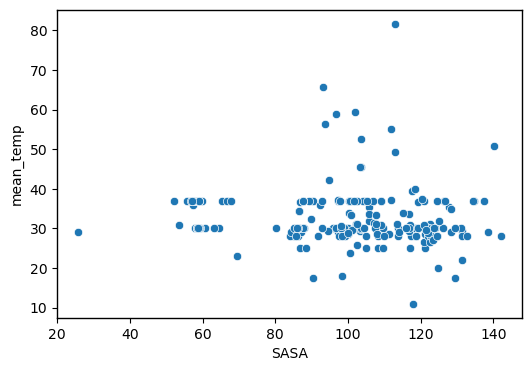

In [591]:
fig, ax = plt.subplots(figsize=(6,4))
sns.scatterplot(x=f_full_metrics.query('(`residue` == "M") & (`Position` == 47)').set_index('uid')['SASA'],
                y=filtered.set_index('uid')['mean_temp'])
# ax.set_xscale('log')

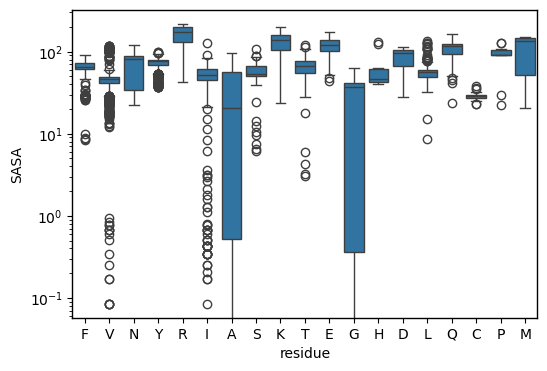

In [523]:
fig, ax = plt.subplots(figsize=(6,4))
sns.boxplot(data=f_full_metrics[f_full_metrics.Position.eq(52)], x='residue', y='SASA')
ax.set_yscale('log')

In [469]:
all_ids = f_full_metrics['uid'].unique()
train_ids, test_ids = train_test_split(train_ids, test_size=0.25)

In [500]:
temps = filtered.set_index('uid').mean_temp
y_train = f_full_metrics[f_full_metrics.uid.isin(train_ids)]['uid'].apply(lambda x: temps.loc[x])
y_test = f_full_metrics[f_full_metrics.uid.isin(test_ids)]['uid'].apply(lambda x: temps.loc[x])

In [502]:
X_train = pd.concat([f_full_metrics[f_full_metrics.uid.isin(train_ids)][['Position', 'Contacts at 4.5 Å', 'SASA']],
                     f_full_metrics[f_full_metrics.uid.isin(train_ids)]['residue'].str.get_dummies()], axis=1)

X_test = pd.concat([f_full_metrics[f_full_metrics.uid.isin(test_ids)][['Position', 'Contacts at 4.5 Å', 'SASA']],
                     f_full_metrics[f_full_metrics.uid.isin(test_ids)]['residue'].str.get_dummies()], axis=1)
# X_train['residue'] = X_train['residue'].astype('category') 
# X_train['lid'] = X_train['residue'].astype(int) 
X_train.head()

,Position,Contacts at 4.5 Å,SASA,A,C,D,E,F,G,H,...,N,P,Q,R,S,T,V,W,X,Y
0,1,10,68.143124,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,15,38.130233,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
2,3,16,0.084949,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,15,0.000000,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,16,0.192095,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [503]:
random_state = 5
model = RandomForestRegressor(random_state=random_state, n_estimators=1000,
                      n_jobs=24)

In [504]:
model.fit(X_train, y_train)

RandomForestRegressor(n_estimators=1000, n_jobs=24, random_state=5)

In [505]:
sa_test_score=root_mean_squared_error(y_test, model.predict(X_test))

In [506]:
sa_test_score

7.628974227337481

In [508]:
pred = model.predict(X_test)

<Axes: xlabel='uid'>

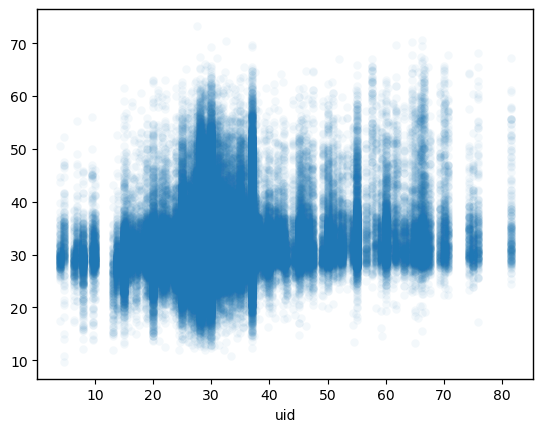

In [511]:
sns.scatterplot(x=y_test, y=pred, linewidth=0, alpha=0.05)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(df[metrics_to_plot + additional_metrics + ['seq_length'] > 200], df['mean_temp'], test_size=0.1)

# computing the score on the test set
random_state = 5
model = RandomForestRegressor(random_state=random_state, n_estimators=5000,
                      n_jobs=24)

# model = RandomForestRegressor(random_state=random_state, n_estimators=best['n_estimators'],
#                       max_depth=best['max_depth']+5, min_samples_leaf=best['min_samples_leaf']+1,
#                       min_samples_split=best['min_samples_split']+1,
#                       n_jobs=20)

model.fit(X_train, y_train)
sa_test_score=root_mean_squared_error(y_test, model.predict(X_test))


In [388]:
per_res.loc[idx[:, r], 'SASA']

uid                 residue
GB_GCA_000016765.1  A          50.440782
GB_GCA_000242235.1  A          40.140888
GB_GCA_000283575.1  A          32.731585
GB_GCA_000376885.1  A          35.466811
GB_GCA_000411155.1  A          38.941966
                                 ...    
RS_GCF_905397275.1  A          39.891568
RS_GCF_905397435.1  A          43.047888
RS_GCF_907163105.1  A          26.575901
RS_GCF_907163265.1  A          48.946467
RS_GCF_910593845.1  A          33.908722
Name: SASA, Length: 8532, dtype: float64

In [371]:
# save table
test_metrics.to_csv('/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/metric_tables/20240528_full_metrics_lid.tsv.gz')

In [250]:
nolid_metrics = test_metrics.groupby(['uid', 'lid']).mean().loc[idx[:, False], :].reset_index().set_index('uid')

In [248]:
filtered

,Unnamed: 0,Position,Contacts at 4.5 Å,SASA,uid,total_score,avg_deg_4_5,avg_deg_8,avg_sc_nbrs_res_summary,bb_internal_hbonds,...,temp,mean_temp,seq_length,bitscore,C,L,N,P,max_structure_length,lid_bitscore
0,0,94.0,11.358289,52.616491,GB_GCA_000376885.1,-454.076,1.278,10.765,2.648,124.0,...,37.0,37.00,187,178.2,90.0,48.0,42.0,6.0,24,0.0
1,1,108.0,11.125581,49.464040,GB_GCA_000016765.1,-450.126,1.316,10.730,2.697,132.0,...,30.0,30.00,215,175.3,116.0,49.0,43.0,6.0,23,52.3
2,2,119.5,11.289720,49.538232,GB_GCA_000242235.1,-419.604,1.327,10.981,2.842,128.0,...,37.0,37.00,214,192.2,117.0,48.0,42.0,6.0,24,59.2
3,3,105.5,11.276190,50.018080,GB_GCA_000283575.1,-452.738,1.390,10.905,2.771,129.0,...,30.0,30.00,210,168.7,112.0,48.0,43.0,6.0,24,58.3
4,4,91.0,11.359116,51.483049,GB_GCA_001054945.1,-431.800,1.243,10.768,2.669,117.0,...,37.0,37.00,181,192.9,88.0,44.0,42.0,6.0,21,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8527,9336,111.0,11.257919,49.134618,RS_GCF_905397275.1,-492.694,1.353,10.846,2.780,130.0,...,30.0,28.75,221,195.8,123.0,48.0,43.0,6.0,28,61.7
8528,9337,99.0,11.502591,51.214600,RS_GCF_907163105.1,-494.248,1.290,11.031,2.738,128.0,...,30.0,33.50,193,165.6,122.0,22.0,42.0,6.0,24,0.0
8529,9338,111.0,11.366516,49.484025,RS_GCF_905397435.1,-469.955,1.362,10.810,2.811,133.0,...,27.0,26.40,221,194.9,123.0,48.0,43.0,6.0,28,61.6
8530,9339,108.0,11.479070,49.243296,RS_GCF_910593845.1,-487.960,1.288,10.833,2.731,133.0,...,30.0,29.50,215,190.8,118.0,48.0,42.0,6.0,24,66.3


<Axes: xlabel='SASA', ylabel='SASA'>

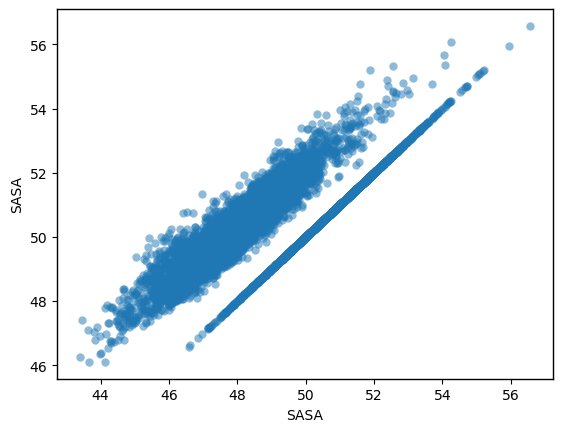

In [253]:
sns.scatterplot(y = filtered.set_index('uid')['SASA'], x=nolid_metrics['SASA'], linewidth=0, alpha=0.5)

# Deep imbalanced regression

In [228]:
sys.path.append('/data/mhoffert/tools/imbalanced-regression/imdb-wiki-dir/')

from collections import Counter
from scipy.ndimage import convolve1d
from imb_utils import get_lds_kernel_window

ModuleNotFoundError: No module named 'torch'

In [ ]:

# preds, labels: [Ns,], "Ns" is the number of total samples
preds, labels = ..., ...
# assign each label to its corresponding bin (start from 0)
# with your defined get_bin_idx(), return bin_index_per_label: [Ns,] 
bin_index_per_label = [get_bin_idx(label) for label in labels]

# calculate empirical (original) label distribution: [Nb,]
# "Nb" is the number of bins
Nb = max(bin_index_per_label) + 1
num_samples_of_bins = dict(Counter(bin_index_per_label))
emp_label_dist = [num_samples_of_bins.get(i, 0) for i in range(Nb)]

# lds_kernel_window: [ks,], here for example, we use gaussian, ks=5, sigma=2
lds_kernel_window = get_lds_kernel_window(kernel='gaussian', ks=5, sigma=2)
# calculate effective label distribution: [Nb,]
eff_label_dist = convolve1d(np.array(emp_label_dist), weights=lds_kernel_window, mode='constant')

# Blah code

## Leveraged point calculation test

In [120]:
from scipy.stats import linregress

In [121]:
Rs = pd.Series()

In [122]:
# detecting leveraged points
import statsmodels.api as sm

https://sabarevictor.medium.com/exploring-outliers-leverage-and-influence-33879dbbba9a

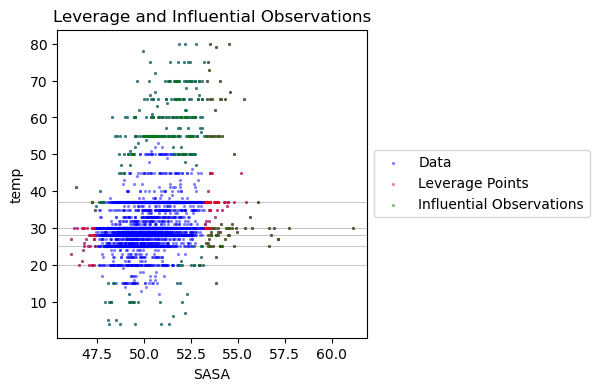

In [162]:
fig, ax = plt.subplots(figsize=(4,4))
xval = 'SASA'
yval = 'temp'
x = filtered.query('seq_length > 200')[xval].values
y = filtered.query('seq_length > 200')[yval].values
model = sm.OLS(y, sm.add_constant(x)).fit()
leverage = model.get_influence().hat_matrix_diag

# Calculate leverage statistics
leverage = model.get_influence().hat_matrix_diag

# Calculate Cook's distance
cook_distance = model.get_influence().cooks_distance[0]

# Identify leverage points
leverage_points = np.where(leverage > np.mean(leverage) + 2 * np.std(leverage))

# Identify influential observations based on Cook's distance
influential_observations = np.where(cook_distance > 4 / len(x))

# Plot leverage and influential observations using seaborn
plotargs = {'linewidth':0,'s':5,'alpha':0.5}
sns.scatterplot(x=x, y=y, color='blue', label='Data', **plotargs)
sns.scatterplot(x=x[leverage_points], y=y[leverage_points], color='red', label='Leverage Points', **plotargs)
sns.scatterplot(x=x[influential_observations], y=y[influential_observations], color='green', label='Influential Observations', **plotargs)
# sns.regplot(x=x, y=y, scatter=False, color='black', label='Regression Line')

# Add labels and title to the plot
# sns.set_style('whitegrid')
sns.set_palette('bright')
plt.xlabel(xval)
plt.ylabel(yval)
plt.title('Leverage and Influential Observations')
lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
for i in [37, 30, 28, 25, 20]:
    ax.axhline(i, color='gray', alpha=0.65, linewidth=0.5, zorder=0)
# Show the plot
plt.show()

## Structure plotting code

In [18]:
import IPython

In [19]:
%%javascript
IPython.OutputArea.prototype._should_scroll = function(lines) {
    return false;
}

<IPython.core.display.Javascript object>

### Example

In [20]:
from adk_drawer import get_guiding_structures, ss_to_domains, draw_adk

In [21]:
ss_cmap = {'H':'red', 'E':'blue', 'L':'gray'}
domain_cmap = {'core':'red', 'lid':'blue', 'nmp':'green', 'none':'gray', 'ploop':'yellow'}
nglview_list = lambda cmap, residue_ss: [[cmap[r], str(i)] for i, r in enumerate(residue_ss)]

test_file = 'GB_GCA_000016765.1_closed.pdb'
genome = test_file.split('_closed')[0]
struct_path = '/data/mhoffert/fiererlab/adenylate_kinase_ogt/data/test_structures/'

draw_adk(f'{struct_path}{test_file}', color_domains=domain_cmap, ss=secondary_structure.loc[genome])

NGLWidget()

## Test whether 37 C points don't match other observations

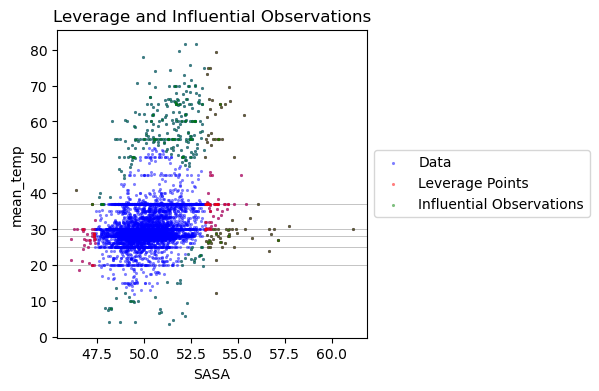

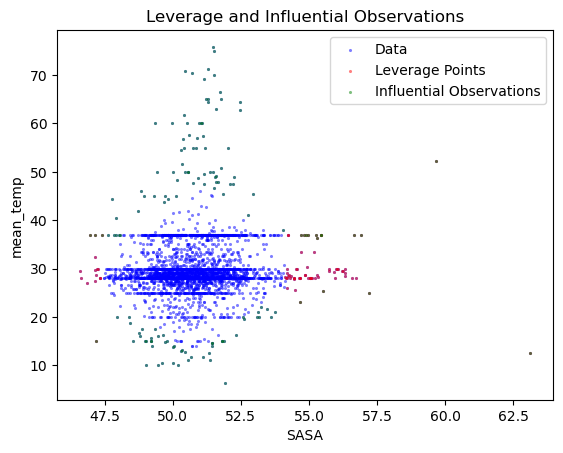

In [150]:
fig, ax = plt.subplots(figsize=(4,4))
xval = 'SASA'
yval = 'mean_temp'
for qstr in ['seq_length > 200', 'seq_length < 200']:
    x = filtered.query(qstr)[xval].values
    y = filtered.query(qstr)[yval].values
    model = sm.OLS(y, sm.add_constant(x)).fit()
    leverage = model.get_influence().hat_matrix_diag
    
    # Calculate leverage statistics
    leverage = model.get_influence().hat_matrix_diag
    
    # Calculate Cook's distance
    cook_distance = model.get_influence().cooks_distance[0]
    
    # Identify leverage points
    leverage_points = np.where(leverage > np.mean(leverage) + 2 * np.std(leverage))
    
    # Identify influential observations based on Cook's distance
    influential_observations = np.where(cook_distance > 4 / len(x))
    
    # Plot leverage and influential observations using seaborn
    plotargs = {'linewidth':0,'s':5,'alpha':0.5}
    sns.scatterplot(x=x, y=y, color='blue', label='Data', **plotargs)
    sns.scatterplot(x=x[leverage_points], y=y[leverage_points], color='red', label='Leverage Points', **plotargs)
    sns.scatterplot(x=x[influential_observations], y=y[influential_observations], color='green', label='Influential Observations', **plotargs)
    # sns.regplot(x=x, y=y, scatter=False, color='black', label='Regression Line')
    
    # Add labels and title to the plot
    # sns.set_style('whitegrid')
    sns.set_palette('bright')
    plt.xlabel(xval)
    plt.ylabel(yval)
    plt.title('Leverage and Influential Observations')
    lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    for i in [37, 30, 28, 25, 20]:
        ax.axhline(i, color='gray', alpha=0.65, linewidth=0.5, zorder=0)
    # Show the plot
    plt.show()

In [151]:
print('Leverage points', len(leverage_points[0]))
print('Influential Obs', len(influential_observations[0]))

Leverage points 78
Influential Obs 142


In [152]:
def identify_leveraged(x, y):
    model = sm.OLS(y.values, sm.add_constant(x.values)).fit()
    leverage = model.get_influence().hat_matrix_diag

    # Calculate leverage statistics
    leverage = model.get_influence().hat_matrix_diag

    # Calculate Cook's distance
    cook_distance = model.get_influence().cooks_distance[0]

    # Identify leverage points
    leverage_points = np.where(leverage > np.mean(leverage) + 2 * np.std(leverage))

    return x.iloc[leverage_points].index

### Testing leveraged point removal and new resampling method

3470


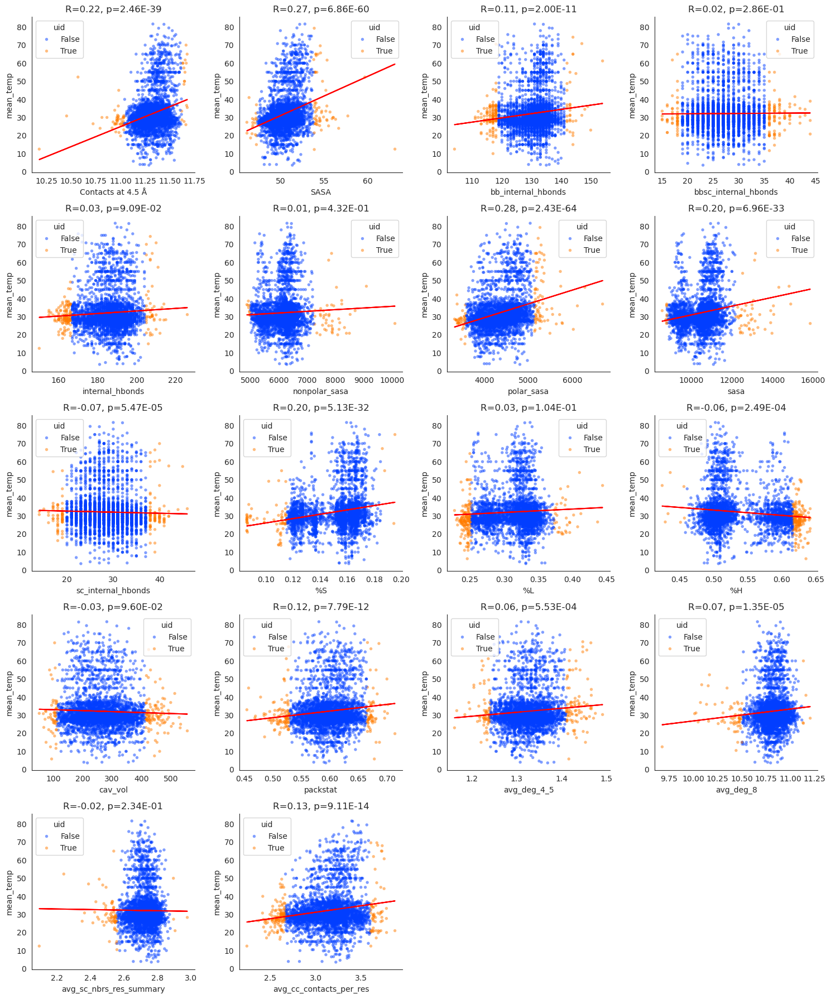

In [274]:
# first, plotting after filtering
fig = plt.figure(figsize=(15, 18))
# filtered['group'] = pd.cut(filtered['mean_temp'], np.linspace(0, 100, 101))
# resampled = filtered.groupby('group', observed=True).apply(lambda x: x.sample(np.min([50, len(x)]), replace=False))
resampled = filtered.groupby('mean_temp').apply(lambda x: x.sample(np.min([50, len(x)]))).reset_index(drop=True)
print(len(resampled))
for i, metric in enumerate(metrics_to_plot):
    ax = fig.add_subplot(5,4,i+1)
    leveraged = identify_leveraged(resampled.set_index('uid')[metric], resampled.set_index('uid')['mean_temp'])
    sns.scatterplot(data=resampled, x=metric, y='mean_temp', edgecolor=None, 
                    hue=resampled.uid.isin(leveraged), s=15,
                    linewidth=0, alpha=0.5
                   )
    reg = linregress(y=resampled['mean_temp'], x=resampled[metric])
    plt.plot(resampled[metric], reg.intercept + reg.slope * resampled[metric], 'r', label='fitted line')
    spR_result = spearmanr(resampled[metric], resampled['mean_temp'])
    ax.set_title(f'R={spR_result[0]:.02f}, p={spR_result[1]:.02E}')
    Rs.loc[metric] = spR_result[0]
    # ax.get_legend().remove()
    # lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), title='filtered')

sns.despine(fig)
plt.tight_layout()

#### Notes
We're going to go ahead with the leveraged point removal for now

8896
8671
4227
634


/tmp/ipykernel_2358711/2569337196.py:46: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  resampled['group'] = pd.cut(resampled['mean_temp'], np.linspace(0, 100, 21))


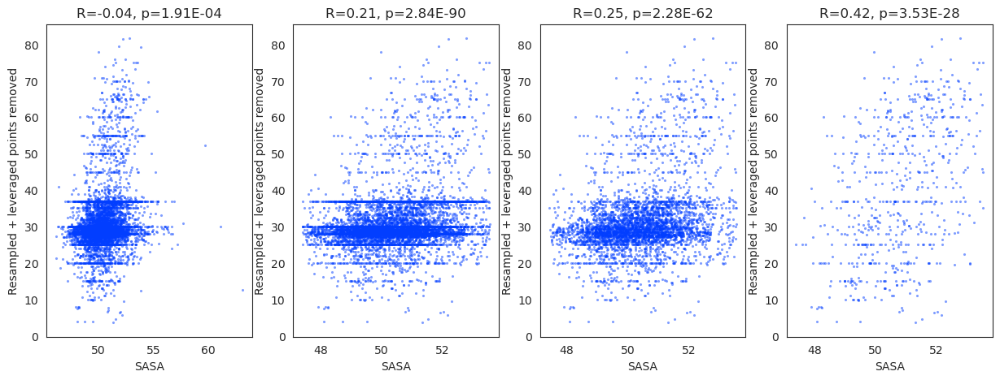

In [330]:
test_dataframes = []

# new correlations
fig = plt.figure(figsize=(15,5))
ax = fig.add_subplot(1,4,1)
sns.scatterplot(data=filtered, x='SASA', y='mean_temp', linewidth=0, alpha=0.5, s=5)
ax.set_ylabel('Resampled + leveraged points removed')
ax.set_xlabel('SASA')
spR_result = spearmanr(filtered[metric], filtered['mean_temp'])
ax.set_title(f'R={spR_result[0]:.02f}, p={spR_result[1]:.02E}')
print(len(filtered))
test_dataframes.append(filtered)
# ax.set_title('all points')

leveraged = identify_leveraged(filtered.set_index('uid')['SASA'], filtered.set_index('uid')['mean_temp'])
resampled = filtered[~filtered.uid.isin(leveraged)]

ax = fig.add_subplot(1,4,2)
sns.scatterplot(data=resampled, x='SASA', y='mean_temp', linewidth=0, alpha=0.5, s=5)
spR_result = spearmanr(resampled['SASA'], resampled['mean_temp'])
ax.set_title(f'R={spR_result[0]:.02f}, p={spR_result[1]:.02E}')
ax.set_ylabel('Resampled + leveraged points removed')
ax.set_xlabel('SASA')
print(len(resampled))
test_dataframes.append(resampled)
# ax.set_title('leveraged points removed')


leveraged = identify_leveraged(filtered.set_index('uid')['SASA'], filtered.set_index('uid')['mean_temp'])
resampled = filtered[~filtered.uid.isin(leveraged)]

resampled = resampled.groupby('mean_temp').apply(lambda x: x.sample(np.min([100, len(x)]))).reset_index(drop=True)

ax = fig.add_subplot(1,4,3)
sns.scatterplot(data=resampled, x='SASA', y='mean_temp', linewidth=0, alpha=0.5, s=5)
spR_result = spearmanr(resampled['SASA'], resampled['mean_temp'])
ax.set_title(f'R={spR_result[0]:.02f}, p={spR_result[1]:.02E}')
ax.set_ylabel('Resampled + leveraged points removed')
ax.set_xlabel('SASA')
print(len(resampled))
test_dataframes.append(resampled)
# ax.set_title('Resampled + leveraged points removed')

leveraged = identify_leveraged(filtered.set_index('uid')['SASA'], filtered.set_index('uid')['mean_temp'])
resampled = filtered[~filtered.uid.isin(leveraged)]
resampled['group'] = pd.cut(resampled['mean_temp'], np.linspace(0, 100, 21))
resampled = resampled.groupby('group', observed=True).apply(lambda x: x.sample(np.min([50, len(x)]), replace=False))

ax = fig.add_subplot(1,4,4)
sns.scatterplot(data=resampled, x='SASA', y='mean_temp', linewidth=0, alpha=0.5, s=5)
spR_result = spearmanr(resampled['SASA'], resampled['mean_temp'])
ax.set_title(f'R={spR_result[0]:.02f}, p={spR_result[1]:.02E}')
ax.set_ylabel('Resampled + leveraged points removed')
ax.set_xlabel('SASA')
print(len(resampled))
test_dataframes.append(resampled)


3394
3407
3373
3381
3385
3426
3383
3423
3375
3425
3339
3358
3358
3358
3352
3413
3415
3333


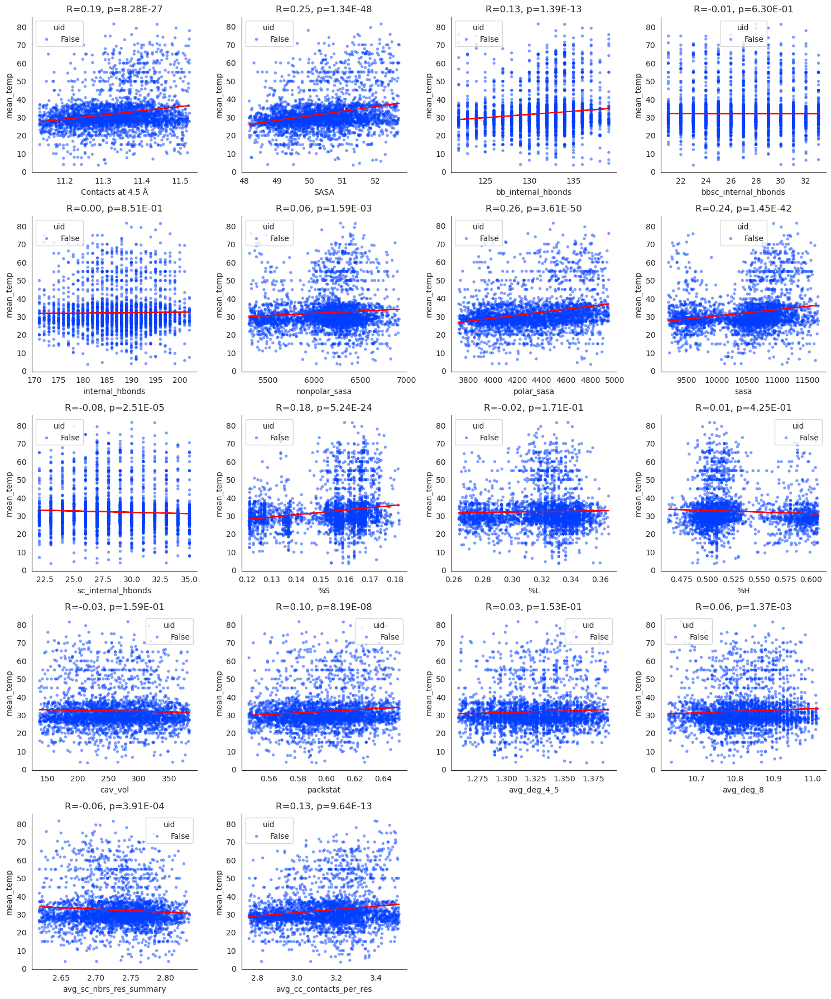

In [313]:
# first, plotting after filtering
fig = plt.figure(figsize=(15, 18))
# filtered['group'] = pd.cut(filtered['mean_temp'], np.linspace(0, 100, 101))
# resampled = filtered.groupby('group', observed=True).apply(lambda x: x.sample(np.min([50, len(x)]), replace=False))

for i, metric in enumerate(metrics_to_plot):
    ax = fig.add_subplot(5,4,i+1)
    leveraged = identify_leveraged(filtered.set_index('uid')[metric], filtered.set_index('uid')['mean_temp'])
    resampled = filtered[~filtered.uid.isin(leveraged)]
    
    
    resampled = resampled.groupby('mean_temp').apply(lambda x: x.sample(np.min([50, len(x)]))).reset_index(drop=True)
    print(len(resampled))
    leveraged = identify_leveraged(resampled.set_index('uid')[metric], resampled.set_index('uid')['mean_temp'])
    resampled = resampled[~resampled.uid.isin(leveraged)]
    sns.scatterplot(data=resampled, x=metric, y='mean_temp', edgecolor=None, 
                    hue=resampled.uid.isin(leveraged), s=15,
                    linewidth=0, alpha=0.5
                   )
    reg = linregress(y=resampled['mean_temp'], x=resampled[metric])
    plt.plot(resampled[metric], reg.intercept + reg.slope * resampled[metric], 'r', label='fitted line')
    spR_result = spearmanr(resampled[metric], resampled['mean_temp'])
    ax.set_title(f'R={spR_result[0]:.02f}, p={spR_result[1]:.02E}')
    Rs.loc[metric] = spR_result[0]
    # ax.get_legend().remove()
    # lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), title='filtered')

sns.despine(fig)
plt.tight_layout()

3470
3470
3470
3470
3470
3470
3470
3470
3470
3470
3470
3470
3470
3470
3470
3470
3470
3470
3470


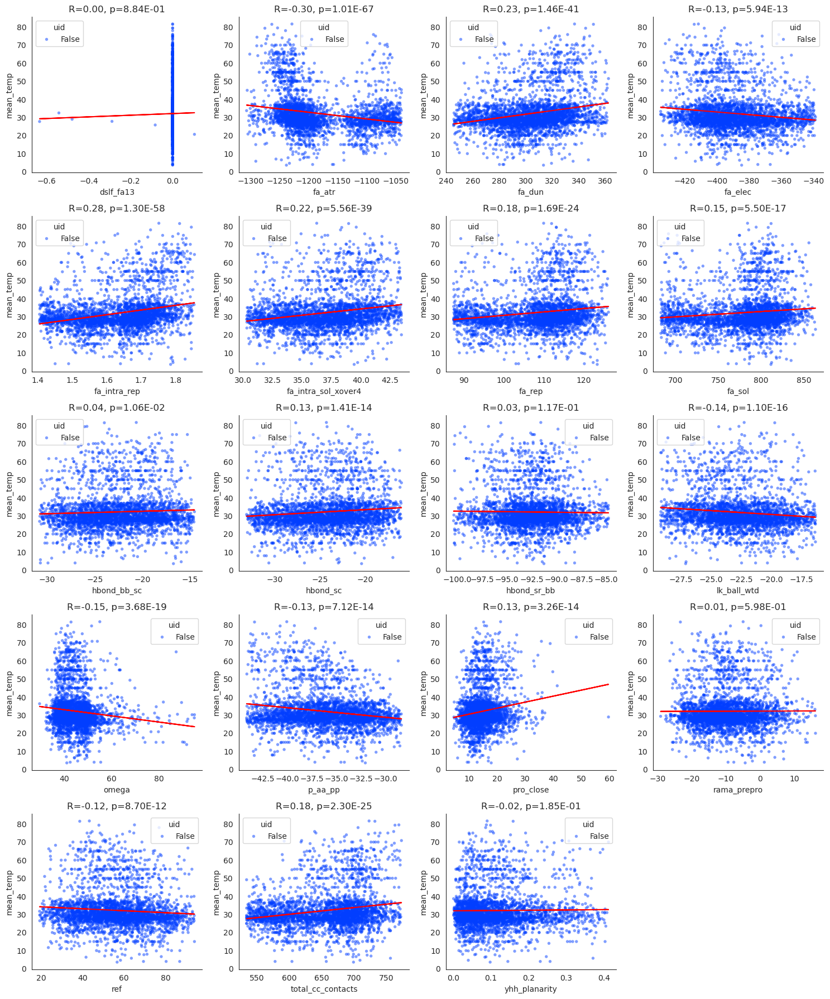

In [321]:
# first, plotting after filtering
fig = plt.figure(figsize=(15, 18))
# filtered = filter_data(metrics_df, filters).copy(deep=True)
# filtered['group'] = pd.cut(metrics_df['temp'], np.linspace(0, 100, 21))
# resampled = filtered.groupby('group', observed=True).apply(lambda x: x.sample(np.min([50, len(x)]), replace=False))
for i, metric in enumerate(additional_metrics):
    ax = fig.add_subplot(5,4,i+1)
    resampled = filtered.groupby('mean_temp').apply(lambda x: x.sample(np.min([50, len(x)]))).reset_index(drop=True)
    print(len(resampled))
    leveraged = identify_leveraged(resampled.set_index('uid')[metric], resampled.set_index('uid')['mean_temp'])
    resampled = resampled[~resampled.uid.isin(leveraged)]
    sns.scatterplot(data=resampled, x=metric, y='mean_temp', edgecolor=None, 
                    hue=resampled.uid.isin(leveraged), s=15,
                    linewidth=0, alpha=0.5
                   )
    reg = linregress(y=resampled['mean_temp'], x=resampled[metric])
    plt.plot(resampled[metric], reg.intercept + reg.slope * resampled[metric], 'r', label='fitted line')
    spR_result = spearmanr(resampled[metric], resampled['mean_temp'])
    ax.set_title(f'R={spR_result[0]:.02f}, p={spR_result[1]:.02E}')
    Rs.loc[metric] = spR_result[0]
    # ax.get_legend().remove()
    # lgd = ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), title='filtered')

sns.despine(fig)
plt.tight_layout()

# Machine learning component

In [466]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_squared_error, make_scorer, root_mean_squared_error
from hyperopt import fmin, tpe, hp, Trials, STATUS_OK
# from hyperopt.fmin import fmin

In [467]:
from scipy.stats import pearsonr

### Simple model test

In [524]:
df

,value,category
0,1,A
1,2,A
2,3,B
3,4,B
4,5,A
5,6,B
6,7,A
7,8,B
8,9,A
9,10,B


In [526]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [564]:
fig = plt.figure(figsize=(4,4))

df = filtered.copy(deep=True) #.query('seq_length > 200').copy(deep=True)
print(df.shape)

X_train, X_test, y_train, y_test = train_test_split(df[metrics_to_plot + additional_metrics + ['seq_length']], df['mean_temp'], test_size=0.1)


random_state = 5
pipe = make_pipeline(StandardScaler(), RandomForestRegressor(random_state=random_state, 
                                                n_estimators=5000,
                                                  n_jobs=24,
                                                  max_features='sqrt'))


pipe.fit(X_train, y_train)
# sa_test_score=root_mean_squared_error(y_test, model.predict(X_test))
pipe.score(X_test, y_test)

# choices = np.random.choice(list(range(len(filtered))), size=int(len(filtered) * 0.9), replace=False)
# model.fit(filtered.iloc[choices, :][metrics_to_plot + additional_metrics].values, filtered.iloc[choices, :]['temp'])
# not_choices = [i for i in list(range(len(filtered))) if not i in choices]
# sa_test_score=root_mean_squared_error(filtered.iloc[not_choices, :]['temp'], model.predict(filtered.iloc[not_choices, :][metrics_to_plot + additional_metrics].values))

(8532, 53)


0.43672911143310467

<Figure size 400x400 with 0 Axes>

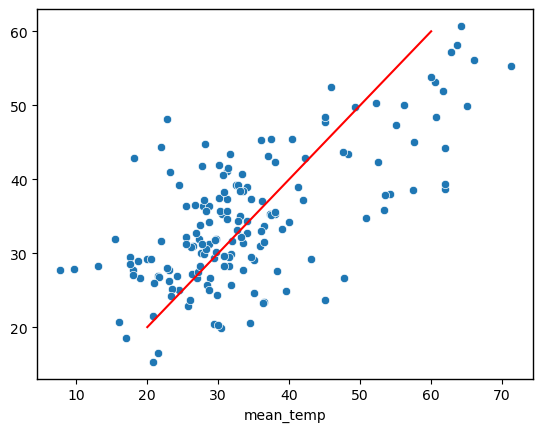

In [571]:
sns.scatterplot(y=pipe.predict(X_test), x=y_test)
plt.plot((20, 60), (20, 60), color='red')

In [549]:
plotdf = filtered[['mean_temp', 'SASA']]
plotdf['group'] = pd.cut(plotdf['mean_temp'], np.linspace(3, 83, 41))
groups = sorted(list(plotdf['group'].unique()))
plotdf['group_ind'] = plotdf['group'].apply(lambda x: groups.index(x)).astype(int)

In [550]:
print(plotdf['group_ind'].unique())
plotdf.head()

[16 13 15 ...  4 36 37]


,mean_temp,SASA,group,group_ind
0,37.0,52.616491,"(35.0, 37.0]",16
1,30.0,49.464040,"(29.0, 31.0]",13
2,37.0,49.538232,"(35.0, 37.0]",16
3,30.0,50.018080,"(29.0, 31.0]",13
4,37.0,51.483049,"(35.0, 37.0]",16


<Axes: xlabel='SASA', ylabel='group'>

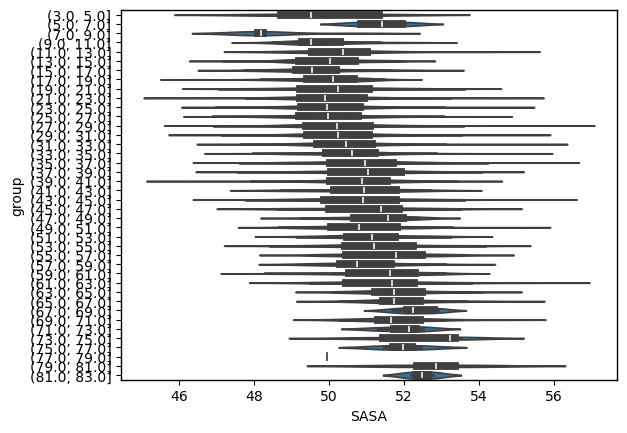

In [559]:
sns.violinplot(data=plotdf, x='SASA', y='group')

In [54]:
pearsonr(y_test, model.predict(X_test))

PearsonRResult(statistic=0.6750216313641556, pvalue=2.08326531586553e-72)

### GLMNet

In [567]:
from glmnet import ElasticNet

1000
(7960, 53)
100
(4173, 53)
50
(3374, 53)
10
(1638, 53)


Text(0.5, 0.98, 'GLMNet performance')

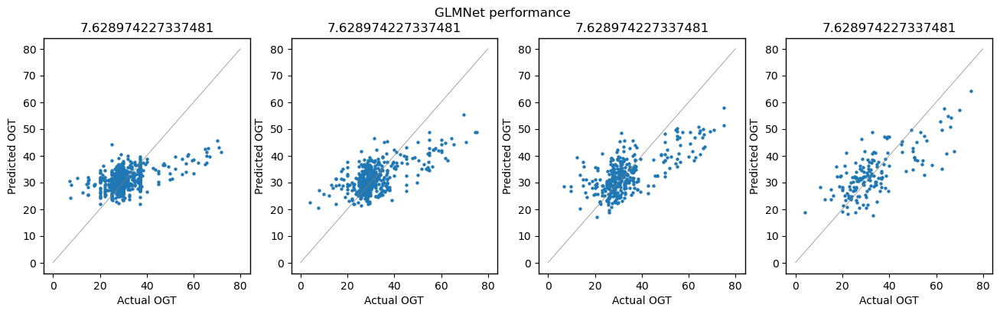

In [575]:
fig = plt.figure(figsize=(16,4))
for i, sf in enumerate([1000, 100, 50, 10]):
    
    print(sf)
    resampled = filtered.groupby('mean_temp').apply(lambda x: x.sample(np.min([sf, len(x)]))).reset_index(drop=True)
    print(resampled.shape)
    # resampled['class'] = (resampled['seq_length'] > 200).astype(int)
    X_train, X_test, y_train, y_test = train_test_split(resampled[metrics_to_plot + additional_metrics + ['seq_length']], resampled['mean_temp'], test_size=0.1)
    
    # model = RandomForestRegressor(random_state=random_state, n_estimators=best['n_estimators'],
    #                       max_depth=best['max_depth']+5, min_samples_leaf=best['min_samples_leaf']+1,
    #                       min_samples_split=best['min_samples_split']+1,
    #                       n_jobs=20)
    
    m = ElasticNet()
    m = m.fit(X_train, y_train)

    # pipe = make_pipeline(StandardScaler(), ElasticNet())


    # pipe.fit(X_train, y_train)
    # # sa_test_score=root_mean_squared_error(y_test, model.predict(X_test))
    # print(pipe.score(X_test, y_test))

    ax = fig.add_subplot(1,4,i+1)

    # p = m.predict(x)
    # sa_test_score=root_mean_squared_error(y_test, m.predict(X_test))
    
    
    ax.set_title(sa_test_score)
    ax.set_xlabel('Actual OGT')
    ax.set_ylabel('Predicted OGT')
    sns.scatterplot(x=y_test, y=m.predict(X_test), linewidth=0, s=10)
    plt.plot((0,80), (0, 80), linewidth=0.5, color='gray')
fig.suptitle('GLMNet performance')

In [47]:
spearmanr(y_test, m.predict(X_test))

SignificanceResult(statistic=0.5348787860547692, pvalue=1.6096780869842848e-13)

<Axes: xlabel='mean_temp', ylabel='Count'>

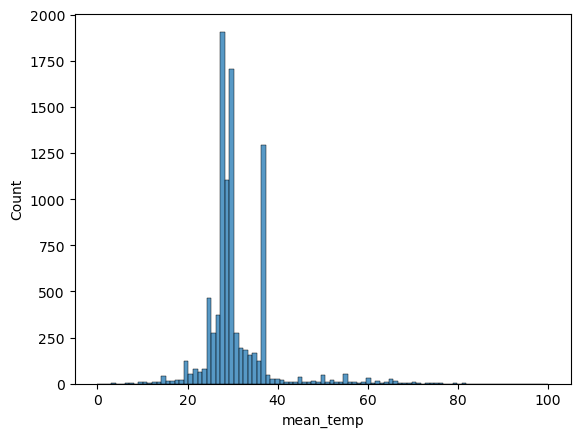

In [49]:
sns.histplot(metrics_df['mean_temp'], bins=np.linspace(0, 100, 100))

In [788]:
metrics_df['temp'].value_counts()

temp
28.0    1348
30.0    1188
37.0     923
25.0     413
29.0     280
        ... 
66.0       1
72.0       1
61.0       1
56.0       1
44.0       1
Name: count, Length: 61, dtype: int64

In [820]:
metrics_df['temp'].eq(4).sum()

5

### Parameter optimization with hyperopt

In [652]:
seed=2
def objective(params):
    est=int(params['n_estimators'])
    md=int(params['max_depth'])
    msl=int(params['min_samples_leaf'])
    mss=int(params['min_samples_split'])
    model=RandomForestRegressor(n_estimators=est,
                                max_depth=md,
                                min_samples_leaf=msl,
                                min_samples_split=mss,
                                n_jobs=24)
    model.fit(X_train, y_train)
    # pred=model.predict(X_test)
    losses = cross_val_score(model, X_train, y_train, cv=5, scoring="neg_mean_squared_error", n_jobs=4)
    return {'status': STATUS_OK,
            'loss':np.mean(losses),
            'loss_variance': np.var(losses, ddof=1)}

def optimize(trial):
    params={'n_estimators':hp.choice('n_estimators',[100, 500, 3000]),
           'max_depth':hp.choice('max_depth',[1, 5, 10, 25]),
           'min_samples_leaf':hp.choice('min_samples_leaf',[1, 2, 5, 10]),
           'min_samples_split':hp.choice('min_samples_split',[2, 5, 10])}
    best=fmin(fn=objective, space=params, algo=tpe.suggest, trials=trial, max_evals=10, rstate=np.random.default_rng(seed))
    return best


In [653]:
trial = Trials()
best = optimize(trial)

100%|██████████████████████████████████████████████████████████████████████████████████| 10/10 [05:58<00:00, 35.87s/trial, best loss: -60.027558974275884]


In [654]:
trial.results

[{'status': 'ok',
  'loss': -59.98623361539347,
  'loss_variance': 29.001923234804764},
 {'status': 'ok',
  'loss': -38.723660936959504,
  'loss_variance': 5.9113694487135255},
 {'status': 'ok',
  'loss': -39.57728387038338,
  'loss_variance': 7.343209845766388},
 {'status': 'ok',
  'loss': -38.544351824309054,
  'loss_variance': 7.616264141380216},
 {'status': 'ok',
  'loss': -45.15542615943298,
  'loss_variance': 6.369651589056865},
 {'status': 'ok',
  'loss': -39.7771140505797,
  'loss_variance': 7.3131293914681486},
 {'status': 'ok',
  'loss': -40.10509696079102,
  'loss_variance': 7.118772450258984},
 {'status': 'ok',
  'loss': -45.62372669613185,
  'loss_variance': 5.702546644886876},
 {'status': 'ok',
  'loss': -60.027558974275884,
  'loss_variance': 28.959370009960544},
 {'status': 'ok',
  'loss': -39.54889308058847,
  'loss_variance': 7.135236462594127}]

array([<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >], dtype=object)

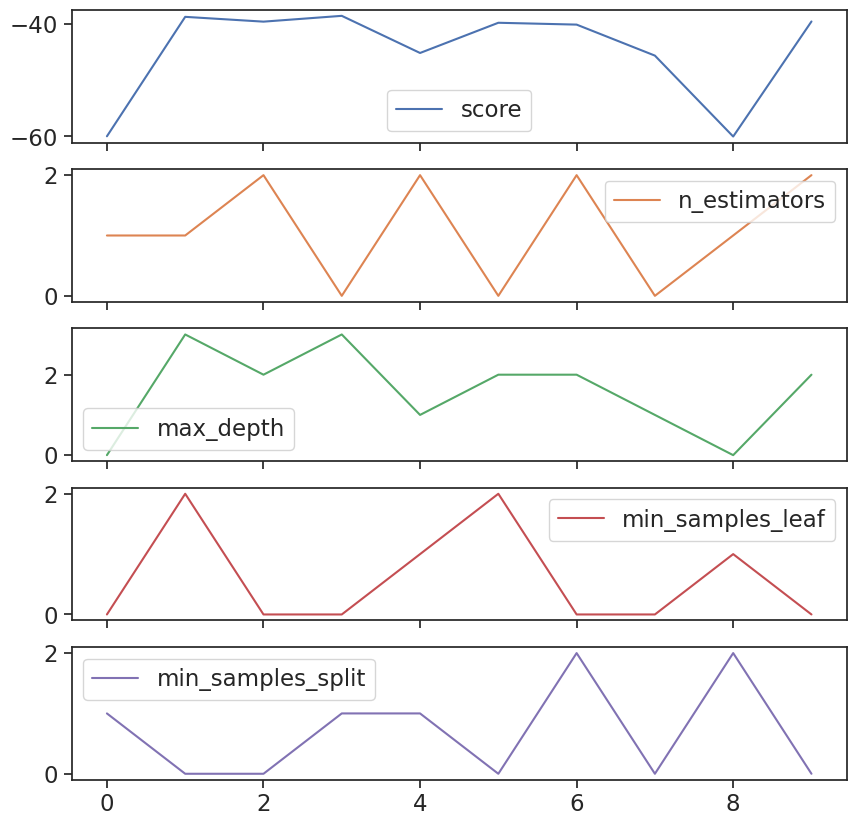

In [655]:
tpe_results=np.array([[x['result']['loss'],
                      x['misc']['vals']['n_estimators'][0],
                      x['misc']['vals']['max_depth'][0],
                      x['misc']['vals']['min_samples_leaf'][0],
                      x['misc']['vals']['min_samples_split'][0]] for x in trial.trials])

tpe_results_df=pd.DataFrame(tpe_results,
                           columns=['score', 'n_estimators', 'max_depth', 'min_samples_leaf', 'min_samples_split'])

tpe_results_df.plot(subplots=True, figsize=(10, 10))

{'max_depth': 0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'n_estimators': 1}

## Code dump

In [553]:
parameters = {'n_estimators':[100, 500, 1000], 'learning_rate':[0.01, 0.1, 1]}
# reg = RandomForestRegressor(n_jobs=16)
reg = GradientBoostingRegressor()
clf = GridSearchCV(reg, parameters, scoring='neg_root_mean_squared_error')
clf.fit(X=metrics_df[metrics_to_plot + additional_metrics].values, y=metrics_df['temp'])

GridSearchCV(estimator=GradientBoostingRegressor(),
             param_grid={'learning_rate': [0.01, 0.1, 1],
                         'n_estimators': [100, 500, 1000]},
             scoring='neg_root_mean_squared_error')

In [554]:
def plot_grid_search(cv_results, grid_param_1, grid_param_2, name_param_1, name_param_2):
    # Get Test Scores Mean and std for each grid search
    scores_mean = cv_results['mean_test_score']
    scores_mean = np.array(scores_mean).reshape(len(grid_param_2),len(grid_param_1))

    scores_sd = cv_results['std_test_score']
    scores_sd = np.array(scores_sd).reshape(len(grid_param_2),len(grid_param_1))

    # Plot Grid search scores
    _, ax = plt.subplots(1,1)

    # Param1 is the X-axis, Param 2 is represented as a different curve (color line)
    for idx, val in enumerate(grid_param_2):
        ax.plot(grid_param_1, scores_mean[idx,:], '-o', label= name_param_2 + ': ' + str(val))

    ax.set_title("Grid Search Scores", fontsize=20, fontweight='bold')
    ax.set_xlabel(name_param_1, fontsize=16)
    ax.set_ylabel('CV Average Score', fontsize=16)
    ax.legend(loc="best", fontsize=15)
    ax.grid('on')



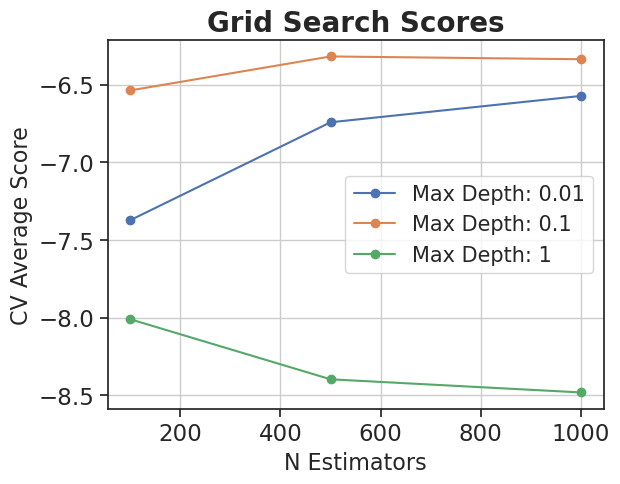

In [555]:
# Calling Method 
plot_grid_search(clf.cv_results_, parameters['n_estimators'], parameters['learning_rate'], 'N Estimators', 'Max Depth')

In [560]:
reg = GradientBoostingRegressor(n_estimators=500)
reg.fit(X=metrics_df[metrics_to_plot + additional_metrics].values, y=metrics_df['temp'])

AttributeError: 'function' object has no attribute 'fit'

Text(0.5, 1.0, 'Regressor Performance')

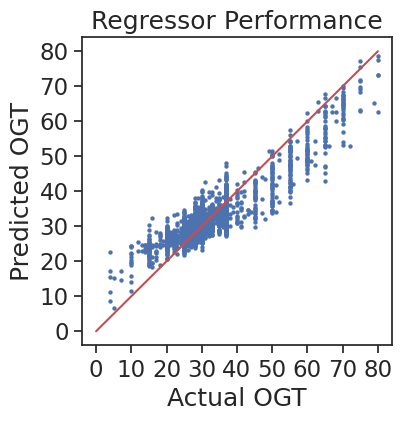

In [559]:
fig, ax = plt.subplots(figsize=(4, 4))
sns.scatterplot(x=metrics_df['temp'], y=clf.best_estimator_.predict(metrics_df[metrics_to_plot + additional_metrics].values), linewidth=0, alpha=1, s=10)
plt.plot((0, 80), (0, 80), color='r')
yticks = ax.set_yticks(list(np.linspace(0, 80, 9)))
xticks = ax.set_xticks(list(np.linspace(0, 80, 9)))
ax.set_xlabel('Actual OGT')
ax.set_ylabel('Predicted OGT')
ax.set_title('Regressor Performance')

In [821]:
spearmanr(metrics_df['temp'], clf.best_estimator_.predict(metrics_df[metrics_to_plot + additional_metrics].values))

SignificanceResult(statistic=0.7400537865984281, pvalue=0.0)

## check density of 37 degree points

In [836]:
corkey = pd.read_csv('/data/mhoffert/fiererlab/ogt/source_data/Corkey_temperatures.csv')
corkey['genus'] = corkey['binomial.name'].apply(lambda x: x.split(' ')[0].lower())
corkey['species'] = corkey['binomial.name'].apply(lambda x: x.split(' ')[1].lower())
corkey.head()

,strain.code,T.C,rate.per.minute,domain,kingdom,phylum,binomial.name,aero,trophy,genus,species
0,1,37.0,0.070729,Bacteria,Bacteria,Proteobacteria,Vibrio natriegens,FA,H,vibrio,natriegens
1,2,65.0,0.002310,Bacteria,Bacteria,Firmicutes,Desulfotomaculum sp.,AN,A,desulfotomaculum,sp.
2,3,28.0,0.001332,Bacteria,Bacteria,Firmicutes,Geobacillus sp.,FA,H,geobacillus,sp.
3,3,35.0,0.003633,Bacteria,Bacteria,Firmicutes,Geobacillus sp.,FA,H,geobacillus,sp.
4,3,40.0,0.004650,Bacteria,Bacteria,Firmicutes,Geobacillus sp.,FA,H,geobacillus,sp.


In [841]:
len(corkey['binomial.name'].unique())

978

In [18]:
base_path = '/data/mhoffert/fiererlab/ogt/results/db/'
corkey_match = pd.read_csv(f'{base_path}corkey_gtdb_matching.tsv', sep='\t')

In [19]:
corkey_match.shape

(541, 8)

In [846]:
corkey_data = pd.merge(corkey, corkey_match[corkey_match['match_accession'].isin(metrics_df.genome)], left_on='binomial.name', right_on='original_id', how='right')

In [851]:
corkey[corkey['binomial.name'].eq('Acaryochloris marina')]

,strain.code,T.C,rate.per.minute,domain,kingdom,phylum,binomial.name,aero,trophy,genus,species
8757,1249,14.966516,0.000020,Bacteria,Bacteria,Cyanobacteria,Acaryochloris marina,A,A,acaryochloris,marina
8758,1249,19.988769,0.000192,Bacteria,Bacteria,Cyanobacteria,Acaryochloris marina,A,A,acaryochloris,marina
8759,1249,24.669116,0.000330,Bacteria,Bacteria,Cyanobacteria,Acaryochloris marina,A,A,acaryochloris,marina
8760,1249,29.806447,0.000369,Bacteria,Bacteria,Cyanobacteria,Acaryochloris marina,A,A,acaryochloris,marina
8761,1249,34.960693,0.000326,Bacteria,Bacteria,Cyanobacteria,Acaryochloris marina,A,A,acaryochloris,marina
8762,1249,40.064333,0.000109,Bacteria,Bacteria,Cyanobacteria,Acaryochloris marina,A,A,acaryochloris,marina


In [859]:
corkey_data.groupby('match_accession').mean(numeric_only=True)['T.C']

match_accession
GB_GCA_003148465.1    56.500000
RS_GCF_000006985.1    43.032331
RS_GCF_000007925.1    18.294701
RS_GCF_000010305.1    30.000000
RS_GCF_000012325.1     9.689690
                        ...    
RS_GCF_004216575.1    27.691363
RS_GCF_004319545.1    30.500000
RS_GCF_004337705.1    49.605819
RS_GCF_004342625.1    44.943216
RS_GCF_004346265.1    40.112400
Name: T.C, Length: 181, dtype: float64

In [860]:
metrics_df['temp']

0       30.0
1       37.0
2       30.0
3       37.0
4       37.0
        ... 
5224    29.0
5225    30.0
5226    37.0
5227    25.0
5228    28.0
Name: temp, Length: 5229, dtype: float64

<Axes: xlabel='T.C', ylabel='temp'>

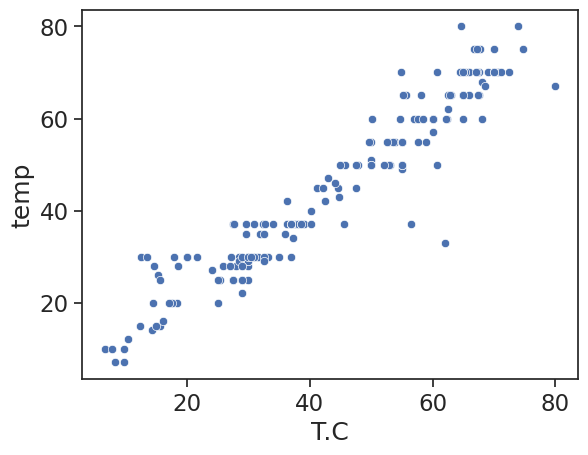

In [861]:
sns.scatterplot(x=corkey_data.groupby('match_accession').mean(numeric_only=True)['T.C'], y=metrics_df.set_index('genome')['temp'])

In [862]:
enqvist_match = pd.read_csv(f'{base_path}engqvist_gtdb_matching.tsv', sep='\t')

In [853]:
corkey_data

,strain.code,T.C,rate.per.minute,domain,kingdom,phylum,binomial.name,aero,trophy,genus,species,Unnamed: 0,original_id,orginal_genus,original_species,match_ratio,match_accession,match_genus,match_species
0,1249,14.966516,0.000020,Bacteria,Bacteria,Cyanobacteria,Acaryochloris marina,A,A,acaryochloris,marina,0,Acaryochloris marina,acaryochloris,marina,100.000000,RS_GCF_000018105.1,acaryochloris,marina
1,1249,19.988769,0.000192,Bacteria,Bacteria,Cyanobacteria,Acaryochloris marina,A,A,acaryochloris,marina,0,Acaryochloris marina,acaryochloris,marina,100.000000,RS_GCF_000018105.1,acaryochloris,marina
2,1249,24.669116,0.000330,Bacteria,Bacteria,Cyanobacteria,Acaryochloris marina,A,A,acaryochloris,marina,0,Acaryochloris marina,acaryochloris,marina,100.000000,RS_GCF_000018105.1,acaryochloris,marina
3,1249,29.806447,0.000369,Bacteria,Bacteria,Cyanobacteria,Acaryochloris marina,A,A,acaryochloris,marina,0,Acaryochloris marina,acaryochloris,marina,100.000000,RS_GCF_000018105.1,acaryochloris,marina
4,1249,34.960693,0.000326,Bacteria,Bacteria,Cyanobacteria,Acaryochloris marina,A,A,acaryochloris,marina,0,Acaryochloris marina,acaryochloris,marina,100.000000,RS_GCF_000018105.1,acaryochloris,marina
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1487,202,5.952222,0.000376,Bacteria,Bacteria,Proteobacteria,Vibrio psychroerythrus,FA,H,vibrio,psychroerythrus,537,Vibrio psychroerythrus,vibrio,psychroerythrus,57.142857,RS_GCF_000012325.1,colwellia,psychrerythraea_a
1488,202,7.092058,0.001074,Bacteria,Bacteria,Proteobacteria,Vibrio psychroerythrus,FA,H,vibrio,psychroerythrus,537,Vibrio psychroerythrus,vibrio,psychroerythrus,57.142857,RS_GCF_000012325.1,colwellia,psychrerythraea_a
1489,202,10.025885,0.001453,Bacteria,Bacteria,Proteobacteria,Vibrio psychroerythrus,FA,H,vibrio,psychroerythrus,537,Vibrio psychroerythrus,vibrio,psychroerythrus,57.142857,RS_GCF_000012325.1,colwellia,psychrerythraea_a
1490,202,11.517551,0.001553,Bacteria,Bacteria,Proteobacteria,Vibrio psychroerythrus,FA,H,vibrio,psychroerythrus,537,Vibrio psychroerythrus,vibrio,psychroerythrus,57.142857,RS_GCF_000012325.1,colwellia,psychrerythraea_a
